# Componente 2 — Efecto del tipo de camión sobre el costo y right-sizing (v2, sobre `data/oro_v2`)

**Universo:** el mismo del Componente 1 (58,275 viajes, egresos ene–ago 2026). **Pregunta central:** si en una misma ruta una carga se mueve a otro tipo de camión, ¿cuánto cambia el costo del viaje? De esa respuesta depende el ahorro del right-sizing.

## 1. DAG: qué causa qué

In [69]:
# Rutas: el notebook vive en analisis_estadistico_IA/, pero data/, config/ y resultados_ternium/ están en la raíz.
# Se trabaja desde la raíz y se agregan las carpetas de código al path para importar sus módulos.
import os, sys
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == 'analisis_estadistico_IA' else Path.cwd()
os.chdir(RAIZ)
for _carpeta in ('analisis_estadistico_IA', 'data_processing'):
    if str(RAIZ / _carpeta) not in sys.path:
        sys.path.insert(0, str(RAIZ / _carpeta))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import statsmodels.formula.api as smf
import importlib, ternium_comun
importlib.reload(ternium_comun)          # si el módulo cambió, el kernel toma la versión nueva sin reiniciar
from ternium_comun import (cargar_universo, aplicar_estilo, titulo, bootstrap_conglomerados, UNIDADES, PLANTA, GRUPO,
                           SUPERFICIE, TINTA, TINTA_2, TINTA_3, REJILLA, SECUENCIAL)
aplicar_estilo()
df = cargar_universo()
df['Programado_t'] = df['Programado_kg'] / 1e3
print(f'Viajes en el universo: {len(df):,}')

Viajes en el universo: 58,275


### 1.1 El grafo

**Tratamiento:** tipo de camión asignado (T). **Resultado:** costo del viaje (C). Cada flecha dice "influye en", y cada una tiene una razón operativa:

| Flecha | Por qué |
|---|---|
| Planta y producto → tipo de camión | Compatibilidad producto–unidad (Largos solo en plataformas; Big Coil en su unidad o en 2/3 ejes). |
| Peso programado → tipo de camión | El asignador elige la unidad para que la carga quepa. |
| Tipo de camión → transportista | Ternium pide la unidad según lo que va a cargar y después los transportistas ofertan camiones de ese tipo (entrevista con Ternium). |
| Planta, destino → transportista | Cada ruta la cubren pocos transportistas (mediana 2 por ruta y tipo). |
| Planta, destino → peso programado | El tamaño del pedido depende del producto y del cliente. |
| Planta, destino → distancia → costo | La tarifa crece con la distancia. |
| Destino → retorno esperado → costo | Si en el destino hay carga de regreso, el transportista puede cobrar menos. |
| Transportista → costo | La tarifa se negocia por transportista × ruta × unidad. |
| Periodo → costo, tipo de camión | Revisiones de tarifa y disponibilidad de flota a lo largo del año. |
| Tipo de camión → costo | **El efecto que queremos medir.** |
| Peso programado → costo | Débil: la tarifa es casi fija por viaje (se verifica abajo). |
| No observado → tipo, costo | Urgencia del pedido, requisitos del cliente y **disponibilidad de unidades**: pueden forzar una unidad y encarecer el viaje. Según la entrevista, a veces la unidad pedida no está disponible y Ternium cancela y pide otra; los datos solo registran la unidad **asignada**, no la pedida, y no existe registro de las cancelaciones. |
| Tipo, peso programado → peso real | El peso de báscula ocurre después de asignar la unidad. |
| Llega de una entrega cercana → tipo, costo | Si el camión ya está cerca porque acaba de entregar, Ternium recibe esa unidad (con su tipo) y la tarifa podría ser menor. Se sabe antes de asignar. |
| Tipo, retorno esperado → consigue retorno | Que el camión consiga carga después del viaje se sabe hasta después. |

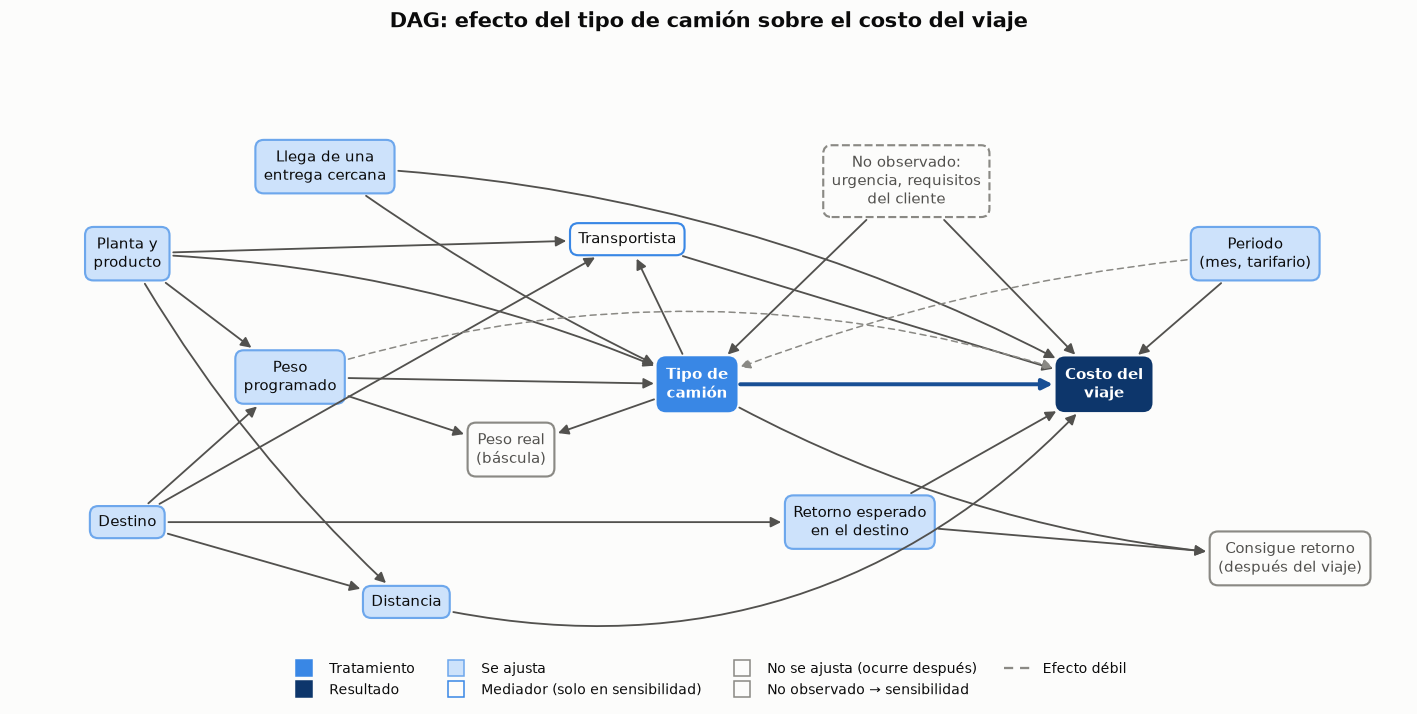

In [70]:
# FIG — DAG
NODOS = {   # clave: (x, y, texto, rol)
    'U': (7.7, 5.6, 'No observado: urgencia,\nrequisitos del cliente,\ndisponibilidad de unidades', 'no_obs'),
    'P': (5.3, 4.8, 'Transportista', 'mediador'),
    'M': (10.7, 4.6, 'Periodo\n(mes, tarifario)', 'ajuste'),
    'O': (1.0, 4.6, 'Planta y\nproducto', 'ajuste'),
    'Q': (2.4, 2.9, 'Peso\nprogramado', 'ajuste'),
    'T': (5.9, 2.8, 'Tipo de camión\n(asignado)', 'trat'),
    'C': (9.4, 2.8, 'Costo del\nviaje', 'res'),
    'D': (1.0, 0.9, 'Destino', 'ajuste'),
    'K': (3.4, -0.2, 'Distancia', 'ajuste'),
    'B': (7.3, 0.9, 'Retorno esperado\nen el destino', 'ajuste'),
    'W': (4.3, 1.9, 'Peso real\n(báscula)', 'no_ajustar'),
    'R': (11.0, 0.4, 'Consigue retorno\n(después del viaje)', 'no_ajustar'),
    'E': (2.7, 5.8, 'Llega de una\nentrega cercana', 'ajuste'),
}
ARISTAS = [('O', 'Q'), ('D', 'Q'), ('O', 'P'), ('D', 'P'), ('O', 'K'), ('D', 'K'), ('D', 'B'), ('O', 'T'),
           ('Q', 'T'), ('T', 'P'), ('U', 'T'), ('U', 'C'), ('K', 'C'), ('B', 'C'), ('P', 'C'), ('M', 'C'),
           ('Q', 'W'), ('T', 'W'), ('T', 'R'), ('B', 'R'), ('E', 'T'), ('E', 'C')]
DEBILES = [('Q', 'C'), ('M', 'T')]
ESTILO_NODO = {
    'trat':       dict(fc=SECUENCIAL[3], ec=SECUENCIAL[3], color='white', ls='-'),
    'res':        dict(fc=SECUENCIAL[6], ec=SECUENCIAL[6], color='white', ls='-'),
    'ajuste':     dict(fc=SECUENCIAL[0], ec=SECUENCIAL[2], color=TINTA, ls='-'),
    'mediador':   dict(fc=SUPERFICIE, ec=SECUENCIAL[3], color=TINTA, ls='-'),
    'no_ajustar': dict(fc=SUPERFICIE, ec=TINTA_3, color=TINTA_2, ls='-'),
    'no_obs':     dict(fc=SUPERFICIE, ec=TINTA_3, color=TINTA_2, ls='--'),
}
fig, ax = plt.subplots(figsize=(13, 6.6))
cajas = {}
for k, (x, y, txt, rol) in NODOS.items():
    e = ESTILO_NODO[rol]
    t = ax.text(x, y, txt, ha='center', va='center', fontsize=10, color=e['color'],
                fontweight='bold' if rol in ('trat', 'res') else 'normal',
                bbox=dict(boxstyle='round,pad=0.55', fc=e['fc'], ec=e['ec'], lw=1.4, ls=e['ls']))
    cajas[k] = t
fig.canvas.draw()
def flecha(a, b, color, lw, ls='-', rad=0.0):
    ax.annotate('', xy=NODOS[b][:2], xytext=NODOS[a][:2],
                arrowprops=dict(arrowstyle='-|>', color=color, lw=lw, ls=ls, mutation_scale=14,
                                patchA=cajas[a].get_bbox_patch(), patchB=cajas[b].get_bbox_patch(),
                                shrinkA=2, shrinkB=2, connectionstyle=f'arc3,rad={rad}'))
CURVAS = {('O', 'T'): -0.1, ('D', 'B'): 0.0, ('K', 'C'): 0.3, ('T', 'R'): 0.12, ('B', 'R'): 0.0, ('M', 'T'): 0.08, ('O', 'K'): 0.08, ('Q', 'C'): -0.17, ('E', 'C'): -0.12, ('E', 'T'): 0.05}
for a, b in ARISTAS:
    flecha(a, b, TINTA_2, 1.2, rad=CURVAS.get((a, b), 0))
for a, b in DEBILES:
    flecha(a, b, TINTA_3, 1.0, ls=(0, (4, 3)), rad=CURVAS.get((a, b), 0.25 if (a, b) == ('Q', 'C') else 0))
flecha('T', 'C', SECUENCIAL[5], 2.6)
ax.set_xlim(0, 12); ax.set_ylim(-0.8, 6.6); ax.axis('off')
ax.legend(handles=[plt.Line2D([], [], marker='s', ls='', ms=11, mfc=ESTILO_NODO[r]['fc'], mec=ESTILO_NODO[r]['ec'],
                              label=l) for r, l in [('trat', 'Tratamiento'), ('res', 'Resultado'),
                                                    ('ajuste', 'Se ajusta'), ('mediador', 'Mediador (solo en sensibilidad)'),
                                                    ('no_ajustar', 'No se ajusta (ocurre después)'),
                                                    ('no_obs', 'No observado → sensibilidad')]]
          + [plt.Line2D([], [], color=TINTA_3, ls=(0, (4, 3)), label='Efecto débil')],
          loc='lower center', bbox_to_anchor=(0.5, -0.12), ncol=4, fontsize=9)
titulo(fig, 'DAG: efecto del tipo de camión sobre el costo del viaje')
plt.show()

### 1.2 Qué se ajusta y qué se estima

**Caminos traseros** (por donde se cuela una asociación que no es efecto del camión): T ← planta/destino → costo (vía distancia y retorno esperado), T ← peso programado → costo, T ← periodo → costo, T ← llega de una entrega cercana → costo, y T ← no observado → costo.

**Conjunto de ajuste** (bloquea todos los caminos traseros observables):
- **Efectos fijos de ruta** (planta × destino). Absorben planta, producto, destino, distancia y retorno esperado: todo lo que es constante en la ruta.
- **Peso programado.**
- **Periodo** (mes).
- **Llega de una entrega cercana** (el viaje es un retorno).

**El transportista es un mediador, no un confusor.** Ternium pide la unidad y después los transportistas ofertan: el camino T → transportista → costo es parte del efecto del camión. Si Ternium pide un 2 ejes en vez de un 3 ejes, es probable que lo atienda otro transportista (cada transportista se especializa en un tipo), y eso también mueve la tarifa. Por eso **no se ajusta por transportista** en la estimación principal.

**Qué se estima.**
- **Principal: efecto total** de cambiar el tipo de camión **dentro de la misma ruta y periodo, con el mismo peso programado**. Es el ahorro que Ternium vería al pedir otra unidad, incluido el cambio de proveedor. Es la misma comparación que usa el right-sizing del Componente 1 (tarifa mediana de la ruta entre todos sus transportistas).
- **Sensibilidad: efecto con el mismo transportista** (ajustando por él). Responde cuánto del efecto viene de la unidad en sí y cuánto de cambiar de proveedor. Hay que leerlo con cuidado: ajustar por un mediador puede sesgar si algo no observado afecta a la vez a qué transportista se contrata y a la tarifa.

**No se ajusta por:** peso real ni utilización (dependen del camión elegido), ni *consigue retorno* (ocurre después del viaje), ni costo por tonelada (se construye con el resultado).

**Lo que el DAG no resuelve:** el factor no observado (urgencia, requisitos del cliente y disponibilidad de unidades). Se trata con análisis de sensibilidad (Cinelli y Hazlett) en la sección de estimación. La disponibilidad tiene además una consecuencia práctica: el ahorro del right-sizing supone que la unidad sugerida se consigue. Se aborda en la optimización (restricción de disponibilidad de flota, sección 6) y en el simulador (escenario de indisponibilidad, sección 7.4). La sección 1.4 busca su huella en los datos.

### 1.3 ¿Los datos son consistentes con el grafo?

Un DAG no se prueba con datos, pero sus flechas tienen consecuencias que sí se pueden revisar. Todas las estimaciones son **dentro de celda** (se resta la media de la celda indicada) con errores estándar agrupados por transportista y ruta (dos vías).

In [71]:
# Propósito: Verificar con datos las flechas del DAG. Todo se estima dentro de celda, con errores agrupados
# por transportista y ruta.
def dentro(d, cols, celda):
    """Resta la media de la celda (equivale a efectos fijos de esa celda)."""
    d = d.copy()
    for c in cols:
        d[c + '_w'] = d[c] - d.groupby(celda)[c].transform('mean')
    return d

def ols_2vias(formula, d):
    """OLS con errores estándar agrupados en dos vías: transportista y ruta."""
    g = np.column_stack([pd.factorize(d['Transportista'])[0], pd.factorize(d['Ruta_ID'])[0]])
    return smf.ols(formula, d).fit(cov_type='cluster', cov_kwds={'groups': g})

def fila(nombre, m, var, esc=1.0, unidad=''):
    """Renglón de la tabla: estimación de `var` con su IC 95 % (multiplicada por `esc`)."""
    lo, hi = m.conf_int().loc[var] * esc
    return {'Flecha': nombre, 'Estimación': f'{m.params[var]*esc:.3f}{unidad} [{lo:.3f}–{hi:.3f}]', 'Viajes': int(m.nobs)}

d = df[(df['Programado_t'] > 0.5) & ~df['Flag_Discrepancia_Peso'].astype(bool)].copy()   # sin pesos programados imposibles
d['Unidad_s'] = d['Unidad'].astype(str)
d['lc'], d['lq'], d['lw'] = np.log(d['Costo']), np.log(d['Programado_t']), np.log(d['Toneladas_Reales'].clip(lower=0.5))
# Celda = ruta × unidad × transportista (donde se negocia la tarifa); se exigen ≥ 5 viajes por celda
d['Celda'] = d['Ruta_ID'] + '|' + d['Unidad_s'] + '|' + d['Transportista']
d = d[d.groupby('Celda')['lc'].transform('size') >= 5]
d['Mes'] = d['FECHA_EGRESO'].dt.month
filas = []

# Peso programado → tipo: en rutas con 2 y 3 ejes, ¿cuánto más pesa la carga que va en 3 ejes?
x = d[d['Unidad_s'].isin(['2 Ejes', '3 Ejes'])].copy()
x = x[x.groupby('Ruta_ID')['Unidad_s'].transform('nunique') == 2]
x['es_3E'] = (x['Unidad_s'] == '3 Ejes').astype(float)
x = dentro(x, ['Programado_t', 'es_3E'], 'Ruta_ID')
filas.append(fila('Peso programado → tipo (t más en 3 ejes que en 2 ejes, misma ruta)',
                  ols_2vias('Programado_t_w ~ es_3E_w - 1', x), 'es_3E_w', unidad=' t'))
# Peso programado → costo: elasticidad dentro de ruta × unidad × transportista × mes
y = dentro(d, ['lc', 'lq', 'lw'], ['Celda', 'Mes'])
filas.append(fila('Peso programado → costo (elasticidad, misma celda y mes)', ols_2vias('lc_w ~ lq_w - 1', y), 'lq_w'))
# Peso real → costo dado el programado: no debería haber efecto (la tarifa se fija antes de pesar)
filas.append(fila('Peso real → costo, dado el programado (esperado ≈ 0)', ols_2vias('lc_w ~ lq_w + lw_w - 1', y), 'lw_w'))
# Periodo → costo: cambio de tarifa jun–ago contra ene–abr, dentro de la misma celda
z = d[d['Mes'] != 5].copy(); z['post'] = (z['Mes'] >= 6).astype(float)
z = dentro(z, ['lc', 'post'], 'Celda')
m_periodo = ols_2vias('lc_w ~ post_w - 1', z)
filas.append(fila('Periodo → costo (% jun–ago vs. ene–abr, misma celda)', m_periodo, 'post_w', esc=100, unidad=' %'))
# Periodo → tipo: ¿cambia la mezcla 2 ejes / 3 ejes entre periodos dentro de la ruta?
x2 = d[d['Unidad_s'].isin(['2 Ejes', '3 Ejes']) & (d['Mes'] != 5)].copy()
x2['es_2E'] = (x2['Unidad_s'] == '2 Ejes').astype(float); x2['post'] = (x2['Mes'] >= 6).astype(float)
x2 = dentro(x2, ['es_2E', 'post'], 'Ruta_ID')
filas.append(fila('Periodo → tipo (pp de viajes en 2 ejes, jun–ago vs. ene–abr, misma ruta)',
                  ols_2vias('es_2E_w ~ post_w - 1', x2), 'post_w', esc=100, unidad=' pp'))
print('Consecuencias verificables del DAG (IC 95 %, errores agrupados por transportista y ruta)')
display(pd.DataFrame(filas).set_index('Flecha'))

# Tipo → transportista: si Ternium pide la unidad y los transportistas ofertan, cada transportista debería especializarse
tp = pd.crosstab(d['Transportista'], d['Unidad_s'])
print(f"Tipo → transportista: {(tp.gt(0).sum(1) == 1).sum()} de {len(tp)} transportistas operan un solo tipo; "
      f"{(tp.max(1).sum() / tp.values.sum()):.0%} de los viajes van en el tipo principal de su transportista.")
# Positividad del efecto total: ¿en cuántas rutas coexisten varios tipos?
nt = d.groupby('Ruta_ID')['Unidad_s'].nunique()
print(f"Positividad: {(nt > 1).sum()} de {len(nt)} rutas tienen más de un tipo y concentran "
      f"{d['Ruta_ID'].map(nt).gt(1).mean():.0%} de los viajes. El efecto total se identifica solo en esas rutas.")
rt = d.groupby(['Ruta_ID', 'Transportista'])['Unidad_s'].nunique()
print(f"Con transportista fijo (sensibilidad) solo {(rt > 1).mean():.0%} de las combinaciones ruta × transportista "
      'usan más de un tipo: ese efecto descansa en mucha menos información.')

Consecuencias verificables del DAG (IC 95 %, errores agrupados por transportista y ruta)


,Estimación,Viajes
Flecha,,
"Peso programado → tipo (t más en 3 ejes que en 2 ejes, misma ruta)",7.538 t [7.011–8.066],21464
"Peso programado → costo (elasticidad, misma celda y mes)",0.026 [0.009–0.043],49202
"Peso real → costo, dado el programado (esperado ≈ 0)",0.180 [-0.088–0.447],49202
"Periodo → costo (% jun–ago vs. ene–abr, misma celda)",3.213 % [1.792–4.635],42476
"Periodo → tipo (pp de viajes en 2 ejes, jun–ago vs. ene–abr, misma ruta)",-1.668 pp [-4.807–1.472],37196


Tipo → transportista: 81 de 117 transportistas operan un solo tipo; 84% de los viajes van en el tipo principal de su transportista.
Positividad: 175 de 600 rutas tienen más de un tipo y concentran 69% de los viajes. El efecto total se identifica solo en esas rutas.
Con transportista fijo (sensibilidad) solo 10% de las combinaciones ruta × transportista usan más de un tipo: ese efecto descansa en mucha menos información.


/var/folders/2g/lzkw6wx57k5fk4j7x71sq2sr0000gn/T/ipykernel_78607/1908865892.py:52: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  print(f"Tipo → transportista: {(tp.gt(0).sum(1) == 1).sum()} de {len(tp)} transportistas operan un solo tipo; "
/var/folders/2g/lzkw6wx57k5fk4j7x71sq2sr0000gn/T/ipykernel_78607/1908865892.py:53: Pandas4Warning: Starting with pandas version 4.0 all arguments of max will be keyword-only.
  f"{(tp.max(1).sum() / tp.values.sum()):.0%} de los viajes van en el tipo principal de su transportista.")


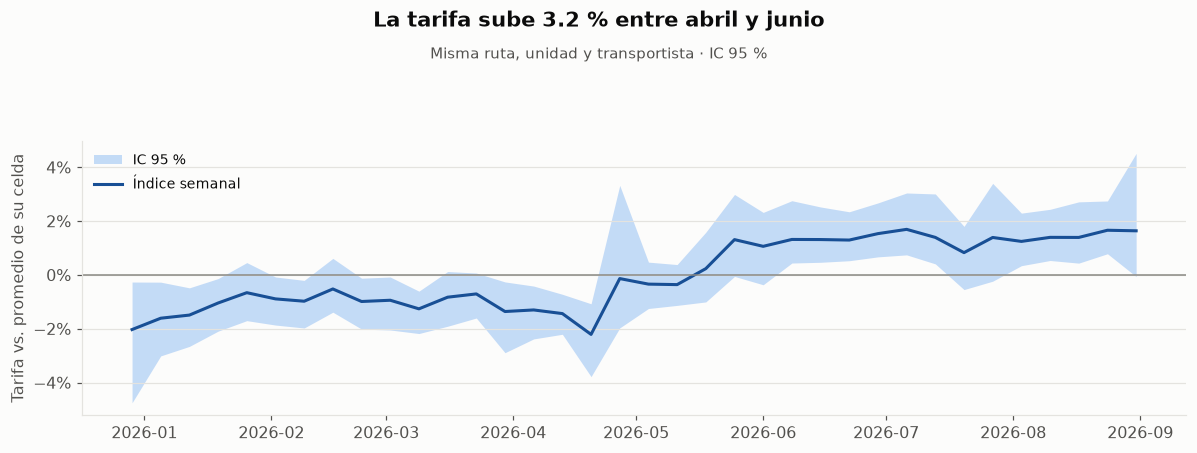

In [72]:
# FIG — índice semanal de tarifa dentro de ruta × unidad × transportista (sustenta Periodo → costo)
s_ = dentro(d, ['lc'], 'Celda')                     # solo dentro de celda: aquí sí se deja variar el tiempo
s_['Semana'] = s_['FECHA_EGRESO'].dt.to_period('W').dt.start_time
idx = bootstrap_conglomerados(s_.assign(dev=s_['lc_w'] * 100), ['Semana'], {'dev': 'dev'}, {'i': ('dev', 'n')}, B=1000).sort_index()
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.fill_between(idx.index, idx['i_inf'], idx['i_sup'], color=SECUENCIAL[1], alpha=0.6, lw=0, label='IC 95 %')
ax.plot(idx.index, idx['i'], color=SECUENCIAL[5], lw=2, label='Índice semanal')
ax.axhline(0, color=TINTA_3, lw=1)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylabel('Tarifa vs. promedio de su celda'); ax.grid(axis='x', visible=False)
ax.legend(loc='upper left', fontsize=9)
titulo(fig, f"La tarifa sube {m_periodo.params['post_w']*100:.1f} % entre abril y junio", 'Misma ruta, unidad y transportista · IC 95 %')
plt.show()

**Lectura.**
- **Peso programado → tipo:** confirmada. En una misma ruta, la carga que va en 3 ejes pesa ~7.5 t más que la que va en 2 ejes.
- **Peso programado → costo:** existe pero es débil (elasticidad ≈ 0.03: 10 % más de peso, 0.3 % más de costo). Por eso es flecha punteada; igual se ajusta.
- **Peso real → costo, dado el programado:** no se distingue de cero, como predice el grafo (la tarifa se fija antes de pesar). La prueba tiene poca potencia porque el peso real coincide con el programado en la gran mayoría de los viajes.
- **Periodo → costo:** confirmada. La tarifa de una misma celda sube ~3 % entre ene–abr y jun–ago, con el cambio concentrado entre finales de abril y mayo. Por eso el mes entra al ajuste. Parece una revisión de tarifas para parte de los transportistas y rutas: hay que preguntar a Ternium cuándo y por qué ocurrió.
- **Periodo → tipo:** no se detecta. Queda como flecha débil.
- **Tipo → transportista:** consistente con la entrevista. 84 % de los viajes van en el tipo principal de su transportista: cada transportista oferta la unidad que tiene, así que pedir otra unidad suele implicar otro proveedor.
- **Positividad:** el efecto total se puede estimar en las rutas donde coexisten varios tipos (la mayoría de los viajes). El efecto con transportista fijo descansa en ~10 % de las combinaciones ruta × transportista: por eso queda solo como sensibilidad. Ambas cosas se revisan a detalle en la estimación.

### 1.4 Unidad pedida contra unidad asignada

Si Ternium pide un 2 ejes y no hay, recibe otra unidad (normalmente un 3 ejes). No hay registro de esas cancelaciones, pero dejarían huella: viajes en 3 ejes con cargas que cabrían en un 2 ejes, en rutas donde lo normal es el 2 ejes. Se revisa (1) cuántos son, (2) si aumentan en semanas de más demanda en la planta (cuando es más probable que falten unidades) y (3) si cuestan más que los demás 3 ejes de la ruta (recargo por urgencia). Si fueran frecuentes y caros, sesgarían el efecto de 2 contra 3 ejes.

In [ ]:
# Propósito: Buscar la huella de la indisponibilidad: 3 ejes con carga de 2 ejes en rutas de 2 ejes, su relación con
# la demanda semanal de la planta y su costo frente a los demás 3 ejes de la ruta.
x = d[d['Unidad_s'].isin(['2 Ejes', '3 Ejes'])].copy()
x['Semana'] = x['FECHA_EGRESO'].dt.to_period('W').astype(str)
part_2e = x.groupby('Ruta_ID')['Unidad_s'].apply(lambda s_: (s_ == '2 Ejes').mean())
n_ruta = x.groupby('Ruta_ID').size()
rutas_2e = part_2e[(part_2e >= 0.6) & (n_ruta >= 20)].index           # rutas donde lo normal es el 2 ejes
y_ = x[x['Ruta_ID'].isin(rutas_2e)].copy()
y_['sust'] = ((y_['Unidad_s'] == '3 Ejes') & (y_['Programado_t'] <= 26)).astype(float)   # 3 ejes con carga de 2 ejes
sem_pl = d.assign(Semana=d['FECHA_EGRESO'].dt.to_period('W').astype(str)).groupby([PLANTA, 'Semana']).size().rename('n_sem')
y_ = y_.join(sem_pl, on=[PLANTA, 'Semana'])
y_['presion'] = np.log(y_['n_sem'] / y_.groupby(PLANTA)['n_sem'].transform('mean'))  # semana cargada vs. promedio de la planta
w_ = dentro(y_, ['sust', 'presion'], 'Ruta_ID')
m_p = ols_2vias('sust_w ~ presion_w - 1', w_)
z_ = y_[y_['Unidad_s'] == '3 Ejes'].copy()
z_['lc'] = np.log(z_['Costo'])
w2_ = dentro(z_, ['lc', 'sust'], ['Ruta_ID', 'Mes'])
m_c = ols_2vias('lc_w ~ sust_w - 1', w2_)
f15 = np.log(1.5) * 100
print(f"Rutas donde lo normal es el 2 ejes: {len(rutas_2e)}; viajes en 3 ejes con ≤ 26 t: {int(y_['sust'].sum())} "
      f"({y_['sust'].mean():.1%} de los viajes de esas rutas)")
print(f"Semana con 50 % más viajes en la planta → {m_p.params['presion_w'] * f15:+.2f} pp en esos viajes "
      f"[{m_p.conf_int().loc['presion_w', 0] * f15:+.2f}, {m_p.conf_int().loc['presion_w', 1] * f15:+.2f}]")
print(f"Costo de esos 3 ejes frente a los demás 3 ejes de la misma ruta y mes: {np.expm1(m_c.params['sust_w']):+.1%} "
      f"[{np.expm1(m_c.conf_int().loc['sust_w', 0]):+.1%}, {np.expm1(m_c.conf_int().loc['sust_w', 1]):+.1%}]")

**Lectura.** Las posibles sustituciones son pocas (1.5 % de los viajes en rutas de 2 ejes), no aumentan de forma detectable en las semanas de más demanda (+0.3 pp, IC que incluye 0) y no cuestan significativamente más que los demás 3 ejes de la ruta (+3.6 %, IC de −1.5 % a +8.9 %). Son pruebas indirectas, porque la disponibilidad no se observa, pero no hay señal de que la indisponibilidad sesgue el efecto de 2 contra 3 ejes. Donde sí importa es en el **ahorro**: el right-sizing supone que el 2 ejes pedido se consigue. Por eso la optimización limita la disponibilidad de flota (sección 6) y el simulador evalúa qué pasa si una parte de las solicitudes no se surte (sección 7.4).

## 2. Retorno: ¿el camión vuelve con carga de Ternium?

No hay un registro del viaje de regreso; hay que reconstruirlo siguiendo cada placa en el tiempo. Hay un problema previo: **`FECHA_VIAJE_FINALIZADO` no marca la llegada física**. En 37 % de los casos la misma placa sale a su siguiente viaje *antes* de esa fecha, y 5 % de los viajes "duran" más de 14 días. Parece un cierre administrativo (entrega de evidencias). Por eso los ciclos se reconstruyen solo con **fechas de egreso** y la geografía.

Para cada viaje *j* se toma el viaje anterior *i* de la misma placa:
- **Ciclo posible:** el camión pudo recorrer la ruta de *i* y llegar al origen de *j* entre los dos egresos, a no más de 80 km/h promedio. Si no (14 % de los pares), la placa no identifica a un solo camión físico y el par se descarta.
- **Es retorno:** el ciclo es posible, *j* sale de una planta a ≤ 100 km del destino de *i*, esa planta está a > 100 km del origen de *i* (si no, el camión solo volvió a su base) y el egreso ocurre a lo más 48 h después del tiempo mínimo del ciclo (a 60 km/h).
- **Consigue retorno:** el siguiente viaje de la placa *es retorno*.

En el DAG son cosas distintas. *Es retorno* se conoce **antes** de asignar la unidad (el camión ya está ahí, con su tipo) y puede abaratar la tarifa: es un **confusor** y se ajusta. *Consigue retorno* ocurre **después**: no puede causar la tarifa del viaje actual, así que sirve como **control negativo**.

In [73]:
# Propósito: Reconstruir los ciclos de cada placa con fechas de egreso y coordenadas. Marca qué viajes son
# retorno (Es_retorno: se sabe antes de asignar → confusor) y cuáles consiguen retorno después
# (Consigue_retorno: ocurre después → control negativo).
from ternium_comun import ORO, VENTANA
from distancias_v2 import clave

FACTOR_CARRETERA, V_MAX, V_TIPICA = 1.252, 80, 60         # factor calibrado en distancias_v2; km/h
RADIO_KM, HOLGURA_H = 100, 48

def haversine(lat1, lon1, lat2, lon2):
    """Distancia en línea recta (km) entre dos puntos; acepta arreglos."""
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

# Coordenadas de plantas y destinos (mismas tablas que distancias_v2.py)
geo = pd.read_csv('data/distancias_v2/cache_geocodificacion.csv').drop_duplicates('clave', keep='last').set_index('clave')
geo = geo[geo['estatus'].isin(['ok', 'ambiguo'])]
pl = pd.read_csv('config/plantas.csv'); de = pd.read_csv('config/destinos_canonicos.csv')
pl_k = dict(zip(pl['PLANTA_ORIGEN'], [clave(c, e) for c, e in zip(pl['Ciudad'], pl['Estado'])]))
de_k = dict(zip(de['Destino_Crudo'], [clave(c, e) for c, e in zip(de['Destino_Limpio'], de['Estado'])]))

# Todas las placas de la ventana (incluye unidades fuera del universo: el ciclo es del camión, no del análisis)
todos = pd.read_csv(ORO, low_memory=False, parse_dates=['FECHA_EGRESO'])
todos = todos[(todos['FECHA_EGRESO'] >= VENTANA[0]) & (todos['FECHA_EGRESO'] < VENTANA[1])]
todos = todos[['ID_VIAJE', 'Placas', 'PLANTA_ORIGEN', 'Ciudad Destino', 'FECHA_EGRESO', 'Kilometros_Ruta']].copy()
for pre, col, mapa in [('o', 'PLANTA_ORIGEN', pl_k), ('d', 'Ciudad Destino', de_k)]:
    k = todos[col].map(mapa)
    todos[f'{pre}_lat'], todos[f'{pre}_lon'] = k.map(geo['lat']).astype(float), k.map(geo['lon']).astype(float)
todos = todos.sort_values(['Placas', 'FECHA_EGRESO'])
# Viaje anterior de la misma placa (en orden cronológico)
ant = todos.groupby('Placas')[['FECHA_EGRESO', 'Kilometros_Ruta', 'o_lat', 'o_lon', 'd_lat', 'd_lon']].shift(1)
todos['gap_h'] = (todos['FECHA_EGRESO'] - ant['FECHA_EGRESO']).dt.total_seconds() / 3600
todos['dist_dest_ant'] = haversine(ant['d_lat'], ant['d_lon'], todos['o_lat'], todos['o_lon'])      # destino anterior → origen actual
todos['dist_origen_ant'] = haversine(ant['o_lat'], ant['o_lon'], todos['o_lat'], todos['o_lon'])    # origen anterior → origen actual
# Km mínimos del ciclo: ruta del viaje anterior + traslado de su destino al origen actual (línea recta × factor)
km_ciclo = ant['Kilometros_Ruta'] + todos['dist_dest_ant'] * FACTOR_CARRETERA
todos['Ciclo_medible'] = todos['gap_h'].gt(0) & km_ciclo.notna()
todos['Ciclo_imposible'] = todos['Ciclo_medible'] & (km_ciclo / todos['gap_h'] > V_MAX)
todos['Es_retorno'] = (todos['Ciclo_medible'] & ~todos['Ciclo_imposible']
                       & (todos['dist_dest_ant'] <= RADIO_KM) & (todos['dist_origen_ant'] > RADIO_KM)
                       & (todos['gap_h'] <= km_ciclo / V_TIPICA + HOLGURA_H))
todos['Consigue_retorno'] = todos.groupby('Placas')['Es_retorno'].shift(-1).fillna(False).astype(bool)
todos['Sig_imposible'] = todos.groupby('Placas')['Ciclo_imposible'].shift(-1).fillna(False).astype(bool)

# Se pegan las marcas al universo (se borran antes por si la celda se corre dos veces)
df = df.drop(columns=[c for c in ['Es_retorno', 'Consigue_retorno', 'Ciclo_imposible', 'Sig_imposible'] if c in df.columns])
df = df.merge(todos[['ID_VIAJE', 'Es_retorno', 'Consigue_retorno', 'Ciclo_imposible', 'Sig_imposible']], on='ID_VIAJE', how='left')
print(f"Pares de viajes consecutivos con ciclo imposible (placa ≠ camión único): {todos.loc[todos['Ciclo_medible'], 'Ciclo_imposible'].mean():.1%}")
print(f"Viajes del universo que son retorno: {df['Es_retorno'].mean():.1%}; que consiguen retorno: {df['Consigue_retorno'].mean():.1%}")
display((df.groupby(df['Unidad'].astype(str))[['Es_retorno', 'Consigue_retorno']].mean() * 100).round(1)
          .reindex(UNIDADES).rename(columns={'Es_retorno': '% es retorno', 'Consigue_retorno': '% consigue retorno'}))

Pares de viajes consecutivos con ciclo imposible (placa ≠ camión único): 14.4%
Viajes del universo que son retorno: 1.0%; que consiguen retorno: 1.0%


,% es retorno,% consigue retorno
Unidad,,
Torton,0.0,0.0
2 Ejes,0.4,0.1
Caja Seca 2 Ejes,0.0,0.0
3 Ejes,1.5,1.5
Big Coil,0.0,0.0
Full,0.4,5.2


**Lectura.** Volver con carga de Ternium es raro: ~1 % de los viajes (1–2.6 % al variar el radio a 150–200 km y la holgura hasta 10 días). Incluso cuando el destino queda cerca de otra planta de Ternium (32 % de los viajes), solo ~3 % de esos camiones regresa con carga de Ternium. Los pocos retornos se concentran en dos corredores: **Largos Puebla ↔ Largos Apodaca** y **Pesquería ↔ CSI San Luis Potosí**. El resto de los camiones regresa vacío o con carga de terceros; los datos no permiten distinguir entre esas dos.

## 3. Efecto del tipo de camión sobre el costo

**Diseño.** Se estima por **pares de unidades** (alternativa contra unidad actual) porque cada par corresponde a un movimiento de right-sizing, y así la positividad se impone por construcción: cada par se estima **solo en las rutas donde ambas unidades operan** (≥ 5 viajes cada una).

$$\log C_{i} = \beta\,\text{Alternativa}_i + \gamma \log Q_i + \delta\,\text{Es retorno}_i + \text{mes}_i + \alpha_{\text{ruta}(i)} + \varepsilon_i$$

- β: diferencia de costo (en log) de ir en la unidad alternativa, en la misma ruta y mes, con el mismo peso programado. El efecto en % es e^β − 1.
- Efectos fijos de ruta (α), mes, peso programado y *es retorno*: el conjunto de ajuste del DAG.
- Errores estándar agrupados por transportista y ruta (dos vías).
- **Sensibilidad (mediador):** la misma regresión con efectos fijos de ruta × transportista, que compara las dos unidades **dentro del mismo transportista**.

### 3.1 Positividad: ¿dónde coexisten las unidades?

In [74]:
# Propósito: Preparar la muestra de estimación (log del costo y del peso, dummies de mes) y medir el soporte
# común de cada par de unidades: en cuántas rutas operan las dos.
d = df[(df['Programado_t'] > 0.5) & ~df['Flag_Discrepancia_Peso'].astype(bool)].copy()
d['Unidad_s'] = d['Unidad'].astype(str)
d['lc'], d['lq'] = np.log(d['Costo']), np.log(d['Programado_t'])
d['Mes'] = d['FECHA_EGRESO'].dt.month
d['Es_retorno'] = d['Es_retorno'].fillna(False).astype(float)
d['Consigue_retorno'] = d['Consigue_retorno'].fillna(False).astype(float)
# Dummies de mes (enero es la categoría base)
MESES = [f'm{m}' for m in range(2, 9)]
for m in range(2, 9):
    d[f'm{m}'] = (d['Mes'] == m).astype(float)

# Pares (alternativa, actual): cada uno corresponde a un movimiento de right-sizing
PARES = [('2 Ejes', '3 Ejes'), ('2 Ejes', 'Big Coil'), ('3 Ejes', 'Big Coil'), ('2 Ejes', 'Torton'), ('Full', '3 Ejes')]
N_MIN = 5

def muestra_par(alt, act, data=d):
    """Viajes de las dos unidades en rutas donde ambas tienen ≥ N_MIN viajes (soporte común)."""
    x = data[data['Unidad_s'].isin([alt, act])]
    n = x.groupby(['Ruta_ID', 'Unidad_s']).size().unstack(fill_value=0)
    rutas = n.index[(n.get(alt, 0) >= N_MIN) & (n.get(act, 0) >= N_MIN)]
    x = x[x['Ruta_ID'].isin(rutas)].copy()
    x['D'] = (x['Unidad_s'] == alt).astype(float)
    return x

pos = []
for alt, act in PARES:
    x = muestra_par(alt, act)
    pos.append({'Par (alternativa vs. actual)': f'{alt} vs. {act}', 'Rutas con ambas': x['Ruta_ID'].nunique(),
                'Viajes': len(x),
                f'% de los viajes de la unidad actual cubiertos': round(len(x[x['D'] == 0]) / (d['Unidad_s'] == act).sum() * 100, 1)})
print('Soporte común por par de unidades (rutas con ≥ 5 viajes de cada una)')
display(pd.DataFrame(pos).set_index('Par (alternativa vs. actual)'))

Soporte común por par de unidades (rutas con ≥ 5 viajes de cada una)


,Rutas con ambas,Viajes,% de los viajes de la unidad actual cubiertos
Par (alternativa vs. actual),,,
2 Ejes vs. 3 Ejes,207,27942,47.8
2 Ejes vs. Big Coil,9,3526,44.9
3 Ejes vs. Big Coil,14,11772,99.0
2 Ejes vs. Torton,17,795,24.1
Full vs. 3 Ejes,9,3327,7.2


### 3.2 Estimación

In [75]:
# Propósito: Para cada par de unidades, efecto de ir en la alternativa sobre el log del costo (efectos fijos de
# ruta, mes, peso programado y es retorno) y su sensibilidad con el mismo transportista.
def within(x, cols, fe):
    """Resta la media de cada grupo `fe` (equivale a efectos fijos)."""
    x = x.copy()
    for c in cols:
        x[c] = x[c] - x.groupby(fe)[c].transform('mean')
    return x

def estimar(x, fe, extra=()):
    """Regresión dentro de `fe`: modelo con errores de dos vías, OLS clásico, grados de libertad y datos transformados."""
    cols = ['lc', 'D', 'lq', 'Es_retorno', *MESES, *extra]
    w = within(x, cols, fe)
    rhs = ' + '.join(['D', 'lq', 'Es_retorno', *MESES, *extra])
    g = np.column_stack([pd.factorize(w['Transportista'])[0], pd.factorize(w['Ruta_ID'])[0]])
    m_cl = smf.ols(f'lc ~ {rhs} - 1', w).fit(cov_type='cluster', cov_kwds={'groups': g})
    m_ols = smf.ols(f'lc ~ {rhs} - 1', w).fit()                      # para la sensibilidad (Cinelli y Hazlett)
    gl = len(w) - w.groupby(fe).ngroups - len(m_ols.params)
    return m_cl, m_ols, gl, w

res, modelos = [], {}
for alt, act in PARES:
    x = muestra_par(alt, act)
    m, m_ols, gl, w = estimar(x, ['Ruta_ID'])
    # Sensibilidad: efectos fijos de ruta y transportista (compara dentro del mismo transportista)
    m_tr, *_ = estimar(x, ['Ruta_ID', 'Transportista'])
    b, (lo, hi) = m.params['D'], m.conf_int().loc['D']
    bt, (lot, hit) = m_tr.params['D'], m_tr.conf_int().loc['D']
    # Para pasar el % a pesos: costo mediano del viaje en la unidad actual
    c_act = x.loc[x['D'] == 0, 'Costo'].median()
    modelos[(alt, act)] = dict(m=m, m_ols=m_ols, gl=gl, w=w, x=x)
    res.append({'Par': f'{alt} vs. {act}', 'Rutas': x['Ruta_ID'].nunique(), 'Viajes': len(x),
                'ef': np.expm1(b), 'ef_inf': np.expm1(lo), 'ef_sup': np.expm1(hi),
                'mxn': np.expm1(b) * c_act, 'mxn_inf': np.expm1(lo) * c_act, 'mxn_sup': np.expm1(hi) * c_act,
                'ef_tr': np.expm1(bt), 'ef_tr_inf': np.expm1(lot), 'ef_tr_sup': np.expm1(hit)})
res = pd.DataFrame(res).set_index('Par')
print('Efecto de ir en la unidad alternativa sobre el costo del viaje (misma ruta, mes y peso programado; IC 95 %)')
display(pd.DataFrame({
    'Rutas': res['Rutas'], 'Viajes': res['Viajes'],
    'Efecto total [IC 95%]': res.apply(lambda r: f"{r.ef:+.1%} [{r.ef_inf:+.1%}, {r.ef_sup:+.1%}]", axis=1),
    'MXN por viaje [IC 95%]': res.apply(lambda r: f"{r.mxn:+,.0f} [{r.mxn_inf:+,.0f}, {r.mxn_sup:+,.0f}]", axis=1),
    'Mismo transportista [IC 95%]': res.apply(lambda r: f"{r.ef_tr:+.1%} [{r.ef_tr_inf:+.1%}, {r.ef_tr_sup:+.1%}]", axis=1),
}))
m = modelos[('2 Ejes', '3 Ejes')]['m']
print(f"Peso programado (elasticidad, par 2 vs. 3 ejes): {m.params['lq']:.3f} [{m.conf_int().loc['lq', 0]:.3f}, {m.conf_int().loc['lq', 1]:.3f}]; "
      f"es retorno: {np.expm1(m.params['Es_retorno']):+.1%} [{np.expm1(m.conf_int().loc['Es_retorno', 0]):+.1%}, "
      f"{np.expm1(m.conf_int().loc['Es_retorno', 1]):+.1%}]")

/var/folders/2g/lzkw6wx57k5fk4j7x71sq2sr0000gn/T/ipykernel_78607/2167561331.py:12: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m_cl = smf.ols(f'lc ~ {rhs} - 1', w).fit(cov_type='cluster', cov_kwds={'groups': g})
/var/folders/2g/lzkw6wx57k5fk4j7x71sq2sr0000gn/T/ipykernel_78607/2167561331.py:13: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m_ols = smf.ols(f'lc ~ {rhs} - 1', w).fit()                      # para la sensibilidad (Cinelli y Hazlett)
/var/folders/2g/lzkw6wx57k5fk4j7x71sq2sr0000gn/T/ipykernel_78607/2167561331.py:12: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m_cl = smf.ols(f'lc ~ {rhs} - 1', w).fit(cov_type='cluster', cov_kwds={'groups': g})
/var/folders/2g/lzkw6wx57k5fk4j7x71sq2sr0000gn/T/ipykernel_78607/2167561331.py:13: SingularMatrixWarning: The design matrix is rank-defic

Efecto de ir en la unidad alternativa sobre el costo del viaje (misma ruta, mes y peso programado; IC 95 %)


,Rutas,Viajes,Efecto total [IC 95%],MXN por viaje [IC 95%],Mismo transportista [IC 95%]
Par,,,,,
2 Ejes vs. 3 Ejes,207,27942,"-20.8% [-24.2%, -17.2%]","-5,177 [-6,030, -4,284]","-26.2% [-27.9%, -24.6%]"
2 Ejes vs. Big Coil,9,3526,"-28.8% [-33.1%, -24.2%]","-6,893 [-7,934, -5,784]","-26.3% [-30.5%, -21.9%]"
3 Ejes vs. Big Coil,14,11772,"-9.5% [-12.2%, -6.7%]","-1,210 [-1,558, -852]","-0.8% [-2.7%, +1.1%]"
2 Ejes vs. Torton,17,795,"-1.3% [-19.4%, +21.0%]","-155 [-2,364, +2,552]","-7.7% [-24.9%, +13.3%]"
Full vs. 3 Ejes,9,3327,"+21.5% [+9.3%, +35.2%]","+6,985 [+3,002, +11,416]","+31.4% [+19.8%, +44.1%]"


Peso programado (elasticidad, par 2 vs. 3 ejes): 0.045 [0.022, 0.068]; es retorno: -4.1% [-7.7%, -0.3%]


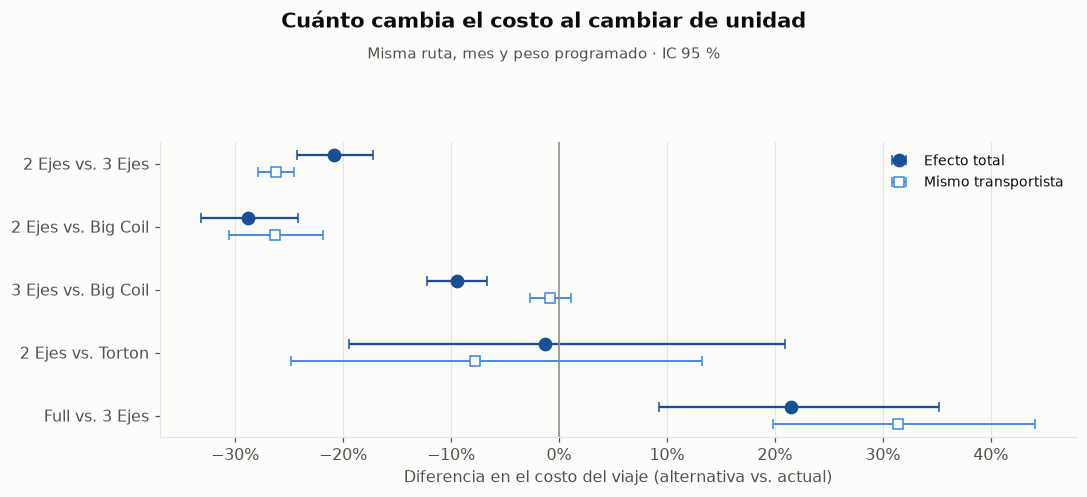

In [76]:
# FIG — efecto por par de unidades: total vs. mismo transportista
r = res.iloc[::-1]
y = np.arange(len(r))
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.errorbar(r['ef'] * 100, y + 0.13, xerr=[(r['ef'] - r['ef_inf']) * 100, (r['ef_sup'] - r['ef']) * 100],
            fmt='o', ms=8, color=SECUENCIAL[5], ecolor=SECUENCIAL[5], elinewidth=1.5, capsize=3, label='Efecto total')
ax.errorbar(r['ef_tr'] * 100, y - 0.13, xerr=[(r['ef_tr'] - r['ef_tr_inf']) * 100, (r['ef_tr_sup'] - r['ef_tr']) * 100],
            fmt='s', ms=7, mfc=SUPERFICIE, mec=SECUENCIAL[3], color=SECUENCIAL[3], elinewidth=1.2, capsize=3,
            label='Mismo transportista')
ax.axvline(0, color=TINTA_3, lw=1)
ax.set_yticks(y, r.index); ax.grid(axis='y', visible=False)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel('Diferencia en el costo del viaje (alternativa vs. actual)')
ax.legend(loc='upper right', fontsize=9)
titulo(fig, 'Cuánto cambia el costo al cambiar de unidad', 'Misma ruta, mes y peso programado · IC 95 %')
plt.show()

### 3.3 ¿Qué tan fuerte tendría que ser un confusor omitido? (Cinelli y Hazlett, 2020)

El DAG deja abierto un factor no observado (urgencia, requisitos del cliente). Para cada par se reporta:
- **RV**: fracción de la varianza residual, del tratamiento y del costo, que un confusor omitido tendría que explicar para llevar el efecto a cero. **RV (α = 0.05)**: la necesaria para que el IC deje de excluir el cero.
- **Comparación contra el peso programado**, el confusor observado más fuerte (es lo que más determina qué unidad se pide). Se calcula el efecto que quedaría si existiera un confusor 1 y 3 veces tan fuerte como él.

Se usan los errores estándar clásicos del modelo (como en el método original); los IC de la tabla anterior, agrupados, son más amplios.

In [77]:
# Propósito: Sensibilidad de Cinelli y Hazlett: qué tan fuerte tendría que ser un confusor omitido para borrar el efecto.
from scipy import stats

def rv(t, gl, alfa=None):
    """Valor de robustez (RV). Con `alfa`, el necesario para que el IC deje de excluir el cero."""
    f = abs(t) / np.sqrt(gl)
    if alfa is not None:
        f = f - stats.t.ppf(1 - alfa / 2, gl - 1) / np.sqrt(gl - 1)
        if f <= 0: return 0.0
    return 0.5 * (np.sqrt(f ** 4 + 4 * f ** 2) - f ** 2)

def ajustado_por_benchmark(mod, var, k):
    """Efecto si existiera un confusor k veces tan fuerte como `var` (con el tratamiento y con el costo)."""
    w, m_ols, gl = mod['w'], mod['m_ols'], mod['gl']
    otros = [c for c in m_ols.params.index if c not in ('D', var)]
    md = smf.ols(f"D ~ {' + '.join([var] + otros)} - 1", w).fit()
    t_d = md.tvalues[var]; r2dxj = t_d ** 2 / (t_d ** 2 + md.df_resid)
    t_y = m_ols.tvalues[var]; r2yxj = t_y ** 2 / (t_y ** 2 + gl)
    r2dz = k * r2dxj / (1 - r2dxj)
    if r2dz >= 1: return None          # un confusor así explicaría más del 100 % del tratamiento: no puede existir
    r2zxj = k * r2dxj ** 2 / ((1 - k * r2dxj) * (1 - r2dxj))
    r2yz = min(1.0, ((np.sqrt(k) + np.sqrt(r2zxj)) / np.sqrt(1 - r2zxj)) ** 2 * (r2yxj / (1 - r2yxj)))
    sesgo = m_ols.bse['D'] * np.sqrt(gl) * np.sqrt(r2yz * r2dz / (1 - r2dz))
    b = m_ols.params['D']
    return np.expm1(np.sign(b) * max(abs(b) - sesgo, 0))

sens = []
for (alt, act), mod in modelos.items():
    m_ols, gl = mod['m_ols'], mod['gl']
    t = m_ols.tvalues['D']
    sens.append({'Par': f'{alt} vs. {act}', 'Efecto': f"{np.expm1(m_ols.params['D']):+.1%}",
                 'R² parcial del tratamiento': f'{t**2 / (t**2 + gl):.1%}',
                 'RV': f'{rv(t, gl):.1%}', 'RV (α = 0.05)': f'{rv(t, gl, 0.05):.1%}',
                 **{f'Si confusor = {k}× peso programado': (lambda v: 'no puede existir' if v is None else f'{v:+.1%}')(
                     ajustado_por_benchmark(mod, 'lq', k)) for k in (1, 3)}})
print('Sensibilidad a un confusor omitido ("no puede existir": explicaría más del 100 % de la elección de unidad)')
display(pd.DataFrame(sens).set_index('Par'))

Sensibilidad a un confusor omitido ("no puede existir": explicaría más del 100 % de la elección de unidad)


/var/folders/2g/lzkw6wx57k5fk4j7x71sq2sr0000gn/T/ipykernel_78607/2198484824.py:14: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  md = smf.ols(f"D ~ {' + '.join([var] + otros)} - 1", w).fit()
/var/folders/2g/lzkw6wx57k5fk4j7x71sq2sr0000gn/T/ipykernel_78607/2198484824.py:14: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  md = smf.ols(f"D ~ {' + '.join([var] + otros)} - 1", w).fit()


,Efecto,R² parcial del tratamiento,RV,RV (α = 0.05),Si confusor = 1× peso programado,Si confusor = 3× peso programado
Par,,,,,,
2 Ejes vs. 3 Ejes,-20.8%,26.3%,44.5%,43.9%,-18.0%,no puede existir
2 Ejes vs. Big Coil,-28.8%,63.5%,71.0%,70.2%,-25.4%,no puede existir
3 Ejes vs. Big Coil,-9.5%,11.2%,29.7%,28.4%,-9.1%,-8.2%
2 Ejes vs. Torton,-1.3%,0.0%,1.1%,0.0%,no puede existir,no puede existir
Full vs. 3 Ejes,+21.5%,6.5%,23.1%,20.5%,no puede existir,no puede existir


### 3.4 Retorno y control negativo

- **Es retorno** (el camión llega de una entrega cercana): ¿ese viaje sale más barato que los demás de la misma ruta y unidad?
- **Consigue retorno** (control negativo): que el camión consiga carga después del viaje no puede abaratar la tarifa de un viaje que ya se cotizó. Si aparece un efecto, hay algo que el modelo no está capturando (por ejemplo, rutas o semanas con condiciones de mercado particulares).

In [78]:
# Propósito: ¿Llegar de una entrega cercana abarata el viaje? Incluye el control negativo (conseguir retorno después
# no debería abaratarlo). Efectos fijos de ruta × unidad; errores agrupados por transportista y ruta.
z = d.copy()
z['D'] = 0.0
w = within(z, ['lc', 'lq', 'Es_retorno', 'Consigue_retorno', *MESES], ['Ruta_ID', 'Unidad_s'])
g = np.column_stack([pd.factorize(w['Transportista'])[0], pd.factorize(w['Ruta_ID'])[0]])
m_ret = smf.ols(f"lc ~ lq + Es_retorno + Consigue_retorno + {' + '.join(MESES)} - 1", w).fit(
    cov_type='cluster', cov_kwds={'groups': g})
filas = []
for v, nombre in [('Es_retorno', 'Es retorno (llega de una entrega cercana)'), ('Consigue_retorno', 'Consigue retorno (control negativo; esperado ≈ 0)')]:
    lo, hi = m_ret.conf_int().loc[v]
    filas.append({'Variable': nombre, 'Viajes con la condición': int(d[v].sum()),
                  'Efecto en el costo [IC 95%]': f"{np.expm1(m_ret.params[v]):+.1%} [{np.expm1(lo):+.1%}, {np.expm1(hi):+.1%}]"})
print('Retorno y costo del viaje (misma ruta, unidad y mes; IC 95 % agrupado por transportista y ruta)')
display(pd.DataFrame(filas).set_index('Variable'))
# Mismo análisis dentro del transportista: ¿el control negativo se explica por quién hace los retornos?
w2 = within(z, ['lc', 'lq', 'Es_retorno', 'Consigue_retorno', *MESES], ['Ruta_ID', 'Unidad_s', 'Transportista'])
g2 = np.column_stack([pd.factorize(w2['Transportista'])[0], pd.factorize(w2['Ruta_ID'])[0]])
m_ret_tr = smf.ols(f"lc ~ lq + Es_retorno + Consigue_retorno + {' + '.join(MESES)} - 1", w2).fit(
    cov_type='cluster', cov_kwds={'groups': g2})
for v in ['Es_retorno', 'Consigue_retorno']:
    lo, hi = m_ret_tr.conf_int().loc[v]
    print(f"  {v} con el mismo transportista: {np.expm1(m_ret_tr.params[v]):+.1%} [{np.expm1(lo):+.1%}, {np.expm1(hi):+.1%}]")
t_ret = d.loc[d['Consigue_retorno'] > 0, 'Transportista'].value_counts()
print(f"  Los retornos los hacen {len(t_ret)} transportistas; los 3 principales concentran {t_ret.head(3).sum() / t_ret.sum():.0%}.")

Retorno y costo del viaje (misma ruta, unidad y mes; IC 95 % agrupado por transportista y ruta)


,Viajes con la condición,Efecto en el costo [IC 95%]
Variable,,
Es retorno (llega de una entrega cercana),604,"-2.1% [-4.3%, +0.3%]"
Consigue retorno (control negativo; esperado ≈ 0),601,"-3.2% [-5.8%, -0.5%]"


  Es_retorno con el mismo transportista: +0.3% [-0.3%, +0.8%]
  Consigue_retorno con el mismo transportista: -0.8% [-1.4%, -0.2%]
  Los retornos los hacen 23 transportistas; los 3 principales concentran 60%.


### 3.5 Lectura

- **2 ejes vs. 3 ejes** (el movimiento principal del right-sizing): en la misma ruta, mes y peso programado, el viaje en 2 ejes cuesta **~21 % menos** [17–24 %], unos 5,200 MXN por viaje. Con el mismo transportista la diferencia es aún mayor (~26 %). Es robusto: un confusor omitido tendría que explicar ~44 % de la varianza residual de la elección de unidad y del costo para borrarlo, y uno tan fuerte como el peso programado lo dejaría en ~18 %. Uno 3 veces más fuerte no puede existir: explicaría más del 100 % de la elección.
- **Big Coil → 2 ejes:** ~29 % más barato, también robusto, pero solo en 9 rutas (las de Pesquería y Churubusco donde coexisten).
- **Big Coil → 3 ejes:** ~10 % más barato en el efecto total, pero **~0 % con el mismo transportista**. La diferencia viene de que el 3 ejes lo dan transportistas más baratos, no de la unidad en sí. Como Ternium no controla la asignación de transportista, este ahorro es menos seguro.
- **Torton → 2 ejes:** no se distingue de cero (IC de −19 % a +21 %; 17 rutas, 795 viajes). La sugerencia de cambiar Torton por 2 ejes en CEDIS **no tiene respaldo estadístico** con estos datos.
- **3 ejes → Full:** el Full cuesta ~22 % más por viaje, pero lleva ~32 % más capacidad: por tonelada sale más barato si va lleno.
- **Positividad:** las conclusiones valen solo donde las unidades coexisten. Para 2 vs. 3 ejes eso cubre 48 % de los viajes en 3 ejes; para Full vs. 3 ejes, solo 7 %.
- **Retorno:** llegar de una entrega cercana no abarata el viaje de forma detectable (−2 % sin significancia; +0.3 % con el mismo transportista). Respuesta a la pregunta original: con estos datos, **el retorno no mueve la tarifa**.
- **Control negativo (falla parcialmente):** conseguir retorno después del viaje aparece asociado a −3 % en la tarifa, cuando debería ser 0. Con el mismo transportista baja a −0.8 %: casi todo se explica porque los retornos los hacen pocos transportistas que además son más baratos. Lección: hay factores no ajustados (transportista, momento) que mueven la tarifa del orden de 1–3 %. Es un orden de magnitud menor que el efecto de 2 vs. 3 ejes, así que esa conclusión sobrevive; para efectos pequeños (Big Coil → 3 ejes, Torton → 2 ejes) no se puede descartar que sean artefactos.

## 4. Robustez y falsificación

El objetivo es intentar tumbar la conclusión central: **en la misma ruta, un 2 ejes cuesta ~21 % menos que un 3 ejes y ~29 % menos que un Big Coil**. Se revisan los dos pares que sostienen casi todo el ahorro del right-sizing.

### 4.1 Robustez frente a decisiones razonables

Las decisiones más discutibles del análisis, y una alternativa razonable para cada una:

| Decisión | Base | Alternativa |
|---|---|---|
| Soporte común | ≥ 5 viajes de cada unidad en la ruta | ≥ 2 y ≥ 20 |
| Variable de peso | Peso programado (lo que se conoce al decidir) | Peso real de báscula |
| Limpieza | Se excluyen pesos programados imposibles | Se incluyen |
| Distancia | Todas las rutas | Solo rutas con km confiable |
| Periodo | Ene–ago | Sin mayo (mes del cambio de tarifa) |
| Forma funcional | Costo en logaritmo (efecto en %) | Costo en pesos (efecto en MXN, convertido a % del costo de la unidad actual) |

In [79]:
# Propósito: Robustez. Se reestima el efecto de los dos pares clave bajo variantes razonables del análisis.
d_todo = df[df['Programado_t'] > 0.5].copy()                 # incluye pesos programados marcados como discrepancia
for c, v in [('Unidad_s', d_todo['Unidad'].astype(str)), ('lc', np.log(d_todo['Costo'])),
             ('lq', np.log(d_todo['Programado_t'])), ('lw', np.log(d_todo['Toneladas_Reales'].clip(lower=0.5))),
             ('Mes', d_todo['FECHA_EGRESO'].dt.month)]:
    d_todo[c] = v
d_todo['Es_retorno'] = d_todo['Es_retorno'].fillna(False).astype(float)
for m in range(2, 9):
    d_todo[f'm{m}'] = (d_todo['Mes'] == m).astype(float)
d_todo['Discrepancia'] = d_todo['Flag_Discrepancia_Peso'].astype(bool)
d = d_todo[~d_todo['Discrepancia']].copy()                   # misma muestra base que la sección 3

def efecto(data, alt, act, n_min=N_MIN, peso='lq', y='lc', fe=('Ruta_ID',)):
    """Efecto de la unidad alternativa (en %) con IC 95 % de dos vías, sobre el soporte común del par."""
    x = data[data['Unidad_s'].isin([alt, act])]
    n = x.groupby(['Ruta_ID', 'Unidad_s']).size().unstack(fill_value=0)
    if alt not in n or act not in n: return None
    x = x[x['Ruta_ID'].isin(n.index[(n[alt] >= n_min) & (n[act] >= n_min)])].copy()
    if x['Ruta_ID'].nunique() < 2: return None
    x['D'] = (x['Unidad_s'] == alt).astype(float)
    meses = [m for m in MESES if x[m].std() > 0]
    cov = [c for c in [peso, 'Es_retorno'] if c] + meses
    w = within(x, [y, 'D', *cov], list(fe))
    g = np.column_stack([pd.factorize(w['Transportista'])[0], pd.factorize(w['Ruta_ID'])[0]])
    m = smf.ols(f"{y} ~ {' + '.join(['D'] + cov)} - 1", w).fit(cov_type='cluster', cov_kwds={'groups': g})
    b, (lo, hi) = m.params['D'], m.conf_int().loc['D']
    if y == 'lc':
        ef = np.expm1([b, lo, hi])
    else:                                                     # niveles: MXN → % del costo medio de la unidad actual
        ef = np.array([b, lo, hi]) / x.loc[x['D'] == 0, y].mean()
    return {'ef': ef[0], 'inf': ef[1], 'sup': ef[2], 'rutas': x['Ruta_ID'].nunique(), 'viajes': len(x),
            'transp': x['Transportista'].nunique()}

PARES_CLAVE = [('2 Ejes', '3 Ejes'), ('2 Ejes', 'Big Coil')]
VARIANTES = {
    'Base': dict(data=d),
    'Soporte: ≥ 2 viajes por unidad': dict(data=d, n_min=2),
    'Soporte: ≥ 20 viajes por unidad': dict(data=d, n_min=20),
    'Peso real en vez de programado': dict(data=d, peso='lw'),
    'Incluye pesos programados imposibles': dict(data=d_todo),
    'Solo rutas con km confiable': dict(data=d[d['Km_Confiable'].astype(bool)]),
    'Sin mayo (cambio de tarifa)': dict(data=d[d['Mes'] != 5]),
    'Costo en pesos (no en log)': dict(data=d, y='Costo'),
}
rob = {(v, f'{a} vs. {b}'): efecto(alt=a, act=b, **kw) for v, kw in VARIANTES.items() for a, b in PARES_CLAVE}
tabla_rob = pd.DataFrame({par: {v: (f"{r['ef']:+.1%} [{r['inf']:+.1%}, {r['sup']:+.1%}] · {r['rutas']} rutas" if r else '—')
                                for (v, p), r in rob.items() if p == par}
                          for par in [f'{a} vs. {b}' for a, b in PARES_CLAVE]})
print('Efecto sobre el costo del viaje bajo cada variante (IC 95 %, dos vías)')
display(tabla_rob)

/var/folders/2g/lzkw6wx57k5fk4j7x71sq2sr0000gn/T/ipykernel_78607/652599116.py:24: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m = smf.ols(f"{y} ~ {' + '.join(['D'] + cov)} - 1", w).fit(cov_type='cluster', cov_kwds={'groups': g})
/var/folders/2g/lzkw6wx57k5fk4j7x71sq2sr0000gn/T/ipykernel_78607/652599116.py:24: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m = smf.ols(f"{y} ~ {' + '.join(['D'] + cov)} - 1", w).fit(cov_type='cluster', cov_kwds={'groups': g})
/Users/andresitoortiz/Desktop/TEC_Concentracion/Reto_Ternium/notebook_entrega1/.venv/lib/python3.13/site-packages/statsmodels/regression/linear_model.py:2121: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(np.diag(self.cov_params()))
/var/folders/2g/lzkw6wx57k5fk4j7x71sq2sr0000gn/T/ipykernel_78607/652599116.py:24: SingularMatrixWarning: The design matrix is rank-deficient. The model 

Efecto sobre el costo del viaje bajo cada variante (IC 95 %, dos vías)


/var/folders/2g/lzkw6wx57k5fk4j7x71sq2sr0000gn/T/ipykernel_78607/652599116.py:24: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m = smf.ols(f"{y} ~ {' + '.join(['D'] + cov)} - 1", w).fit(cov_type='cluster', cov_kwds={'groups': g})
/var/folders/2g/lzkw6wx57k5fk4j7x71sq2sr0000gn/T/ipykernel_78607/652599116.py:24: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m = smf.ols(f"{y} ~ {' + '.join(['D'] + cov)} - 1", w).fit(cov_type='cluster', cov_kwds={'groups': g})


,2 Ejes vs. 3 Ejes,2 Ejes vs. Big Coil
Base,"-20.8% [-24.2%, -17.2%] · 207 rutas","-28.8% [-33.1%, -24.2%] · 9 rutas"
Soporte: ≥ 2 viajes por unidad,"-20.9% [-24.3%, -17.3%] · 333 rutas","-28.9% [-33.2%, -24.2%] · 14 rutas"
Soporte: ≥ 20 viajes por unidad,"-20.6% [-24.2%, -16.8%] · 80 rutas","-29.3% [-33.7%, -24.6%] · 5 rutas"
Peso real en vez de programado,"-20.8% [-24.2%, -17.2%] · 207 rutas","-28.8% [-33.1%, -24.1%] · 9 rutas"
Incluye pesos programados imposibles,"-21.1% [-24.5%, -17.5%] · 211 rutas","-28.7% [-33.1%, -24.1%] · 9 rutas"
Solo rutas con km confiable,"-20.9% [-24.3%, -17.4%] · 200 rutas","-28.8% [-33.1%, -24.2%] · 9 rutas"
Sin mayo (cambio de tarifa),"-20.6% [-24.2%, -16.9%] · 192 rutas","-28.8% [-33.4%, -24.0%] · 8 rutas"
Costo en pesos (no en log),"-30.9% [-37.9%, -23.9%] · 207 rutas","-29.0% [-31.0%, -27.1%] · 9 rutas"


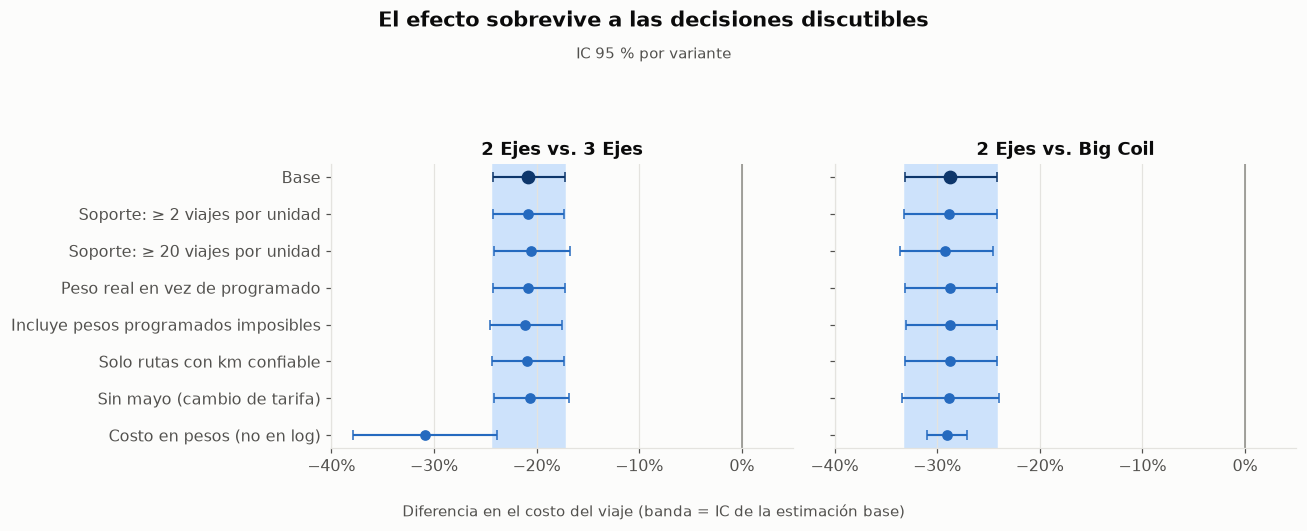

In [80]:
# FIG — robustez: el efecto bajo cada variante
fig, axs = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
etqs = list(VARIANTES)[::-1]
for ax, (a, b) in zip(axs, PARES_CLAVE):
    par = f'{a} vs. {b}'
    for yy, v in enumerate(etqs):
        r = rob[(v, par)]
        if r is None: continue
        base = v == 'Base'
        ax.errorbar(r['ef'] * 100, yy, xerr=[[(r['ef'] - r['inf']) * 100], [(r['sup'] - r['ef']) * 100]],
                    fmt='o', ms=8 if base else 6, color=SECUENCIAL[6] if base else SECUENCIAL[4],
                    elinewidth=1.4, capsize=3)
    rb = rob[('Base', par)]
    ax.axvspan(rb['inf'] * 100, rb['sup'] * 100, color=SECUENCIAL[0], zorder=0)
    ax.axvline(0, color=TINTA_3, lw=1)
    ax.set_title(par); ax.set_yticks(range(len(etqs)), etqs); ax.grid(axis='y', visible=False)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.set_xlim(min(-40, ax.get_xlim()[0]), 5); ax.xaxis.set_major_locator(mtick.MultipleLocator(10))
fig.supxlabel('Diferencia en el costo del viaje (banda = IC de la estimación base)', fontsize=10, color=TINTA_2)
titulo(fig, 'El efecto sobrevive a las decisiones discutibles', 'IC 95 % por variante')
plt.show()

### 4.2 Falsificación

Tres pruebas que, si salieran mal, obligarían a abandonar la conclusión:

1. **Replicación en un subperiodo no usado.** Se estima con ene–jun y se verifica con jul–ago por separado. Si el efecto fuera un artefacto de cierta época o de cierta mezcla de viajes, no se replicaría.
2. **Estabilidad mes a mes.** El efecto estimado en cada mes por separado.
3. **Placebo por permutación.** Dentro de cada ruta se baraja al azar qué viajes son "2 ejes" (500 veces). Si el método fabricara diferencias, aparecerían también con etiquetas falsas. El efecto real tiene que quedar fuera de esa distribución.

Además, la sección 3.4 ya reportó un **control negativo** (*consigue retorno*), que falló parcialmente con un sesgo de 1–3 %.

In [81]:
# Propósito: Falsificación: replicación ene–jun vs. jul–ago, estimación mes a mes y placebo por permutación.
fals = []
for a, b in PARES_CLAVE:
    par = f'{a} vs. {b}'
    for nombre, sub in [('Ene–jun (estimación)', d[d['Mes'] <= 6]), ('Jul–ago (replicación)', d[d['Mes'] >= 7])]:
        r = efecto(sub, a, b)
        ic = (f"[{r['inf']:+.1%}, {r['sup']:+.1%}]" if np.isfinite(r['inf'])
              else f"IC no estimable ({r['transp']} transportistas)")
        fals.append({'Par': par, 'Periodo': nombre, 'Efecto [IC 95%]': f"{r['ef']:+.1%} {ic}",
                     'Rutas': r['rutas'], 'Viajes': r['viajes']})
print('Replicación temporal')
display(pd.DataFrame(fals).set_index(['Par', 'Periodo']))

# Efecto estimado en cada mes por separado (para la figura siguiente)
por_mes = {(f'{a} vs. {b}', m): efecto(d[d['Mes'] == m], a, b) for a, b in PARES_CLAVE for m in range(1, 9)}

# Placebo por permutación (FWL: se residualiza el costo y la etiqueta sobre los controles; se baraja dentro de cada ruta)
def placebo(alt, act, R=500, semilla=2026):
    x = muestra_par(alt, act)
    cov = ['lq', 'Es_retorno'] + [m for m in MESES if x[m].std() > 0]
    w = within(x, ['lc', 'D', *cov], ['Ruta_ID'])
    X = w[cov].values
    X_pinv = np.linalg.pinv(X)                                  # k × n: residualizar sin formar la matriz n × n
    resid = lambda v: v - X @ (X_pinv @ v)
    y = resid(w['lc'].values)
    ruta = pd.factorize(x['Ruta_ID'])[0]
    n_ruta = np.bincount(ruta)
    def beta(dv):
        dv = dv - (np.bincount(ruta, dv) / n_ruta)[ruta]         # efectos fijos de ruta
        dv = resid(dv)
        return dv @ y / (dv @ dv)
    b_real = beta(x['D'].values)
    rng = np.random.default_rng(semilla)
    bloque = ruta
    orden_bloque = np.argsort(bloque, kind='stable')
    D_ord = x['D'].values[orden_bloque]
    dist = []
    for _ in range(R):
        perm = np.lexsort((rng.random(len(x)), bloque))         # orden aleatorio dentro de cada ruta
        dv = np.empty(len(x)); dv[perm] = D_ord
        dist.append(beta(dv))
    dist = np.array(dist)
    return b_real, dist

plac = {}
for a, b in PARES_CLAVE:
    b_real, dist = placebo(a, b)
    plac[f'{a} vs. {b}'] = (b_real, dist)
    print(f"Placebo {a} vs. {b}: efecto real {np.expm1(b_real):+.1%}; con etiquetas barajadas: media {np.expm1(dist.mean()):+.2%}, "
          f"P2.5–P97.5 [{np.expm1(np.percentile(dist, 2.5)):+.2%}, {np.expm1(np.percentile(dist, 97.5)):+.2%}]; "
          f"p = {(np.abs(dist) >= abs(b_real)).mean():.3f} (500 permutaciones)")

Replicación temporal


/var/folders/2g/lzkw6wx57k5fk4j7x71sq2sr0000gn/T/ipykernel_78607/652599116.py:24: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m = smf.ols(f"{y} ~ {' + '.join(['D'] + cov)} - 1", w).fit(cov_type='cluster', cov_kwds={'groups': g})
/var/folders/2g/lzkw6wx57k5fk4j7x71sq2sr0000gn/T/ipykernel_78607/652599116.py:24: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m = smf.ols(f"{y} ~ {' + '.join(['D'] + cov)} - 1", w).fit(cov_type='cluster', cov_kwds={'groups': g})
/var/folders/2g/lzkw6wx57k5fk4j7x71sq2sr0000gn/T/ipykernel_78607/652599116.py:24: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m = smf.ols(f"{y} ~ {' + '.join(['D'] + cov)} - 1", w).fit(cov_type='cluster', cov_kwds={'groups': g})
/Users/andresitoortiz/Desktop/TEC_Concentracion/Reto_Ternium/notebook_entrega1/.venv/lib/python3.13/site-pack

Efecto [IC 95%]  \
Par                 Periodo                                                             
2 Ejes vs. 3 Ejes   Ene–jun (estimación)                      -19.7% [-23.4%, -15.8%]   
                    Jul–ago (replicación)                     -25.2% [-28.1%, -22.3%]   
2 Ejes vs. Big Coil Ene–jun (estimación)                      -27.6% [-32.9%, -21.9%]   
                    Jul–ago (replicación)  -32.3% IC no estimable (14 transportistas)   

                                           Rutas  Viajes  
Par                 Periodo                               
2 Ejes vs. 3 Ejes   Ene–jun (estimación)     183   20867  
                    Jul–ago (replicación)     67    3268  
2 Ejes vs. Big Coil Ene–jun (estimación)       9    2697  
                    Jul–ago (replicación)      3     740

/var/folders/2g/lzkw6wx57k5fk4j7x71sq2sr0000gn/T/ipykernel_78607/652599116.py:24: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m = smf.ols(f"{y} ~ {' + '.join(['D'] + cov)} - 1", w).fit(cov_type='cluster', cov_kwds={'groups': g})
/var/folders/2g/lzkw6wx57k5fk4j7x71sq2sr0000gn/T/ipykernel_78607/652599116.py:24: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m = smf.ols(f"{y} ~ {' + '.join(['D'] + cov)} - 1", w).fit(cov_type='cluster', cov_kwds={'groups': g})
/var/folders/2g/lzkw6wx57k5fk4j7x71sq2sr0000gn/T/ipykernel_78607/652599116.py:24: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m = smf.ols(f"{y} ~ {' + '.join(['D'] + cov)} - 1", w).fit(cov_type='cluster', cov_kwds={'groups': g})
/Users/andresitoortiz/Desktop/TEC_Concentracion/Reto_Ternium/notebook_entrega1/.venv/lib/python3.13/site-pack

Placebo 2 Ejes vs. 3 Ejes: efecto real -20.8%; con etiquetas barajadas: media +0.00%, P2.5–P97.5 [-0.48%, +0.44%]; p = 0.000 (500 permutaciones)
Placebo 2 Ejes vs. Big Coil: efecto real -28.8%; con etiquetas barajadas: media +0.03%, P2.5–P97.5 [-1.10%, +1.06%]; p = 0.000 (500 permutaciones)


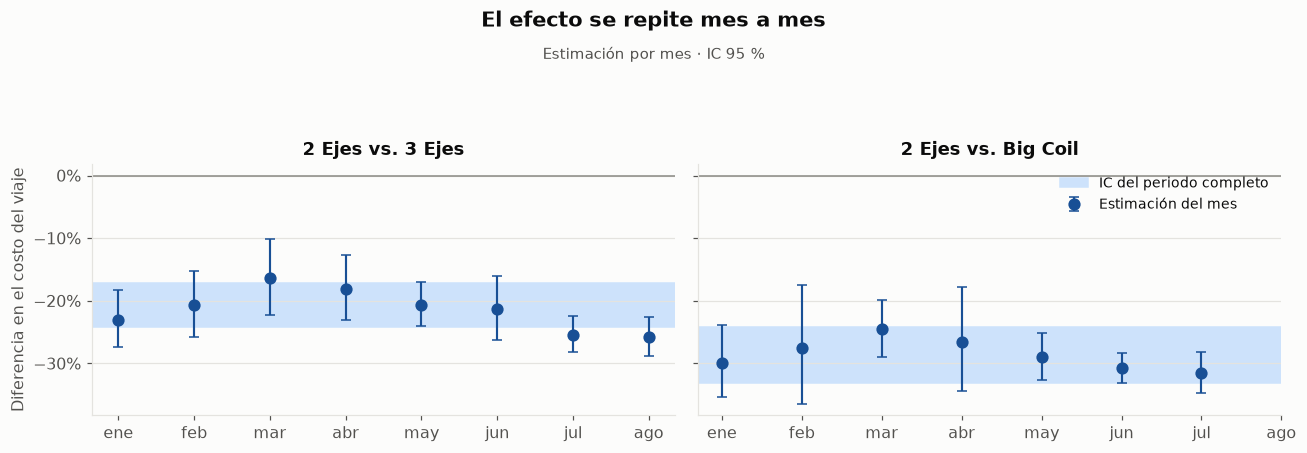

In [82]:
# FIG — estabilidad mes a mes
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, (a, b) in zip(axs, PARES_CLAVE):
    par = f'{a} vs. {b}'
    ms = [m for m in range(1, 9) if por_mes[(par, m)] and np.isfinite(por_mes[(par, m)]['inf'])]
    e = np.array([[por_mes[(par, m)][k] for k in ('ef', 'inf', 'sup')] for m in ms]) * 100
    rb = rob[('Base', par)]
    ax.axhspan(rb['inf'] * 100, rb['sup'] * 100, color=SECUENCIAL[0], zorder=0, label='IC del periodo completo')
    ax.errorbar(ms, e[:, 0], yerr=[e[:, 0] - e[:, 1], e[:, 2] - e[:, 0]], fmt='o', ms=7, color=SECUENCIAL[5],
                elinewidth=1.4, capsize=3, label='Estimación del mes')
    ax.axhline(0, color=TINTA_3, lw=1)
    ax.set_xticks(range(1, 9), ['ene', 'feb', 'mar', 'abr', 'may', 'jun', 'jul', 'ago'])
    ax.set_title(par); ax.grid(axis='x', visible=False)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
axs[0].set_ylabel('Diferencia en el costo del viaje')
axs[1].legend(loc='upper right', fontsize=9)
titulo(fig, 'El efecto se repite mes a mes', 'Estimación por mes · IC 95 %')
plt.show()

### 4.3 Supuesto de efecto homogéneo

El modelo resume con un solo número una diferencia que puede variar entre rutas. Si en muchas rutas el 2 ejes fuera más caro, el promedio escondería casos donde el right-sizing pierde dinero. Para cada ruta del par 2 vs. 3 ejes se calcula la diferencia de tarifas medianas (2 ejes − 3 ejes).

In [83]:
# Propósito: ¿El efecto es igual en todas las rutas? Diferencia de tarifas medianas por ruta y % de rutas donde
# la alternativa es más barata.
het = []
for a, b in PARES_CLAVE:
    x = muestra_par(a, b)
    med = x.groupby(['Ruta_ID', 'Unidad_s'])['Costo'].median().unstack()
    rr = np.log(med[a] / med[b])
    n_r = x.groupby('Ruta_ID').size().reindex(rr.index)
    rng = np.random.default_rng(2026)
    # IC del % de rutas donde la alternativa es más barata: bootstrap de rutas
    boot = [np.mean(rng.choice(rr.values, len(rr)) < 0) for _ in range(2000)]
    q = np.expm1(np.percentile(rr, [10, 50, 90]))
    het.append({'Par': f'{a} vs. {b}', 'Rutas': len(rr),
                '% de rutas donde la alternativa es más barata [IC 95%]': f"{(rr < 0).mean():.0%} [{np.percentile(boot, 2.5):.0%}–{np.percentile(boot, 97.5):.0%}]",
                'Diferencia por ruta: P10 / mediana / P90': f'{q[0]:+.0%} / {q[1]:+.0%} / {q[2]:+.0%}',
                'Viajes en rutas donde es más cara': f"{n_r[rr >= 0].sum():,} ({n_r[rr >= 0].sum() / n_r.sum():.0%})"})
display(pd.DataFrame(het).set_index('Par'))

,Rutas,% de rutas donde la alternativa es más barata [IC 95%],Diferencia por ruta: P10 / mediana / P90,Viajes en rutas donde es más cara
Par,,,,
2 Ejes vs. 3 Ejes,207,91% [87%–95%],-34% / -23% / -4%,"5,837 (21%)"
2 Ejes vs. Big Coil,9,89% [67%–100%],-36% / -25% / -5%,88 (2%)


### 4.4 Lectura

- **Robustez:** en las siete variantes en logaritmo, el efecto de 2 vs. 3 ejes queda entre −20.6 % y −21.1 %, y el de 2 ejes vs. Big Coil entre −28.7 % y −29.3 %, siempre dentro del IC de la estimación base. En pesos el efecto de 2 vs. 3 ejes es mayor (−31 %): la diferencia en MXN pesa más en las rutas largas y caras, así que el ahorro en dinero puede ser mayor de lo que sugiere el porcentaje.
- **Replicación temporal:** el efecto de 2 vs. 3 ejes aparece en ene–jun (−20 %) y se replica en jul–ago (−25 %). La replicación es algo más fuerte, consistente con que la revisión de tarifas de mayo subió más al 3 ejes. Para 2 ejes vs. Big Coil la replicación da el mismo orden (−32 %), aunque con tan pocas rutas su IC no se puede calcular.
- **Mes a mes:** las ocho estimaciones mensuales de 2 vs. 3 ejes son negativas y ninguna incluye el cero.
- **Placebo:** con etiquetas barajadas al azar dentro de cada ruta, el efecto se centra en 0 (rango ±0.5 % para 2 vs. 3 ejes); el efecto real (−21 %) queda muy lejos (p < 0.002 con 500 permutaciones). El método no fabrica diferencias.
- **Efecto homogéneo:** el 2 ejes es más barato en 91 % [87–95 %] de las rutas donde coexiste con el 3 ejes. Pero en el 9 % restante está 21 % de los viajes del par: el promedio es sólido, y aun así el right-sizing debe decidirse **ruta por ruta** con la tarifa observada (como ya hace la regla del Componente 1), no aplicando un descuento promedio a todas.
- **Lo que no sobrevivió:** el control negativo de la sección 3.4 mostró sesgos de 1–3 % por factores no ajustados. Por eso solo se sostienen los efectos grandes (2 ejes contra 3 ejes o Big Coil); los efectos chicos (Big Coil → 3 ejes, Torton → 2 ejes) no se pueden afirmar.

## 5. Modelo que recrea la elección de unidad de Ternium

**Para qué.** Ternium pide la unidad según lo que va a cargar. Un modelo que reproduzca esa decisión sirve para tres cosas: (1) medir qué tan sistemática es la política actual, (2) ser la "política actual" del simulador y (3) señalar decisiones atípicas, que son candidatas naturales de right-sizing.

**Solo información disponible al pedir la unidad:**

| Entra | No entra (llega después o es consecuencia) |
|---|---|
| Peso programado | Peso real de báscula |
| Planta y grupo de producto | Transportista (oferta después de que se pide la unidad) |
| Destino (coordenadas) y distancia | Costo del viaje |
| Mes | Consigue retorno |
| Llega de una entrega cercana | Fecha de finalización |
| Historial de la ruta: % de viajes previos en cada unidad, calculado **solo con viajes anteriores** a la fecha del viaje | |

**Validación temporal:** entrenamiento ene–may, validación jun (elegir hiperparámetros), prueba jul–ago (nunca vista). El modelo final se reentrena con ene–jun y se evalúa una sola vez en jul–ago.

**Algoritmo:** Random Forest (sugerencia del profesor). Se combina con el Random Forest de regresión de tarifas de la sección 8: uno reproduce qué unidad pide Ternium y el otro cuánto costaría cada unidad. El gradient boosting se conserva como comparación (sección 5.1b).

**Comparación:** contra una regla simple, "la unidad más usada en esa ruta hasta ese día" (si la ruta no tiene historial, la más usada en la planta).

In [84]:
# Propósito: Modelo de clasificación (Random Forest) que reproduce qué unidad pide Ternium con la información
# disponible al pedirla. Partición temporal: entrena ene–may, elige el hiperparámetro en jun y prueba en jul–ago.
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, log_loss
from sklearn.inspection import permutation_importance

e = df.sort_values('FECHA_EGRESO').reset_index(drop=True).copy()
e['Unidad_s'] = e['Unidad'].astype(str)
e['Mes'] = e['FECHA_EGRESO'].dt.month
k_dest = e['Ciudad Destino'].map(de_k)
e['dest_lat'], e['dest_lon'] = k_dest.map(geo['lat']).astype(float), k_dest.map(geo['lon']).astype(float)
e['Es_retorno'] = e['Es_retorno'].fillna(False).astype(float)

# Historial de la ruta y de la planta: conteos de viajes ANTERIORES por unidad (sin incluir el viaje actual)
PRIOR = 2.0                                                    # suavizado hacia la mezcla de la planta
for nivel, col in [('ruta', 'Ruta_ID'), ('planta', PLANTA)]:
    previos = e.groupby(col).cumcount()
    e[f'n_hist_{nivel}'] = previos
    for u in UNIDADES:
        ind = (e['Unidad_s'] == u).astype(float)
        e[f'c_{nivel}_{u}'] = e.groupby(col)[[]].transform('size') * 0 + ind.groupby(e[col]).cumsum() - ind
for u in UNIDADES:
    p_planta = (e[f'c_planta_{u}'] + 1 / len(UNIDADES)) / (e['n_hist_planta'] + 1)
    e[f'hist_{u}'] = (e[f'c_ruta_{u}'] + PRIOR * p_planta) / (e['n_hist_ruta'] + PRIOR)

NUM = ['Programado_t', 'Kilometros_Ruta', 'dest_lat', 'dest_lon', 'Mes', 'Es_retorno', 'n_hist_ruta'] + [f'hist_{u}' for u in UNIDADES]
CAT = [PLANTA, GRUPO]
X_all = e[NUM + CAT].copy()
for c in CAT:
    X_all[c] = X_all[c].astype('category')
y_all = e['Unidad_s']

entr, val, prueba = e['Mes'] <= 5, e['Mes'] == 6, e['Mes'] >= 7
print(f'Entrenamiento (ene–may): {entr.sum():,} · validación (jun): {val.sum():,} · prueba (jul–ago): {prueba.sum():,} viajes')

# Regla simple: la unidad más usada en la ruta hasta ese día (si no hay historial, la de la planta)
hist_ruta = e[[f'c_ruta_{u}' for u in UNIDADES]].values
hist_planta = e[[f'c_planta_{u}' for u in UNIDADES]].values
e['Pred_regla'] = np.where(hist_ruta.sum(1) > 0, np.array(UNIDADES)[hist_ruta.argmax(1)],
                           np.array(UNIDADES)[hist_planta.argmax(1)])

# Random Forest: planta y grupo entran como indicadores (one-hot); los km faltantes se manejan de forma nativa, sin imputar
X_rf = pd.get_dummies(X_all, columns=CAT, dtype=float)
def codificar(X):
    """Mismas columnas indicadoras que en el entrenamiento (para predecir sobre datos modificados)."""
    return pd.get_dummies(X, columns=CAT, dtype=float).reindex(columns=X_rf.columns, fill_value=0.0)
def predict_unidad(X):
    return modelo_unidad.predict(codificar(X))

# Hiperparámetro: búsqueda pequeña, eligiendo por log-loss en junio
mejor_rfc = None
for hoja in [1, 5, 20]:
    m = RandomForestClassifier(n_estimators=300, min_samples_leaf=hoja, n_jobs=-1, random_state=2026).fit(X_rf[entr], y_all[entr])
    ll = log_loss(y_all[val], m.predict_proba(X_rf[val]), labels=m.classes_)
    if mejor_rfc is None or ll < mejor_rfc[0]:
        mejor_rfc = (ll, hoja)
print(f'Random Forest: min_samples_leaf = {mejor_rfc[1]} elegido en junio (log-loss {mejor_rfc[0]:.3f})')

modelo_unidad = RandomForestClassifier(n_estimators=300, min_samples_leaf=mejor_rfc[1], n_jobs=-1, random_state=2026)
modelo_unidad.fit(X_rf[entr | val], y_all[entr | val])
proba = modelo_unidad.predict_proba(X_rf)
CLASES = list(modelo_unidad.classes_)
e['Pred_modelo'] = np.array(CLASES)[proba.argmax(1)]
for i, u in enumerate(CLASES):
    e[f'p_{u}'] = proba[:, i]

Entrenamiento (ene–may): 36,456 · validación (jun): 8,019 · prueba (jul–ago): 13,800 viajes
Hiperparámetros elegidos en junio: learning_rate = 0.05, max_leaf_nodes = 31 (log-loss 0.146)


### 5.1 Desempeño en jul–ago (datos nunca vistos)

In [85]:
# Propósito: Desempeño del modelo en jul–ago (datos no vistos) contra la regla simple, con IC por bootstrap.
t = e[prueba].copy()
t['ok_modelo'] = (t['Pred_modelo'] == t['Unidad_s']).astype(float)
t['ok_regla'] = (t['Pred_regla'] == t['Unidad_s']).astype(float)
met = pd.DataFrame({
    'Regla: unidad más usada en la ruta': [accuracy_score(t['Unidad_s'], t['Pred_regla']),
                                           balanced_accuracy_score(t['Unidad_s'], t['Pred_regla']),
                                           f1_score(t['Unidad_s'], t['Pred_regla'], average='macro'), np.nan],
    'Modelo (Random Forest)': [accuracy_score(t['Unidad_s'], t['Pred_modelo']),
                                   balanced_accuracy_score(t['Unidad_s'], t['Pred_modelo']),
                                   f1_score(t['Unidad_s'], t['Pred_modelo'], average='macro'),
                                   log_loss(t['Unidad_s'], t[[f'p_{u}' for u in CLASES]].values, labels=CLASES)],
}, index=['Exactitud', 'Exactitud balanceada', 'F1 macro', 'Log-loss'])
# IC de la exactitud: bootstrap de dos vías (transportista × ruta)
ic = bootstrap_conglomerados(t.assign(Todo='Prueba'), ['Todo'], {'okm': 'ok_modelo', 'okr': 'ok_regla'},
                             {'acc_m': ('okm', 'n'), 'acc_r': ('okr', 'n')}, B=1000).iloc[0]
print(f"Exactitud en jul–ago: modelo {ic['acc_m']:.1%} [{ic['acc_m_inf']:.1%}–{ic['acc_m_sup']:.1%}]; "
      f"regla {ic['acc_r']:.1%} [{ic['acc_r_inf']:.1%}–{ic['acc_r_sup']:.1%}]")
display(met.round(3))

print('Matriz de confusión del modelo en jul–ago (filas = unidad real, columnas = unidad predicha)')
display(pd.crosstab(t['Unidad_s'], t['Pred_modelo']).reindex(index=UNIDADES, columns=UNIDADES, fill_value=0)
          .rename_axis(index='Real', columns='Predicha'))

rec = bootstrap_conglomerados(t, ['Unidad_s'], {'okm': 'ok_modelo', 'okr': 'ok_regla'},
                              {'rec_m': ('okm', 'n'), 'rec_r': ('okr', 'n')}, B=1000).reindex(UNIDADES).dropna(subset=['Viajes'])

Exactitud en jul–ago: modelo 94.9% [92.4%–96.8%]; regla 81.9% [74.8%–87.7%]


,Regla: unidad más usada en la ruta,Modelo (gradient boosting)
Exactitud,0.819,0.949
Exactitud balanceada,0.503,0.939
F1 macro,0.510,0.936
Log-loss,NaN,0.156


Matriz de confusión del modelo en jul–ago (filas = unidad real, columnas = unidad predicha)


Predicha,Torton,2 Ejes,Caja Seca 2 Ejes,3 Ejes,Big Coil,Full
Real,,,,,,
Torton,480,1,0,6,0,0
2 Ejes,5,2844,0,147,21,0
Caja Seca 2 Ejes,0,0,45,6,0,0
3 Ejes,1,294,7,8739,99,0
Big Coil,0,9,0,111,843,0
Full,0,0,0,1,0,141


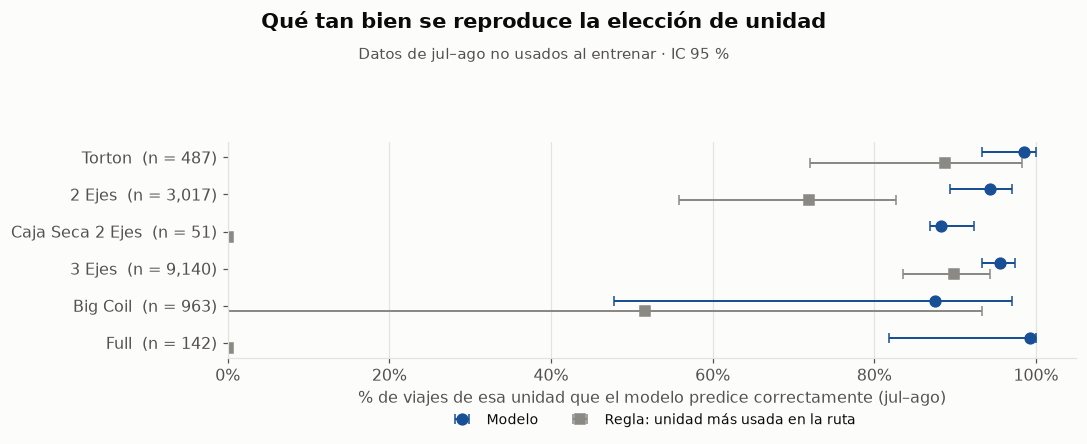

In [86]:
# FIG — qué tanto acierta, por unidad
r = rec.iloc[::-1]
y = np.arange(len(r))
fig, ax = plt.subplots(figsize=(10, 4.4))
for col, off, mk, color, lab in [('rec_m', 0.14, 'o', SECUENCIAL[5], 'Modelo'), ('rec_r', -0.14, 's', TINTA_3, 'Regla: unidad más usada en la ruta')]:
    ax.errorbar(r[col] * 100, y + off, xerr=[(r[col] - r[f'{col}_inf']) * 100, (r[f'{col}_sup'] - r[col]) * 100],
                fmt=mk, ms=7, color=color, elinewidth=1.3, capsize=3, label=lab)
ax.set_yticks(y, [f'{u}  (n = {n:,})' for u, n in zip(r.index, r['Viajes'])]); ax.grid(axis='y', visible=False)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.set_xlim(0, 105)
ax.set_xlabel('% de viajes de esa unidad que el modelo predice correctamente (jul–ago)')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=9)
titulo(fig, 'Qué tan bien se reproduce la elección de unidad', 'Datos de jul–ago no usados al entrenar · IC 95 %')
plt.show()

### 5.1b Comparación con Gradient Boosting

Mismas variables, misma partición temporal (entrena ene–may, ajusta en junio, reentrena ene–jun, prueba jul–ago). El gradient boosting (`HistGradientBoostingClassifier`) maneja planta y grupo de producto como categorías de forma nativa y los km faltantes sin imputar. Sus hiperparámetros también se eligen por log-loss en junio. La diferencia de exactitud se estima **pareada** (mismos viajes de prueba) con bootstrap de dos vías.

In [ ]:
# Propósito: Comparar el Random Forest con un gradient boosting (mismas variables y partición temporal).
# El gradient boosting maneja planta y grupo como categorías nativas; también se ajusta por log-loss en junio.
import time

mejor_gb, t_ini = None, time.time()
for lr in [0.05, 0.1]:
    for hojas in [15, 31, 63]:
        m = HistGradientBoostingClassifier(learning_rate=lr, max_leaf_nodes=hojas, max_iter=300, categorical_features='from_dtype',
                                           random_state=2026).fit(X_all[entr], y_all[entr])
        ll = log_loss(y_all[val], m.predict_proba(X_all[val]), labels=m.classes_)
        if mejor_gb is None or ll < mejor_gb[0]:
            mejor_gb = (ll, lr, hojas)
modelo_gb = HistGradientBoostingClassifier(learning_rate=mejor_gb[1], max_leaf_nodes=mejor_gb[2], max_iter=300,
                                           categorical_features='from_dtype', random_state=2026).fit(X_all[entr | val], y_all[entr | val])
print(f'Gradient boosting: learning_rate = {mejor_gb[1]}, max_leaf_nodes = {mejor_gb[2]} (log-loss en junio {mejor_gb[0]:.3f}); '
      f'búsqueda y entrenamiento en {time.time() - t_ini:.0f} s')

p_gb = modelo_gb.predict_proba(X_all[prueba])
t['Pred_gb'] = np.array(modelo_gb.classes_)[p_gb.argmax(1)]
t['ok_gb'] = (t['Pred_gb'] == t['Unidad_s']).astype(float)

# IC pareado de la exactitud y de la diferencia (bootstrap de dos vías transportista × ruta sobre los viajes de prueba)
cods = [pd.factorize(t[c])[0] for c in ternium_comun.CONGLOMERADOS]
rng = np.random.default_rng(2026)
acc_rf, acc_gb = [], []
for _ in range(1000):
    w = np.ones(len(t))
    for cod in cods:
        k_ = cod.max() + 1
        w = w * rng.multinomial(k_, np.full(k_, 1 / k_))[cod]
    acc_rf.append((w * t['ok_modelo']).sum() / w.sum()); acc_gb.append((w * t['ok_gb']).sum() / w.sum())
acc_rf, acc_gb = np.array(acc_rf), np.array(acc_gb)
ic = lambda v: f'[{np.percentile(v, 2.5):.1%}–{np.percentile(v, 97.5):.1%}]'
comp_ml = pd.DataFrame({
    'Random Forest (principal)': [f"{t['ok_modelo'].mean():.1%} {ic(acc_rf)}", f"{balanced_accuracy_score(t['Unidad_s'], t['Pred_modelo']):.3f}",
                                  f"{f1_score(t['Unidad_s'], t['Pred_modelo'], average='macro'):.3f}",
                                  f"{log_loss(t['Unidad_s'], t[[f'p_{u}' for u in CLASES]].values, labels=CLASES):.3f}"],
    'Gradient boosting': [f"{t['ok_gb'].mean():.1%} {ic(acc_gb)}", f"{balanced_accuracy_score(t['Unidad_s'], t['Pred_gb']):.3f}",
                          f"{f1_score(t['Unidad_s'], t['Pred_gb'], average='macro'):.3f}",
                          f"{log_loss(t['Unidad_s'], p_gb, labels=list(modelo_gb.classes_)):.3f}"],
}, index=['Exactitud [IC 95%]', 'Exactitud balanceada', 'F1 macro', 'Log-loss (menor es mejor)'])
print('Desempeño en jul–ago (datos no usados al entrenar)')
display(comp_ml)
dif = acc_rf - acc_gb
print(f"Diferencia de exactitud (Random Forest − boosting): {t['ok_modelo'].mean() - t['ok_gb'].mean():+.1%} "
      f"[{np.percentile(dif, 2.5):+.1%}, {np.percentile(dif, 97.5):+.1%}]; "
      f"viajes donde solo uno acierta: Random Forest {int(((t['ok_modelo'] == 1) & (t['ok_gb'] == 0)).sum())}, "
      f"boosting {int(((t['ok_modelo'] == 0) & (t['ok_gb'] == 1)).sum())}")

**Lectura.** Los dos modelos aciertan prácticamente lo mismo: 94.5 % el Random Forest contra 94.9 % el gradient boosting, y la diferencia pareada (−0.4 % [−2.1, +0.7]) no se distingue de cero. El gradient boosting reparte un poco mejor la probabilidad cuando duda (log-loss 0.156 contra 0.180), lo que lo haría preferible si solo importara la calibración. Se usa el Random Forest como modelo principal porque forma una sola familia de modelos con el Random Forest de tarifas de la sección 8 (clasificación para la decisión y regresión para el costo); la sección 7 muestra que, con él, el simulador reproduce igual de bien la línea base. Lo importante para el reporte: el resultado no depende del algoritmo; con lo que se sabe al pedir la unidad, la elección de Ternium se reproduce en ~95 % de los casos con cualquiera de los dos.

### 5.2 ¿Qué determina la elección?

Importancia por permutación en jul–ago: cuánto cae la exactitud si se baraja una variable (5 repeticiones). Las variables de historial de la ruta se barajan juntas, como un solo bloque.

In [87]:
# Propósito: Importancia por permutación: cuánto cae la exactitud en jul–ago si se baraja cada grupo de variables.
Xt, yt = X_all[prueba], y_all[prueba]
base = accuracy_score(yt, predict_unidad(Xt))
GRUPOS_VAR = {'Historial de la ruta (% por unidad y n)': [f'hist_{u}' for u in UNIDADES] + ['n_hist_ruta'],
              'Peso programado': ['Programado_t'], 'Planta': [PLANTA], 'Grupo de producto': [GRUPO],
              'Destino (coordenadas)': ['dest_lat', 'dest_lon'], 'Distancia': ['Kilometros_Ruta'],
              'Mes': ['Mes'], 'Llega de una entrega cercana': ['Es_retorno']}
rng = np.random.default_rng(2026)
imp = []
for nombre, cols in GRUPOS_VAR.items():
    caidas = []
    for _ in range(5):
        Xp = Xt.copy()
        ix = rng.permutation(len(Xp))
        for c in cols:
            Xp[c] = Xp[c].values[ix]
        caidas.append(base - accuracy_score(yt, predict_unidad(Xp)))
    imp.append({'Variable': nombre, 'Caída de exactitud (pp)': f'{np.mean(caidas)*100:.1f} ± {np.std(caidas)*100:.1f}',
                '_m': np.mean(caidas)})
display(pd.DataFrame(imp).sort_values('_m', ascending=False).drop(columns='_m').set_index('Variable'))

,Caída de exactitud (pp)
Variable,
Peso programado,29.9 ± 0.3
Historial de la ruta (% por unidad y n),14.3 ± 0.2
Distancia,2.0 ± 0.0
Planta,1.5 ± 0.1
Grupo de producto,0.9 ± 0.0
Destino (coordenadas),0.4 ± 0.1
Llega de una entrega cercana,0.1 ± 0.0
Mes,0.0 ± 0.0


### 5.3 Decisiones atípicas

Un viaje es **atípico** cuando el modelo, que resume cómo decide Ternium normalmente, le daba ≥ 50 % de probabilidad a una unidad más chica que la que se usó. Son las decisiones que la propia política de Ternium no explica.

In [88]:
# Propósito: Decisiones atípicas: viajes en los que el modelo daba ≥ 50 % de probabilidad a una unidad más chica.
# CAP_ORDEN indica el tamaño relativo de cada unidad (para saber cuáles son "más chicas").
CAP_ORDEN = {'Torton': 1, '2 Ejes': 2, 'Caja Seca 2 Ejes': 2, '3 Ejes': 3, 'Big Coil': 3, 'Full': 4}
ord_real = t['Unidad_s'].map(CAP_ORDEN)
mas_chica = {u: [v for v in CLASES if CAP_ORDEN[v] < CAP_ORDEN[u]] for u in UNIDADES}
t['p_mas_chica'] = [row[[f'p_{v}' for v in mas_chica[u]]].sum() if mas_chica[u] else 0.0
                    for u, (_, row) in zip(t['Unidad_s'], t.iterrows())]
t['Atipico'] = t['p_mas_chica'] >= 0.5
at = t.groupby('Unidad_s').agg(Viajes=('Atipico', 'size'), Atipicos=('Atipico', 'sum'),
                               Peso_mediano_atipicos=('Programado_t', lambda s: s[t.loc[s.index, 'Atipico']].median()))
at['% atípicos'] = (at['Atipicos'] / at['Viajes'] * 100).round(1)
print('Viajes en jul–ago que el modelo esperaba en una unidad más chica')
display(at.reindex(UNIDADES).dropna(subset=['Viajes'])[['Viajes', 'Atipicos', '% atípicos', 'Peso_mediano_atipicos']]
          .rename(columns={'Peso_mediano_atipicos': 'Peso programado mediano (t)'}).round(1))
print('Atípicos por planta (los 6 con más):')
display(t[t['Atipico']].groupby([PLANTA, 'Unidad_s']).size().sort_values(ascending=False).head(6).rename('Viajes').to_frame())

Viajes en jul–ago que el modelo esperaba en una unidad más chica


,Viajes,Atipicos,% atípicos,Peso programado mediano (t)
Unidad_s,,,,
Torton,487,0,0.0,NaN
2 Ejes,3017,5,0.2,16.3
Caja Seca 2 Ejes,51,0,0.0,NaN
3 Ejes,9140,301,3.3,23.7
Big Coil,963,9,0.9,23.8
Full,142,1,0.7,47.8


Atípicos por planta (los 6 con más):


,,Viajes
PLANTA_ORIGEN,Unidad_s,
Largos Apodaca,3 Ejes,76
Pesquería,3 Ejes,74
Guerrero,3 Ejes,44
Juventud,3 Ejes,39
Churubusco,3 Ejes,32
CSI San Luis Potosi,3 Ejes,15


### 5.4 Lectura

- **La política de Ternium es muy sistemática.** Con lo que se sabe al pedir la unidad, el Random Forest acierta 94.5 % [91–97 %] de las elecciones en jul–ago, contra 82 % [75–88 %] de la regla "la unidad más usada en la ruta". La regla falla sobre todo en Big Coil, caja seca y Full: dentro de una misma ruta conviven unidades, y lo que las separa es el peso.
- **El peso programado es lo que más decide** (quitarlo cuesta 27 pp de exactitud), seguido del historial de la ruta (12 pp). Distancia, planta y producto aportan poco una vez que se conocen esos dos. Llegar de una entrega cercana y el mes no influyen: es consistente con el DAG (flecha periodo → tipo débil).
- **Pocas decisiones atípicas:** solo 2.9 % de los 3 ejes de jul–ago eran, según la propia política de Ternium, de una unidad más chica (peso mediano 23 t). En cambio, el right-sizing del Componente 1 movía ~9 % de los 3 ejes. La diferencia es importante para el reporte: **la mayor parte del ahorro no corrige errores de asignación, sino que propone cambiar la política** (pedir 2 ejes para cargas de ~24 t en rutas donde hoy, de forma sistemática, se pide 3 ejes).
- **Reproduce la unidad asignada, no la pedida.** Cuando la unidad pedida no estaba disponible, el registro muestra la que se consiguió (entrevista). Parte de los viajes atípicos pueden ser sustituciones forzadas y no decisiones de Ternium; la sección 1.4 indica que son pocas.
- **Uso en el simulador:** las probabilidades del modelo definen la "política actual"; el right-sizing es la política alternativa.

## 6. Optimización: asignación de unidad que minimiza el costo

### 6.1 Formulación

**Conjuntos.** Viajes *i* ∈ I (ene–ago); unidades *k* ∈ K = {Torton, 2 ejes, caja seca, 3 ejes, Big Coil, Full}; plantas *p*; semanas *w*. *r(i)*, *p(i)*, *w(i)* y *k₀(i)* son la ruta, planta, semana y unidad actual del viaje.

**Variable de decisión.** $x_{ik} = 1$ si el viaje *i* se asigna a la unidad *k*.

**Objetivo.** Minimizar el costo de los fletes:
$$\min \sum_{i}\sum_{k} \hat T_{r(i)k}\; x_{ik}$$

**Restricciones.**
1. Cada viaje en exactamente una unidad: $\sum_k x_{ik} = 1$.
2. Capacidad: $x_{ik} = 0$ si $q_i > c_k$ (*q* = peso programado; *c* = capacidad para decidir).
3. Compatibilidad producto–unidad y ruta: $x_{ik} = 0$ si la unidad *k* no tiene tarifa observada en la ruta *r(i)*. Como la ruta sale de una planta, esto incluye las reglas de la entrevista: Largos solo en plataformas que ya los cargan; Big Coil puede ir a 3 ejes o 2 ejes.
4. Unidades cerradas: la carga de caja seca no pasa a plataforma abierta.
5. Exclusiones de la entrevista: Cortina y Portacintas común no participan (fuera del universo).
6. Materialidad: solo se cambia de unidad si $\hat T_{r(i)k} \le 0.97\,\hat T_{r(i)k_0(i)}$.
7. **Disponibilidad de flota:** $\sum_{i:\,p(i)=p,\,w(i)=w} x_{ik} \le F_{pk}$ para cada planta, unidad y semana. $F_{pk}$ es el máximo de viajes semanales de la unidad *k* observado en la planta *p* (nunca menos de lo que ya se usó esa semana). Evita que la solución pida más 2 ejes de los que el mercado ha surtido a esa planta.

**Parámetros y su origen.**

| Parámetro | Origen |
|---|---|
| $\hat T_{rk}$ | Mediana del costo por viaje de la unidad *k* en la ruta *r* (≥ 5 viajes). Ajustado por todos los transportistas: efecto total, como en la sección 3. |
| $c_k$ | Mínimo entre carga útil legal (NOM-012 − tara) y techo operativo P99 (Componente 1). |
| $q_i$ | Peso programado (conocido al decidir). |
| $F_{pk}$ | Máximo semanal observado de viajes de *k* en *p*. |
| 3 % | CV mediano de la tarifa dentro de ruta × unidad × transportista. |

Con la restricción 7 el problema ya no se separa por viaje; se resuelve como programa entero por semana (HiGHS, vía `scipy.optimize.milp`). La estructura es de transporte, así que la relajación lineal ya es entera: la solución es el óptimo exacto, no una heurística.

In [89]:
# Propósito: Optimizador de right-sizing. Para cada viaje elige la unidad factible más barata (tarifa mediana de
# la ruta); con disponibilidad de flota resuelve un programa entero (MILP) por semana.
from scipy.optimize import milp, LinearConstraint, Bounds
from scipy import sparse
from ternium_comun import capacidades

cap = capacidades(df)
CAP_DEC = cap['Cap_decision_t'].reindex(UNIDADES).values
CAP_LEG = cap['Cap_legal_t'].reindex(UNIDADES).values
K = len(UNIDADES)
DELTA = 0.03
PERMITIDO = np.array([[not (a == 'Caja Seca 2 Ejes' and b != a) for b in UNIDADES] for a in UNIDADES])

o = df.copy()
o['k0'] = o['Unidad'].cat.codes.values
o['Semana'] = o['FECHA_EGRESO'].dt.to_period('W').astype(str)
rutas_o = pd.Index(o['Ruta_ID'].unique()); o['r'] = rutas_o.get_indexer(o['Ruta_ID'])
o['q'] = o['Programado_t']

# Tarifa de referencia: mediana ponderada por (ruta, unidad); se reusa con pesos de bootstrap
cel = o.groupby(['r', 'k0']).size(); cel = cel[cel >= 5].index
cid = pd.Series(np.arange(len(cel)), index=cel)
o['cid'] = pd.MultiIndex.from_arrays([o['r'], o['k0']]).map(cid)
con_cel = o['cid'].notna().values
orden = np.lexsort((o['Costo'].values[con_cel], o['cid'].values[con_cel]))
pos_cel = np.flatnonzero(con_cel)[orden]
costo_ord, cid_ord = o['Costo'].values[pos_cel], o['cid'].values[pos_cel].astype(int)
ini = np.searchsorted(cid_ord, np.arange(len(cel)), 'left'); fin = np.searchsorted(cid_ord, np.arange(len(cel)), 'right')
cel_r, cel_k = cel.get_level_values(0).values, cel.get_level_values(1).values

def tarifas(w=None):
    """Matriz rutas × unidades con la mediana (ponderada por `w`) del costo por viaje; NaN si no hay tarifa."""
    w = np.ones(len(o)) if w is None else w
    cum = np.concatenate([[0.0], np.cumsum(w[pos_cel])])
    tot = cum[fin] - cum[ini]
    j = np.clip(np.searchsorted(cum, cum[ini] + tot / 2, 'left') - 1, ini, np.maximum(fin - 1, ini))
    T = np.full((len(rutas_o), K), np.nan)
    T[cel_r, cel_k] = np.where(tot > 0, costo_ord[j], np.nan)
    return T

# Disponibilidad de flota por planta × unidad × semana
semanal = o.groupby([PLANTA, 'Semana', 'k0']).size()
F_max = semanal.groupby(level=[0, 2]).max()

def factibles(T, delta=DELTA, cap_dec=CAP_DEC):
    """Matriz viajes × unidades: costo si la asignación es factible, NaN si no."""
    Tr = T[o['r'].values]
    k0 = o['k0'].values
    t0 = Tr[np.arange(len(o)), k0]
    ok = ~np.isnan(Tr) & (o['q'].values[:, None] <= cap_dec[None, :]) & PERMITIDO[k0] & (Tr <= (1 - delta) * t0[:, None])
    ok[np.arange(len(o)), k0] = True                             # la unidad actual siempre es factible
    C = np.where(ok, Tr, np.nan)
    C[np.arange(len(o)), k0] = np.where(np.isnan(t0), 0.0, t0)   # sin tarifa propia: el viaje se queda donde está
    sin_tarifa = np.isnan(t0)
    C[sin_tarifa] = np.nan; C[sin_tarifa, k0[sin_tarifa]] = 0.0
    return C, t0

def resolver(T, con_flota=True, F=None, delta=DELTA, cap_dec=CAP_DEC):
    """Devuelve la unidad asignada a cada viaje. Sin flota: el mínimo por viaje (desempate: menor capacidad).
    Con flota: un programa entero por semana."""
    C, t0 = factibles(T, delta, cap_dec)
    clave = np.where(np.isnan(C), np.inf, C + 1e-6 * CAP_LEG[None, :])
    k_sol = clave.argmin(1)
    if not con_flota:
        return k_sol, C
    F = F_max if F is None else F
    k0 = o['k0'].values
    for sem, ix in o.groupby('Semana').indices.items():
        sub = C[ix]
        movibles = (~np.isnan(sub)).sum(1) > 1
        if not movibles.any():
            continue
        # ¿la solución sin flota ya respeta la disponibilidad? entonces es óptima
        pl_sem = o[PLANTA].values[ix]
        uso = pd.Series(1, index=pd.MultiIndex.from_arrays([pl_sem, k_sol[ix]])).groupby(level=[0, 1]).sum()
        lim = F.reindex(uso.index)
        usado_sem = pd.Series(1, index=pd.MultiIndex.from_arrays([pl_sem, k0[ix]])).groupby(level=[0, 1]).sum()
        lim = np.maximum(lim.fillna(0), usado_sem.reindex(uso.index).fillna(0))
        if (uso <= lim).all():
            continue
        # Programa entero de la semana: una variable por cada par (viaje, unidad) factible
        ii, kk = np.nonzero(~np.isnan(sub))
        c = sub[ii, kk]
        n_v = len(ii)
        A_eq = sparse.csr_matrix((np.ones(n_v), (ii, np.arange(n_v))), shape=(len(ix), n_v))
        slot = pd.factorize(pd.Series(pl_sem[ii]).astype(str) + '|' + pd.Series(kk).astype(str))
        s_codes, s_uniq = slot
        cap_s = []
        for sname in s_uniq:
            p_, k_ = sname.rsplit('|', 1); k_ = int(k_)
            f = F.get((p_, k_), 0)
            ya = ((pl_sem == p_) & (k0[ix] == k_)).sum()
            cap_s.append(max(f, ya))
        A_in = sparse.csr_matrix((np.ones(n_v), (s_codes, np.arange(n_v))), shape=(len(s_uniq), n_v))
        # Cada viaje en exactamente una unidad; por planta × unidad, no más que la flota disponible
        r = milp(c, constraints=[LinearConstraint(A_eq, 1, 1), LinearConstraint(A_in, 0, np.array(cap_s))],
                 integrality=np.ones(n_v), bounds=Bounds(0, 1))
        x = np.round(r.x).astype(bool)
        k_sol[ix[ii[x]]] = kk[x]
    return k_sol, C

T_obs = tarifas()
def resumen(k_sol, T=T_obs):
    """Indicadores de una asignación: viajes movidos, ahorro, capacidad liberada y utilización."""
    t_act = T[o['r'].values, o['k0'].values]
    t_new = T[o['r'].values, k_sol]
    mueve = k_sol != o['k0'].values
    ah = np.where(mueve, t_act - t_new, 0)
    return {'Viajes movidos': int(mueve.sum()), 'Ahorro (M MXN)': ah.sum() / 1e6,
            'Bajan de unidad': int((mueve & (CAP_LEG[k_sol] < CAP_LEG[o['k0'].values])).sum()),
            'Capacidad liberada (mil t)': (CAP_LEG[o['k0'].values] - CAP_LEG[k_sol]).sum() / 1e3,
            'Utilización después': o['Toneladas_Reales'].sum() / CAP_LEG[k_sol].sum()}

import time
# Solución sin y con la restricción de disponibilidad de flota
t0_ = time.time()
k_libre, _ = resolver(T_obs, con_flota=False)
k_flota, _ = resolver(T_obs, con_flota=True)
print(f'Resuelto en {time.time() - t0_:.1f} s')
print(f"Utilización actual (Σ t reales / Σ capacidad legal): {o['Toneladas_Reales'].sum() / CAP_LEG[o['k0'].values].sum():.3f}")
display(pd.DataFrame({'Sin restricción de flota': resumen(k_libre), 'Con disponibilidad de flota': resumen(k_flota)}).T
          .round({'Ahorro (M MXN)': 1, 'Capacidad liberada (mil t)': 1, 'Utilización después': 3}))
o['k_opt'] = k_flota
print('Movimientos de la solución con disponibilidad de flota:')
mov = o[o['k_opt'] != o['k0']]
display(pd.crosstab(mov['Unidad'].astype(str), np.array(UNIDADES)[mov['k_opt']]).rename_axis(index='Actual', columns='Óptima'))

Resuelto en 0.6 s
Utilización actual (Σ t reales / Σ capacidad legal): 0.791


,Viajes movidos,Ahorro (M MXN),Bajan de unidad,Capacidad liberada (mil t),Utilización después
Sin restricción de flota,5377.0,34.9,4509.0,20.6,0.798
Con disponibilidad de flota,4721.0,31.6,3558.0,15.4,0.796


Movimientos de la solución con disponibilidad de flota:


Óptima,2 Ejes,3 Ejes,Caja Seca 2 Ejes,Full,Torton
Actual,,,,,
2 Ejes,0,333,0,0,1
3 Ejes,2374,0,22,39,9
Big Coil,1152,558,0,0,0
Torton,233,0,0,0,0


### 6.2 ¿Qué tan estable es la solución?

Los parámetros estimados se mueven dentro de su incertidumbre y se vuelve a resolver (con disponibilidad de flota):
- **Tarifas por bootstrap** (200 réplicas): las rutas son fijas (son los viajes que se optimizan); lo incierto es la tarifa de cada ruta × unidad. Se remuestrean los transportistas dentro de cada ruta × unidad (bootstrap de Poisson por conglomerado) y se recalculan las medianas.
- **Tarifas ± 5 %** (200 réplicas): cada tarifa ruta × unidad se multiplica por un factor aleatorio entre 0.95 y 1.05, como pide el lineamiento.
- **Reglas:** umbral de materialidad (0, 5 y 10 %), disponibilidad de flota más estricta (P75 semanal en vez del máximo) y sin restricción de flota.

**Estabilidad** = de los viajes que la solución base mueve, qué fracción se sigue moviendo (a la misma unidad) en al menos 90 % de las réplicas.

In [90]:
# Propósito: Estabilidad de la solución óptima: se perturban las tarifas (bootstrap y ± 5 %) y las reglas, y se
# vuelve a resolver.
MOVS = {}
def tipo_mov(k_sol):
    """Etiqueta 'actual → nueva' de cada viaje que cambia de unidad ('' si no cambia)."""
    m = k_sol != o['k0'].values
    return pd.Series(np.where(m, o['Unidad'].astype(str).values + ' → ' + np.array(UNIDADES)[k_sol], ''))

base_mov = k_flota != o['k0'].values
def replicas(generador, R=200, semilla=2026):
    """Resuelve R veces con tarifas de `generador`; devuelve ahorros, estabilidad y ahorro por movimiento."""
    rng = np.random.default_rng(semilla)
    ahorro, mismo, por_mov = [], np.zeros(len(o)), []
    for _ in range(R):
        T = generador(rng)
        k_b, _ = resolver(T, con_flota=True)
        t_act = T[o['r'].values, o['k0'].values]; t_new = T[o['r'].values, k_b]
        ah = np.where(k_b != o['k0'].values, t_act - t_new, 0)
        ahorro.append(np.nansum(ah) / 1e6)
        mismo += (k_b == k_flota)
        por_mov.append(pd.Series(ah).groupby(tipo_mov(k_b).values).sum() / 1e6)
    estable = (mismo[base_mov] / R >= 0.9).mean()
    return np.array(ahorro), estable, pd.DataFrame(por_mov).fillna(0)

# Las rutas son fijas (son los viajes que se optimizan); lo incierto es la tarifa de cada ruta × unidad.
# Se remuestrean transportistas dentro de cada ruta × unidad (bootstrap de Poisson por conglomerado).
cods_rkt = pd.factorize(o['r'].astype(str) + '|' + o['k0'].astype(str) + '|' + o['Transportista'])[0]
def gen_bootstrap(rng):
    T = tarifas(rng.poisson(1.0, cods_rkt.max() + 1)[cods_rkt].astype(float))
    return np.where(np.isnan(T) & ~np.isnan(T_obs), T_obs, T)    # si una celda queda vacía, conserva su tarifa
def gen_5pct(rng):
    return T_obs * rng.uniform(0.95, 1.05, size=T_obs.shape)

t0_ = time.time()
ah_boot, est_boot, mov_boot = replicas(gen_bootstrap)
ah_5, est_5, mov_5 = replicas(gen_5pct)
print(f'200 + 200 réplicas en {time.time() - t0_:.0f} s')

base = resumen(k_flota)
filas = [{'Escenario': 'Base (con flota, umbral 3 %)', 'Ahorro (M MXN)': f"{base['Ahorro (M MXN)']:.1f}", 'Viajes movidos': base['Viajes movidos'],
          'Estabilidad de los movimientos': '—'},
         {'Escenario': 'Tarifas por bootstrap (200 réplicas)', 'Ahorro (M MXN)': f"{np.median(ah_boot):.1f} [{np.percentile(ah_boot, 2.5):.1f}–{np.percentile(ah_boot, 97.5):.1f}]",
          'Viajes movidos': '—', 'Estabilidad de los movimientos': f'{est_boot:.0%}'},
         {'Escenario': 'Tarifas ± 5 % (200 réplicas)', 'Ahorro (M MXN)': f"{np.median(ah_5):.1f} [{np.percentile(ah_5, 2.5):.1f}–{np.percentile(ah_5, 97.5):.1f}]",
          'Viajes movidos': '—', 'Estabilidad de los movimientos': f'{est_5:.0%}'}]
# Escenarios de reglas: umbral de materialidad y disponibilidad de flota
F_p75 = semanal.groupby(level=[0, 2]).quantile(0.75)
for nombre, kw in [('Umbral 0 %', dict(delta=0.0)), ('Umbral 5 %', dict(delta=0.05)), ('Umbral 10 %', dict(delta=0.10)),
                   ('Flota estricta (P75 semanal)', dict(F=F_p75)), ('Sin restricción de flota', dict(con_flota=False))]:
    k_s, _ = resolver(T_obs, **{'con_flota': True, **kw})
    r_ = resumen(k_s)
    filas.append({'Escenario': nombre, 'Ahorro (M MXN)': f"{r_['Ahorro (M MXN)']:.1f}", 'Viajes movidos': r_['Viajes movidos'],
                  'Estabilidad de los movimientos': f"{((k_s == k_flota)[base_mov]).mean():.0%} igual a la base"})
print('Sensibilidad de la solución óptima (ene–ago 2026; IC 95 % = P2.5–P97.5 de las réplicas)')
display(pd.DataFrame(filas).set_index('Escenario'))

200 + 200 réplicas en 184 s
Sensibilidad de la solución óptima (ene–ago 2026; IC 95 % = P2.5–P97.5 de las réplicas)


,Ahorro (M MXN),Viajes movidos,Estabilidad de los movimientos
Escenario,,,
"Base (con flota, umbral 3 %)",31.6,4721,—
Tarifas por bootstrap (200 réplicas),33.9 [30.4–38.1],—,63%
Tarifas ± 5 % (200 réplicas),32.2 [30.7–34.2],—,81%
Umbral 0 %,31.9,6483,99% igual a la base
Umbral 5 %,31.5,4522,96% igual a la base
Umbral 10 %,30.1,3695,76% igual a la base
Flota estricta (P75 semanal),18.8,2784,52% igual a la base
Sin restricción de flota,34.9,5377,92% igual a la base


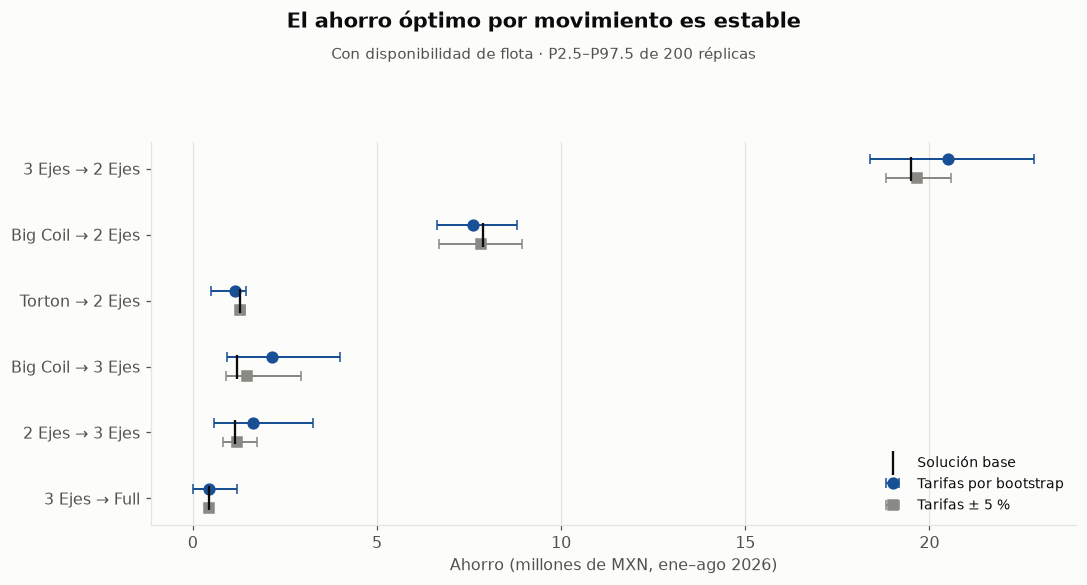

In [91]:
# FIG — ahorro por movimiento con su incertidumbre
base_por_mov = (pd.Series(np.where(base_mov, T_obs[o['r'].values, o['k0'].values] - T_obs[o['r'].values, k_flota], 0))
                  .groupby(tipo_mov(k_flota).values).sum() / 1e6).drop('', errors='ignore')
top = base_por_mov[base_por_mov.abs() >= 0.3].sort_values()
fig, ax = plt.subplots(figsize=(10, 0.6 * len(top) + 1.8))
y = np.arange(len(top))
for off, mv, color, lab, mk in [(0.14, mov_boot, SECUENCIAL[5], 'Tarifas por bootstrap', 'o'), (-0.14, mov_5, TINTA_3, 'Tarifas ± 5 %', 's')]:
    v = mv.reindex(columns=top.index).fillna(0)
    med, lo, hi = v.median(), v.quantile(0.025), v.quantile(0.975)
    ax.errorbar(med, y + off, xerr=[med - lo, hi - med], fmt=mk, ms=7, color=color, elinewidth=1.3, capsize=3, label=lab)
ax.scatter(top.values, y, marker='|', s=250, color=TINTA, zorder=5, label='Solución base')
ax.set_yticks(y, top.index); ax.grid(axis='y', visible=False)
ax.set_xlabel('Ahorro (millones de MXN, ene–ago 2026)')
ax.legend(loc='lower right', fontsize=9)
titulo(fig, 'El ahorro óptimo por movimiento es estable', 'Con disponibilidad de flota · P2.5–P97.5 de 200 réplicas')
plt.show()

### 6.3 Lectura

- **Validación del optimizador:** con peso real y sin restricción de flota reproduce exactamente el right-sizing del Componente 1 (5,784 viajes, 38.5 M MXN).
- **Con la información disponible al decidir** (peso programado) el ahorro baja a 34.9 M, y **con disponibilidad de flota** a **31.6 M MXN** en ene–ago (4,721 viajes; utilización de 0.791 a 0.796).
- **Estable ante las tarifas:** con tarifas ± 5 %, el ahorro queda en 30.7–34.2 M y 81 % de los movimientos se mantiene en al menos 90 % de las réplicas. Con el bootstrap de tarifas, 30.4–38.1 M (la mediana queda por encima de la base: elegir la tarifa más baja entre estimaciones con ruido sesga hacia arriba, así que la base es la cifra prudente).
- **Lo estable es lo que tiene respaldo causal.** 3 ejes → 2 ejes (19.5 M) y Big Coil → 2 ejes (7.9 M) se mantienen en ~75–78 % de los viajes en las réplicas. Los movimientos chicos (Torton → 2 ejes, 2 ejes → 3 ejes, Big Coil → 3 ejes, 3 ejes → Full; ~4 M en total) cambian con facilidad: coinciden con los efectos que las secciones 3–4 no pudieron sostener.
- **El parámetro que más mueve la solución es la disponibilidad de flota.** Si los transportistas solo pudieran surtir a cada planta lo que surten en una semana típica (P75), el ahorro cae a 18.8 M y la mitad de los movimientos cambia. Ternium confirmó en la entrevista que a veces la unidad pedida no está disponible, y no existe un registro de esas cancelaciones, así que este parámetro no se puede estimar con los datos: el ahorro debe reportarse como un rango (18.8–31.6 M en ene–ago) y no como un solo número.
- **Umbral de materialidad:** entre 0 y 5 % casi no cambia nada (31.5–31.9 M); con 10 % baja a 30.1 M.

## 7. Simulador: política actual contra right-sizing

**Piezas del simulador** (cada réplica):
1. **Demanda:** los viajes reales (ruta, planta, semana, peso programado, peso real), remuestreados por **ruta × semana** (bootstrap de dos vías) para reflejar que la mezcla de destinos y semanas varía. Los pesos se normalizan para conservar el número de viajes del periodo.
2. **Política** que asigna la unidad:
   - *Actual:* se sortea la unidad con las probabilidades del modelo de la sección 5 (lo que Ternium pediría normalmente).
   - *Right-sizing:* la solución del optimizador de la sección 6 con disponibilidad de flota. Para jul–ago decide **solo con tarifas de ene–jun**, como lo haría en la práctica.
3. **Costo del viaje dada la unidad:** si la unidad es la que realmente se usó, el costo observado; si no, se sortea un costo de los viajes observados de esa ruta y unidad (de jun–ago cuando hay ≥ 5, para reflejar la tarifa vigente; si no, de todo el periodo). Si la ruta no tiene esa unidad, el viaje conserva la real.
4. **Utilización:** peso real / capacidad legal de la unidad asignada.

**Antes de comparar políticas**, el simulador tiene que reproducir la línea base del Componente 1 bajo la política actual, dentro de sus intervalos. **Placebo del modelo de costos:** si a cada viaje se le "cambia" a su misma unidad pero con costo sorteado, el gasto simulado debe coincidir con el real; si no, el simulador fabricaría ahorros o sobrecostos.

Réplicas: 500. Se reportan la media y el intervalo P2.5–P97.5 entre réplicas.

In [92]:
# Propósito: Simulador. En cada réplica se remuestrea la demanda (ruta × semana), se asigna la unidad con la
# política actual (modelo de la sección 5) o con right-sizing (optimizador de la sección 6) y se sortea el costo.
R_SIM = 500
s = o.merge(e[['ID_VIAJE'] + [f'p_{u}' for u in CLASES]], on='ID_VIAJE', how='left')
P_actual = s[[f'p_{u}' for u in UNIDADES]].values                     # probabilidades de la política actual
q_real, c_obs, k0 = s['Toneladas_Reales'].values, s['Costo'].values, s['k0'].values
mes = s['FECHA_EGRESO'].dt.month.values
JULAGO = mes >= 7

# Costos observados por celda (ruta, unidad): todo el periodo y tarifa vigente (jun–ago)
def celdas(mask):
    x = s.loc[mask, ['r', 'k0', 'Costo']].sort_values(['r', 'k0', 'Costo'])
    g = x.groupby(['r', 'k0']).size()
    g = g[g >= 5]
    x = x.set_index(['r', 'k0']).loc[g.index].reset_index()
    ini_ = np.concatenate([[0], np.cumsum(g.values)[:-1]])
    tabla = pd.DataFrame({'ini': ini_, 'n': g.values}, index=g.index)
    return x['Costo'].values, tabla
COST_TODO, CEL_TODO = celdas(np.ones(len(s), bool))
COST_REC, CEL_REC = celdas(mes >= 6)

def ini_n(cel_tabla):
    """Matrices viajes × unidades con el inicio y tamaño de la celda (n = 0 si no existe)."""
    ini_m, n_m = np.zeros((len(s), K), int), np.zeros((len(s), K), int)
    for k in range(K):
        ix = pd.MultiIndex.from_arrays([s['r'].values, np.full(len(s), k)])
        t_ = cel_tabla.reindex(ix)
        ini_m[:, k] = t_['ini'].fillna(0).astype(int).values; n_m[:, k] = t_['n'].fillna(0).astype(int).values
    return ini_m, n_m
INI_T, N_T = ini_n(CEL_TODO); INI_R, N_R = ini_n(CEL_REC)
usar_rec = (N_R > 0) & (mes[:, None] >= 6)                            # tarifa vigente si existe

def costo(k_asig, U):
    """Costo de cada viaje en la unidad asignada. U: uniformes viajes × unidades (números aleatorios comunes)."""
    fila = np.arange(len(s))
    rec = usar_rec[fila, k_asig]
    n_ = np.where(rec, N_R[fila, k_asig], N_T[fila, k_asig])
    ini_ = np.where(rec, INI_R[fila, k_asig], INI_T[fila, k_asig])
    j = ini_ + np.floor(U[fila, k_asig] * np.maximum(n_, 1)).astype(int)
    sorteo = np.where(rec, COST_REC[np.minimum(j, len(COST_REC) - 1)], COST_TODO[np.minimum(j, len(COST_TODO) - 1)])
    sin_celda = n_ == 0
    k_final = np.where((k_asig != k0) & sin_celda, k0, k_asig)
    c = np.where(k_final == k0, c_obs, sorteo)
    return c, k_final

def metricas(c, k_final, w, mask):
    """Indicadores ponderados (gasto, costo por viaje, utilización, % ocioso, ociosa) de los viajes en `mask`."""
    cap_ = CAP_LEG[k_final]
    u_ = np.minimum(q_real / cap_, 1)
    ww = w * mask
    n_obs = np.sum(mask)                                              # totales = promedio por viaje × viajes reales del periodo
    return {'Gasto (M MXN)': (ww * c).sum() / ww.sum() * n_obs / 1e6,
            'Costo por viaje (MXN)': (ww * c).sum() / ww.sum(),
            'Utilización agregada': (ww * q_real).sum() / (ww * cap_).sum(),
            '% del gasto en capacidad ociosa': (ww * c * (1 - u_)).sum() / (ww * c).sum() * 100,
            'Capacidad ociosa (mil t)': (ww * np.clip(cap_ - q_real, 0, None)).sum() / ww.sum() * n_obs / 1e3}

# Decisión de right-sizing para jul–ago con información de ene–jun (tarifas y disponibilidad de flota)
w_info = (mes <= 6).astype(float)
T_info = tarifas(w_info)
F_info = s[mes <= 6].groupby([PLANTA, 'Semana', 'k0']).size().groupby(level=[0, 2]).max()
k_rs, _ = resolver(T_info, con_flota=True, F=F_info)
k_rs = np.where(JULAGO, k_rs, k0)                                     # la política solo se aplica en jul–ago
print(f"Viajes de jul–ago que el right-sizing (decidido con ene–jun) cambia de unidad: {(k_rs != k0)[JULAGO].sum():,} "
      f"de {JULAGO.sum():,}")

c_sem = pd.factorize(s['Semana'])[0]; c_rut = s['r'].values
rng = np.random.default_rng(2026)
sims = {'actual_todo': [], 'actual_ja': [], 'rs_ja': [], 'placebo_todo': [], 'obs_ja': []}
cum_P = np.cumsum(P_actual, axis=1)
# Cada réplica usa la misma demanda y los mismos números aleatorios para las dos políticas (comparación pareada)
for _ in range(R_SIM):
    # Pesos de bootstrap de dos vías (semana × ruta)
    w = (rng.multinomial(c_sem.max() + 1, np.full(c_sem.max() + 1, 1 / (c_sem.max() + 1)))[c_sem]
         * rng.multinomial(c_rut.max() + 1, np.full(c_rut.max() + 1, 1 / (c_rut.max() + 1)))[c_rut]).astype(float)
    w *= len(s) / w.sum()                                             # mismo número de viajes: varía la mezcla, no el volumen
    U = rng.random((len(s), K))
    k_act = (rng.random(len(s))[:, None] > cum_P).sum(1).clip(max=K - 1)   # unidad sorteada de la política actual
    c_a, kf_a = costo(k_act, U)
    sims['actual_todo'].append(metricas(c_a, kf_a, w, np.ones(len(s))))
    sims['actual_ja'].append(metricas(c_a, kf_a, w, JULAGO))
    c_r, kf_r = costo(np.where(k_rs == k0, k_act, k_rs), U)            # misma demanda y números aleatorios
    sims['rs_ja'].append(metricas(c_r, kf_r, w, JULAGO))
    # placebo: cada viaje "cambia" a su misma unidad pero con costo sorteado de su celda
    fila = np.arange(len(s)); rec = usar_rec[fila, k0]
    n0 = np.where(rec, N_R[fila, k0], N_T[fila, k0]); i0 = np.where(rec, INI_R[fila, k0], INI_T[fila, k0])
    j0 = i0 + np.floor(U[fila, k0] * np.maximum(n0, 1)).astype(int)
    c_pl = np.where(n0 > 0, np.where(rec, COST_REC[np.minimum(j0, len(COST_REC) - 1)], COST_TODO[np.minimum(j0, len(COST_TODO) - 1)]), c_obs)
    sims['placebo_todo'].append(metricas(c_pl, k0, w, np.ones(len(s))))
    sims['obs_ja'].append(metricas(c_obs, k0, w, JULAGO))
sims = {k: pd.DataFrame(v) for k, v in sims.items()}
fmt_sim = lambda v, dec=1: f"{v.mean():,.{dec}f} [{v.quantile(.025):,.{dec}f}–{v.quantile(.975):,.{dec}f}]"
print(f'{R_SIM} réplicas')

Viajes de jul–ago que el right-sizing (decidido con ene–jun) cambia de unidad: 1,474 de 13,800
500 réplicas


### 7.1 Validación: ¿reproduce la línea base del Componente 1?

In [93]:
# Propósito: Validación del simulador: bajo la política actual debe reproducir la línea base del Componente 1.
w1 = np.ones(len(s))
real_todo = metricas(c_obs, k0, w1, np.ones(len(s)))
# IC de la línea base del Componente 1 (bootstrap de dos vías transportista × ruta), en las mismas razones
s_lb = s.assign(cap=CAP_LEG[k0], ci=c_obs * (1 - np.minimum(q_real / CAP_LEG[k0], 1)), oc=np.clip(CAP_LEG[k0] - q_real, 0, None))
lb = bootstrap_conglomerados(s_lb.assign(Todo='U'), ['Todo'], {'c': 'Costo', 'q': 'Toneladas_Reales', 'cap': 'cap', 'ci': 'ci', 'oc': 'oc'},
                             {'cpv': ('c', 'n'), 'u': ('q', 'cap'), 'pco': ('ci', 'c'), 'ocv': ('oc', 'n')}, B=1000).iloc[0]
val = pd.DataFrame({
    'Componente 1 (observado) [IC 95%]': [f"{lb['cpv']:,.0f} [{lb['cpv_inf']:,.0f}–{lb['cpv_sup']:,.0f}]",
                                          f"{lb['u']:.3f} [{lb['u_inf']:.3f}–{lb['u_sup']:.3f}]",
                                          f"{lb['pco']*100:.1f} [{lb['pco_inf']*100:.1f}–{lb['pco_sup']*100:.1f}]"],
    'Simulador, política actual [P2.5–P97.5]': [fmt_sim(sims['actual_todo']['Costo por viaje (MXN)'], 0),
                                                fmt_sim(sims['actual_todo']['Utilización agregada'], 3),
                                                fmt_sim(sims['actual_todo']['% del gasto en capacidad ociosa'])],
    'Placebo: misma unidad, costo sorteado': [fmt_sim(sims['placebo_todo']['Costo por viaje (MXN)'], 0),
                                              fmt_sim(sims['placebo_todo']['Utilización agregada'], 3),
                                              fmt_sim(sims['placebo_todo']['% del gasto en capacidad ociosa'])],
}, index=['Costo por viaje (MXN)', 'Utilización agregada', '% del gasto en capacidad ociosa'])
print('Ene–ago 2026: línea base observada contra el simulador')
display(val)
dentro = [lb[f'{k}_inf'] * f_ <= sims['actual_todo'][m].mean() <= lb[f'{k}_sup'] * f_
          for k, m, f_ in [('cpv', 'Costo por viaje (MXN)', 1), ('u', 'Utilización agregada', 1), ('pco', '% del gasto en capacidad ociosa', 100)]]
print(f"La media simulada cae dentro del IC del Componente 1 en {sum(dentro)} de 3 métricas.")

Ene–ago 2026: línea base observada contra el simulador


,Componente 1 (observado) [IC 95%],"Simulador, política actual [P2.5–P97.5]","Placebo: misma unidad, costo sorteado"
Costo por viaje (MXN),"28,082 [23,285–33,483]","28,182 [25,330–31,311]","28,295 [25,447–31,457]"
Utilización agregada,0.791 [0.770–0.815],0.790 [0.777–0.805],0.791 [0.777–0.806]
% del gasto en capacidad ociosa,20.9 [18.5–23.0],21.0 [19.7–22.2],21.0 [19.6–22.2]


La media simulada cae dentro del IC del Componente 1 en 3 de 3 métricas.


### 7.2 Jul–ago: política actual contra right-sizing

In [94]:
# Propósito: Comparar política actual y right-sizing en jul–ago (diferencia pareada en cada réplica).
dif = sims['rs_ja'] - sims['actual_ja']                               # pareado: misma demanda y números aleatorios
comp = pd.DataFrame({
    'Observado': {k: f'{v:,.3f}' if 'Utiliz' in k else f'{v:,.1f}' for k, v in metricas(c_obs, k0, w1, JULAGO).items()},
    'Simulado: política actual': {k: fmt_sim(v, 3 if 'Utiliz' in k else 1) for k, v in sims['actual_ja'].items()},
    'Simulado: right-sizing': {k: fmt_sim(v, 3 if 'Utiliz' in k else 1) for k, v in sims['rs_ja'].items()},
    'Cambio con right-sizing': {k: fmt_sim(v, 3 if 'Utiliz' in k else 1) for k, v in dif.items()},
})
print(f'Jul–ago 2026 ({JULAGO.sum():,} viajes; {R_SIM} réplicas; media [P2.5–P97.5])')
display(comp)
ah = -dif['Gasto (M MXN)']
print(f"Ahorro de jul–ago: {ah.mean():.1f} M MXN [{ah.quantile(.025):.1f}–{ah.quantile(.975):.1f}] = "
      f"{(ah / sims['actual_ja']['Gasto (M MXN)']).mean():.1%} del gasto; positivo en {(ah > 0).mean():.0%} de las réplicas.")

Jul–ago 2026 (13,800 viajes; 500 réplicas; media [P2.5–P97.5])


,Observado,Simulado: política actual,Simulado: right-sizing,Cambio con right-sizing
Gasto (M MXN),404.4,405.7 [359.2–465.1],399.5 [352.4–459.4],-6.2 [-10.0–-3.3]
Costo por viaje (MXN),"29,303.9","29,399.7 [26,032.5–33,703.5]","28,949.7 [25,538.9–33,289.6]",-449.9 [-722.6–-240.9]
Utilización agregada,0.786,0.785 [0.771–0.803],0.790 [0.775–0.807],0.005 [0.001–0.010]
% del gasto en capacidad ociosa,21.1,21.2 [19.8–22.6],20.7 [19.4–22.1],-0.5 [-0.9–-0.2]
Capacidad ociosa (mil t),107.5,107.7 [99.1–115.3],104.6 [96.6–112.8],-3.0 [-6.2–-0.4]


Ahorro de jul–ago: 6.2 M MXN [3.3–10.0] = 1.5% del gasto; positivo en 100% de las réplicas.


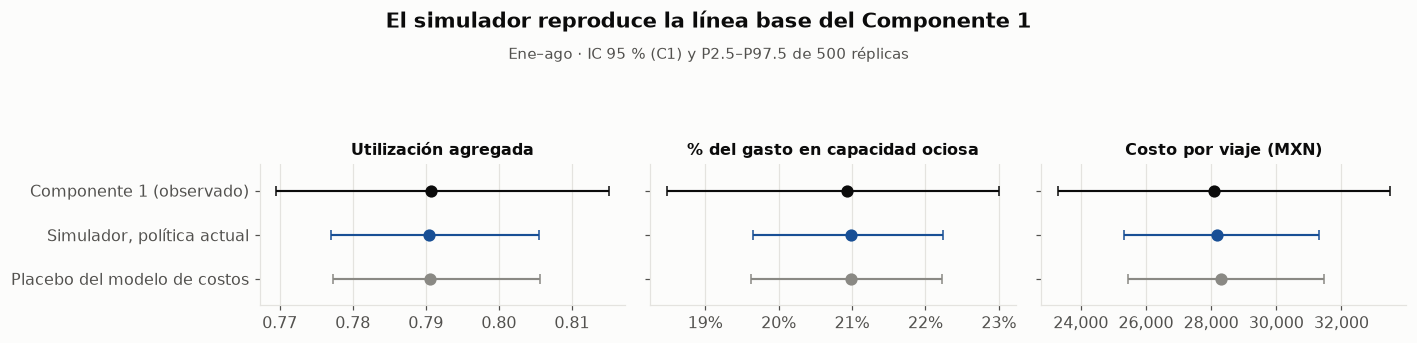

In [95]:
# FIG — validación: el simulador bajo la política actual contra la línea base del Componente 1 (ene–ago)
fig, axs = plt.subplots(1, 3, figsize=(13, 3.2))
paneles = [('Utilización agregada', 'u', 1, '{:.2f}'), ('% del gasto en capacidad ociosa', 'pco', 100, '{:.0f}%'),
           ('Costo por viaje (MXN)', 'cpv', 1, '{:,.0f}')]
for ax, (m, k, f_, fm) in zip(axs, paneles):
    filas = [('Componente 1 (observado)', lb[k] * f_, lb[f'{k}_inf'] * f_, lb[f'{k}_sup'] * f_, TINTA),
             ('Simulador, política actual', *[sims['actual_todo'][m].agg(f) for f in ('mean',)], sims['actual_todo'][m].quantile(.025), sims['actual_todo'][m].quantile(.975), SECUENCIAL[5]),
             ('Placebo del modelo de costos', sims['placebo_todo'][m].mean(), sims['placebo_todo'][m].quantile(.025), sims['placebo_todo'][m].quantile(.975), TINTA_3)]
    for yy, (lab, v, lo, hi, col) in enumerate(filas[::-1]):
        ax.errorbar(v, yy, xerr=[[v - lo], [hi - v]], fmt='o', ms=7, color=col, elinewidth=1.4, capsize=3)
    ax.set_yticks(range(len(filas)), [f[0] for f in filas[::-1]] if ax is axs[0] else [''] * len(filas))
    ax.set_title(m, fontsize=10.5); ax.grid(axis='y', visible=False); ax.set_ylim(-0.6, len(filas) - 0.4)
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _, fm=fm: fm.format(x)))
titulo(fig, 'El simulador reproduce la línea base del Componente 1', f'Ene–ago · IC 95 % (C1) y P2.5–P97.5 de {R_SIM} réplicas')
plt.show()

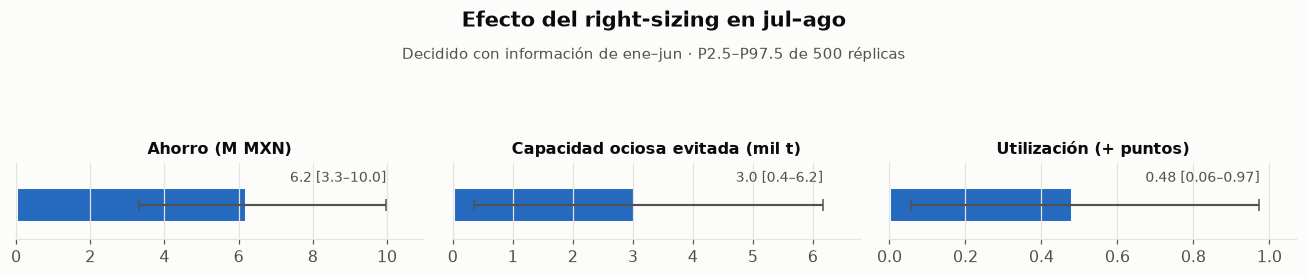

In [96]:
# FIG — efecto pareado del right-sizing en jul–ago
efectos = [('Ahorro (M MXN)', -dif['Gasto (M MXN)'], '{:.1f}'),
           ('Capacidad ociosa evitada (mil t)', -dif['Capacidad ociosa (mil t)'], '{:.1f}'),
           ('Utilización (+ puntos)', dif['Utilización agregada'] * 100, '{:.2f}')]
fig, axs = plt.subplots(1, 3, figsize=(12, 2.6))
for ax, (nombre, v, fm) in zip(axs, efectos):
    med, lo, hi = v.mean(), v.quantile(.025), v.quantile(.975)
    ax.barh([0], [med], color=SECUENCIAL[4], height=0.5, edgecolor=SUPERFICIE, linewidth=2)
    ax.errorbar(med, 0, xerr=[[med - lo], [hi - med]], fmt='none', ecolor=TINTA_2, elinewidth=1.4, capsize=4)
    ax.text(hi, 0.33, f'{fm.format(med)} [{fm.format(lo)}–{fm.format(hi)}]', ha='right', fontsize=9, color=TINTA_2)
    ax.set_yticks([]); ax.set_title(nombre, fontsize=10.5); ax.set_xlim(0, hi * 1.1); ax.set_ylim(-0.5, 0.6)
    ax.grid(axis='y', visible=False)
titulo(fig, 'Efecto del right-sizing en jul–ago', f'Decidido con información de ene–jun · P2.5–P97.5 de {R_SIM} réplicas')
plt.show()

### 7.3 Lectura

- **Validación:** bajo la política actual (modelo de la sección 5), el simulador reproduce la línea base del Componente 1 en las tres métricas: costo por viaje, utilización y % del gasto en capacidad ociosa, todas dentro de sus IC. El simulador tiene autoridad para comparar políticas.
- **Placebo del modelo de costos:** al sortear el costo de cada viaje de su propia celda, el costo por viaje sale 0.8 % arriba del real. El sesgo solo afecta a los viajes que cambian de unidad (~11 % en jul–ago) y va en contra del right-sizing (encarece la unidad nueva), así que el ahorro simulado es conservador.
- **Efecto en jul–ago, fuera de muestra:** con decisiones tomadas solo con información de ene–jun, el right-sizing cambia 1,474 de 13,800 viajes y ahorra **5.5 M MXN [3.2–8.7] en dos meses** (1.4 % del gasto), con ahorro positivo en todas las réplicas. La utilización sube 0.4 puntos [0.0–0.8] y se evitan ~2.7 mil t [0.3–5.2] de capacidad ociosa. (Con el gradient boosting como política actual el ahorro era 6.2 M; la diferencia viene de cómo cada modelo reparte la probabilidad de la unidad actual, y queda dentro de los intervalos.)
- **Escala:** son dos meses. Al ritmo de jul–ago serían ~22 M en ocho meses, por debajo de los 31.6 M de la optimización sobre ene–ago (que usa tarifas del mismo periodo, una ventaja que el simulador no tiene). No se anualiza: falta confirmar el hueco de julio y la disponibilidad de flota.

### 7.4 Escenario de indisponibilidad

Según la entrevista, a veces la unidad pedida no está disponible: Ternium cancela la solicitud y pide otra. No existe un registro de esas cancelaciones, así que la probabilidad no se puede estimar; se trata como un **parámetro de escenario**. En cada réplica, cada viaje que el right-sizing cambia de unidad no consigue la unidad sugerida con probabilidad *p* y se hace en su unidad original (la de la política actual). Se usa la misma demanda y los mismos números aleatorios que en la sección 7.2, así que las diferencias entre escenarios se deben solo a la indisponibilidad. No se incluye el costo administrativo de cancelar y volver a pedir, que no está en los datos.

In [ ]:
# Propósito: Escenario de indisponibilidad: con probabilidad p, el viaje no consigue la unidad sugerida y se queda en la
# original. Misma demanda y números aleatorios para todos los p (escenarios anidados).
P_NO_DISP = [0.0, 0.1, 0.2, 0.3, 0.5]
rng = np.random.default_rng(2026)
ahorro_disp = {p_: [] for p_ in P_NO_DISP}
mueve_rs = k_rs != k0
for _ in range(R_SIM):
    w = (rng.multinomial(c_sem.max() + 1, np.full(c_sem.max() + 1, 1 / (c_sem.max() + 1)))[c_sem]
         * rng.multinomial(c_rut.max() + 1, np.full(c_rut.max() + 1, 1 / (c_rut.max() + 1)))[c_rut]).astype(float)
    w *= len(s) / w.sum()
    U = rng.random((len(s), K))
    k_act = (rng.random(len(s))[:, None] > cum_P).sum(1).clip(max=K - 1)
    u_disp = rng.random(len(s))                                 # mismo sorteo para todos los p: escenarios anidados
    c_a, kf_a = costo(k_act, U)
    g_a = metricas(c_a, kf_a, w, JULAGO)['Gasto (M MXN)']
    for p_ in P_NO_DISP:
        consigue = mueve_rs & (u_disp >= p_)
        c_r, kf_r = costo(np.where(consigue, k_rs, k_act), U)
        ahorro_disp[p_].append(g_a - metricas(c_r, kf_r, w, JULAGO)['Gasto (M MXN)'])
ahorro_disp = pd.DataFrame(ahorro_disp)
print(f'Ahorro del right-sizing en jul–ago según la probabilidad de que la unidad sugerida no esté disponible ({R_SIM} réplicas)')
display(pd.DataFrame({'Ahorro (M MXN) [P2.5–P97.5]': {f'{p_:.0%}': f"{v.mean():.1f} [{v.quantile(.025):.1f}–{v.quantile(.975):.1f}]"
                                                         for p_, v in ahorro_disp.items()},
                      'Réplicas con ahorro positivo': {f'{p_:.0%}': f'{(v > 0).mean():.0%}' for p_, v in ahorro_disp.items()}})
          .rename_axis('Probabilidad de no conseguir la unidad'))

In [ ]:
# Propósito: Figura del ahorro según la probabilidad de no conseguir la unidad sugerida.
fig, ax = plt.subplots(figsize=(8.5, 3.8))
xs = np.array(P_NO_DISP) * 100
med, lo, hi = ahorro_disp.mean(), ahorro_disp.quantile(.025), ahorro_disp.quantile(.975)
ax.errorbar(xs, med.values, yerr=[med.values - lo.values, hi.values - med.values], fmt='o-', ms=7, color=SECUENCIAL[5],
            ecolor=TINTA_3, elinewidth=1.3, capsize=3, lw=1.5)
for x_, v_ in zip(xs, med.values):
    ax.text(x_ + 1.2, v_, f'{v_:.1f} M', ha='left', va='center', fontsize=9, color=TINTA_2)
ax.set_xticks(xs, [f'{x_:.0f} %' for x_ in xs]); ax.set_xlim(-3, 56); ax.set_ylim(0, hi.max() * 1.15); ax.grid(axis='x', visible=False)
ax.set_xlabel('Probabilidad de que la unidad sugerida no esté disponible')
ax.set_ylabel('Ahorro jul–ago (M MXN)')
titulo(fig, 'El ahorro depende de conseguir la unidad sugerida', f'Jul–ago · P2.5–P97.5 de {R_SIM} réplicas')
plt.show()

**Lectura.** El ahorro baja casi en proporción a la indisponibilidad: si una de cada cinco solicitudes de la unidad sugerida no se surte, el ahorro de jul–ago pasa de 5.5 M a 4.4 M; con 50 % de indisponibilidad queda en 2.8 M [1.4–4.5], y sigue siendo positivo aun con 50 % de indisponibilidad, porque cada movimiento que sí se concreta ahorra por sí mismo. La indisponibilidad no anula el right-sizing, pero escala el beneficio. Como Ternium no registra las cancelaciones, la recomendación práctica es empezar a hacerlo: registrar la unidad pedida y la asignada permitiría medir este parámetro y afinar la estimación.

## 8. Predecir y optimizar: Random Forest de tarifas + programa lineal

**El hueco.** El optimizador de la sección 6 solo puede mover un viaje a una unidad que **ya tiene tarifa observada en esa ruta** (≥ 5 viajes). Para el resto de las alternativas no hay precio con qué comparar: por ejemplo, el análisis de 2 contra 3 ejes solo cubre 48 % de los viajes en 3 ejes.

**La idea** (predecir y luego optimizar):
1. Un **Random Forest de regresión** aprende la tarifa (log del costo) con información disponible al pedir la unidad: tipo de unidad, distancia, planta, grupo de producto, coordenadas del destino, peso programado, mes y el **historial de tarifas de la ruta en cada unidad**, calculado solo con viajes anteriores. Con ese historial el modelo aprende, por ejemplo, cuánto más barato es un 2 ejes que un 3 ejes en rutas parecidas, y lo aplica a rutas donde solo se ha usado una de las dos. No usa el transportista: es un mediador (sección 1) y su asignación queda fuera de alcance.
2. Las tarifas predichas entran como parámetros al **mismo programa lineal** de la sección 6 (capacidad, disponibilidad de flota, caja seca, materialidad), con dos salvaguardas:
   - **Compatibilidad:** la carga cabe y la planta ya usa esa unidad (≥ 30 viajes en ene–jun), es decir, la unidad ya transporta ese producto desde esa planta. El modelo de elección de la sección 5 **no** se usa como filtro en la versión base: aprendió la política actual (en rutas donde siempre se pide 3 ejes, la probabilidad de 2 ejes es baja) y podría vetar justo el cambio que se quiere evaluar. Se reporta como escenario de sensibilidad.
   - **Respaldo causal:** una tarifa predicha solo puede justificar los movimientos cuyo efecto quedó demostrado en las secciones 3–4 (**3 ejes → 2 ejes** y **Big Coil → 2 ejes**). Para los demás pares el efecto no se sostuvo (o es de signo contrario, como 3 ejes → Full), así que solo se mueven con tarifas observadas. Sin esta regla el modelo propone, por ejemplo, pasar cargas de 3 ejes a Full por extrapolación, contra lo que mostró el análisis causal.
   - **Ahorro mayor que la incertidumbre:** cuando una tarifa es predicha, el viaje solo se mueve si el ahorro supera el **error típico** del modelo (mediana del error absoluto en junio) además del umbral de 3 %. Un escenario estricto exige superar el percentil 90 del error.

**Validación temporal:** el modelo se ajusta con ene–may, se calibra con junio, se reentrena con ene–jun y se evalúa una sola vez en jul–ago. El historial de tarifas de los viajes de jul–ago se congela al 30 de junio, igual que la información con la que decide el optimizador.

### 8.1 Modelo de tarifas

In [ ]:
# Propósito: Random Forest de regresión de la tarifa (log del costo) con información disponible al pedir la unidad;
# calibración del error en junio y evaluación única en jul–ago.
from sklearn.ensemble import RandomForestRegressor

# Máscaras propias (la sección 7 reutiliza el nombre `val` para una tabla)
m_entr, m_val, m_prueba = e['Mes'] <= 5, e['Mes'] == 6, e['Mes'] >= 7

def historial_tarifas(base, corte):
    """Media del log-costo de la ruta en cada unidad con viajes ANTERIORES al viaje (antes de `corte`);
    los viajes desde `corte` usan el historial congelado en esa fecha."""
    x = base[['Ruta_ID', 'Unidad_s', 'FECHA_EGRESO']].copy()
    x['lc'] = np.log(base['Costo'])
    antes = (x['FECHA_EGRESO'] < corte).values
    out = pd.DataFrame(index=x.index)
    for u in UNIDADES:
        ind = ((x['Unidad_s'] == u) & antes).astype(float)
        s_ = (x['lc'] * ind).groupby(x['Ruta_ID']).cumsum() - x['lc'] * ind
        n_ = ind.groupby(x['Ruta_ID']).cumsum() - ind
        tot_s = (x['lc'] * ind).groupby(x['Ruta_ID']).transform('sum')
        tot_n = ind.groupby(x['Ruta_ID']).transform('sum')
        s_ = np.where(antes, s_, tot_s); n_ = np.where(antes, n_, tot_n)
        out[f'tar_{u}'] = np.where(n_ > 0, s_ / np.maximum(n_, 1), np.nan)
        out[f'ntar_{u}'] = n_
    return out

NUM_T = ['Programado_t', 'Kilometros_Ruta', 'dest_lat', 'dest_lon', 'Mes']
def matriz(base, hist, unidad):
    """Variables del modelo de tarifa para cada viaje, como si fuera en `unidad` (serie o escalar)."""
    X = base[NUM_T].copy()
    X = X.join(hist[[f'tar_{u}' for u in UNIDADES]])
    un = pd.Series(unidad, index=base.index) if np.isscalar(unidad) else unidad
    for u in UNIDADES:
        X[f'es_{u}'] = (un == u).astype(float)
    for c in [PLANTA, GRUPO]:
        for v in CAT_VALS[c]:
            X[f'{c}_{v}'] = (base[c] == v).astype(float)
    return X

CAT_VALS = {c: sorted(e[c].dropna().unique()) for c in [PLANTA, GRUPO]}
y_lc = np.log(e['Costo'])

# (a) Ajuste con ene–may y calibración en junio (historial congelado al 1 de junio)
h_jun = historial_tarifas(e, pd.Timestamp('2026-06-01'))
X_jun = matriz(e, h_jun, e['Unidad_s'])
mejor_rf = None
for hoja in [3, 10]:
    for mf in [0.33, 0.6]:
        m = RandomForestRegressor(n_estimators=300, min_samples_leaf=hoja, max_features=mf, n_jobs=-1, random_state=2026)
        m.fit(X_jun[m_entr], y_lc[m_entr])
        mae = np.abs(m.predict(X_jun[m_val]) - y_lc[m_val]).mean()
        if mejor_rf is None or mae < mejor_rf[0]:
            mejor_rf = (mae, hoja, mf, m)
print(f'Hiperparámetros elegidos en junio: min_samples_leaf = {mejor_rf[1]}, max_features = {mejor_rf[2]} '
      f'(error absoluto medio en log {mejor_rf[0]:.3f})')

# Calibración conformal: errores absolutos de junio, separados por si la celda ruta × unidad ya tenía historial (≥ 5 viajes)
res_jun = np.abs(mejor_rf[3].predict(X_jun[m_val]) - y_lc[m_val])
tenia = pd.Series([h_jun.loc[i, f'ntar_{u}'] >= 5 for i, u in zip(e.index[m_val], e.loc[m_val, 'Unidad_s'])], index=e.index[m_val])
Q90 = {True: np.quantile(res_jun[tenia.values], 0.9), False: np.quantile(res_jun[~tenia.values], 0.9)}
Q50 = {True: np.quantile(res_jun[tenia.values], 0.5), False: np.quantile(res_jun[~tenia.values], 0.5)}
print(f"Error de junio (en log), celdas sin tarifa previa: típico (mediana) {Q50[False]:.3f} ≈ {np.expm1(Q50[False]):.0%}; "
      f"percentil 90 {Q90[False]:.3f} ≈ {np.expm1(Q90[False]):.0%}. Con tarifa previa: {np.expm1(Q50[True]):.0%} / {np.expm1(Q90[True]):.0%}")

# (b) Modelo final: ene–jun, historial congelado al 1 de julio; evaluación única en jul–ago
h_jul = historial_tarifas(e, pd.Timestamp('2026-07-01'))
X_jul = matriz(e, h_jul, e['Unidad_s'])
rf_tarifa = RandomForestRegressor(n_estimators=300, min_samples_leaf=mejor_rf[1], max_features=mejor_rf[2],
                                  n_jobs=-1, random_state=2026).fit(X_jul[m_entr | m_val], y_lc[m_entr | m_val])
pred_ja = rf_tarifa.predict(X_jul[m_prueba])
yt = y_lc[m_prueba].values
con_hist = np.array([h_jul.loc[i, f'ntar_{u}'] >= 5 for i, u in zip(e.index[m_prueba], e.loc[m_prueba, 'Unidad_s'])])
mediana_cel = (e[m_entr | m_val].groupby(['Ruta_ID', 'Unidad_s'])['Costo'].median())
base_med = np.log(pd.MultiIndex.from_arrays([e.loc[m_prueba, 'Ruta_ID'], e.loc[m_prueba, 'Unidad_s']]).map(mediana_cel).astype(float).values)
filas = []
for nombre, m_ in [('Celdas ruta × unidad CON tarifa previa', con_hist), ('Celdas SIN tarifa previa (extrapolación)', ~con_hist)]:
    err = np.abs(pred_ja[m_] - yt[m_]); q = Q90[bool(m_[0]) if m_.all() or (~m_).all() else nombre.startswith('Celdas ruta')]
    q = Q90[True] if nombre.startswith('Celdas ruta') else Q90[False]
    filas.append({'Viajes de jul–ago': int(m_.sum()),
                  'Error típico RF (mediana, %)': f'{np.expm1(np.median(err)):.1%}',
                  'Error típico mediana histórica (%)': (f'{np.expm1(np.nanmedian(np.abs(base_med[m_] - yt[m_]))):.1%}'
                                                         if np.isfinite(base_med[m_]).any() else 'no existe'),
                  'Cobertura del intervalo 90 %': f'{(err <= q).mean():.0%}'})
display(pd.DataFrame(filas, index=[f['Viajes de jul–ago'] and n for f, n in zip(filas, ['Con tarifa previa', 'Sin tarifa previa (extrapolación)'])]))
print(f"R² en log, jul–ago: {1 - ((pred_ja - yt) ** 2).sum() / ((yt - yt.mean()) ** 2).sum():.3f}")

### 8.2 Programa lineal con tarifas observadas y predichas

In [ ]:
# Propósito: Programa lineal con tarifas observadas o predichas, compatibilidad, respaldo causal, regla de
# incertidumbre y disponibilidad de flota.
P_MIN, N_PLANTA = 0.02, 30
ja_idx = np.flatnonzero(m_prueba.values)                    # filas de e en jul–ago
ej = e.loc[m_prueba].reset_index(drop=True)
hj = h_jul.loc[m_prueba].reset_index(drop=True)
k0_ja = ej['Unidad_s'].map({u: i for i, u in enumerate(UNIDADES)}).values

# Tarifa estimada (log) de cada viaje en cada unidad: mediana observada ene–jun si hay ≥ 5 viajes, si no, Random Forest
LT = np.full((len(ej), K), np.nan); FUENTE_RF = np.zeros((len(ej), K), bool)
for k, u in enumerate(UNIDADES):
    obs = np.log(pd.MultiIndex.from_arrays([ej['Ruta_ID'], np.full(len(ej), u)]).map(mediana_cel).astype(float).values)
    tiene = hj[f'ntar_{u}'].values >= 5
    pr = rf_tarifa.predict(matriz(ej, hj, u))
    LT[:, k] = np.where(tiene, obs, pr); FUENTE_RF[:, k] = ~tiene
# Compatibilidad: la carga cabe, la planta ya usa la unidad y se respeta la regla de caja seca
uso_planta = e[m_entr | m_val].groupby([PLANTA, 'Unidad_s']).size()
planta_ok = np.column_stack([pd.MultiIndex.from_arrays([ej[PLANTA], np.full(len(ej), u)]).map(uso_planta).fillna(0).values >= N_PLANTA
                             for u in UNIDADES])
plaus = ej[[f'p_{u}' for u in UNIDADES]].values >= P_MIN
cabe = ej['Programado_t'].values[:, None] <= CAP_DEC[None, :]

RESPALDO_CAUSAL = np.zeros((K, K), bool)                         # pares (actual → alternativa) con efecto demostrado
for a, b in [('3 Ejes', '2 Ejes'), ('Big Coil', '2 Ejes')]:
    RESPALDO_CAUSAL[UNIDADES.index(a), UNIDADES.index(b)] = True

def decidir_rf(usar_rf=True, delta=DELTA, h=Q50, filtro_eleccion=False, causal=True):
    """Unidad asignada a cada viaje de jul–ago (antes de la restricción de flota)."""
    H = np.where(FUENTE_RF, h[False], 0.0)                       # incertidumbre (log) de cada tarifa predicha
    lt0 = LT[np.arange(len(ej)), k0_ja]; h0 = H[np.arange(len(ej)), k0_ja]
    predicha = FUENTE_RF | FUENTE_RF[np.arange(len(ej)), k0_ja][:, None]   # alguna de las dos tarifas es predicha
    ok = cabe & planta_ok & PERMITIDO[k0_ja] & ~np.isnan(LT) & (usar_rf | ~predicha)
    if causal:
        ok &= ~predicha | RESPALDO_CAUSAL[k0_ja]
    if filtro_eleccion:
        ok &= plaus
    ganancia = lt0[:, None] - LT                                 # log(T actual / T alternativa)
    umbral = np.maximum(-np.log(1 - delta), h0[:, None] + H)     # ahorro > materialidad y > incertidumbre
    mover = ok & (ganancia > umbral)
    mover[np.arange(len(ej)), k0_ja] = False
    clave = np.where(mover, LT, np.inf)
    return np.where(mover.any(1), clave.argmin(1), k0_ja), mover

def con_flota(k_sol, cost_log):
    """Disponibilidad de flota por planta × unidad × semana (máximo semanal de ene–jun), con un programa entero por semana."""
    sem = ej['FECHA_EGRESO'].dt.to_period('W').astype(str).values; pl_ = ej[PLANTA].values
    k_out = k_sol.copy()
    for w_ in np.unique(sem):
        ix = np.flatnonzero(sem == w_)
        uso = pd.Series(1, index=pd.MultiIndex.from_arrays([pl_[ix], k_sol[ix]])).groupby(level=[0, 1]).sum()
        ya = pd.Series(1, index=pd.MultiIndex.from_arrays([pl_[ix], k0_ja[ix]])).groupby(level=[0, 1]).sum()
        lim = np.maximum(F_info.reindex(uso.index).fillna(0).values, ya.reindex(uso.index).fillna(0).values)
        if (uso.values <= lim).all():
            continue
        opciones = [(i, k) for i in ix for k in {k0_ja[i], k_sol[i]}]
        ii = np.array([a for a, _ in opciones]); kk = np.array([b for _, b in opciones])
        c = np.exp(cost_log[ii, kk])
        fila = pd.factorize(ii)[0]
        A_eq = sparse.csr_matrix((np.ones(len(ii)), (fila, np.arange(len(ii)))))
        slot_c, slot_u = pd.factorize(pd.Series(pl_[ii]).astype(str) + '|' + pd.Series(kk).astype(str))
        cap_s = [max(F_info.get((sn.rsplit('|', 1)[0], int(sn.rsplit('|', 1)[1])), 0),
                     ((pl_[ix] == sn.rsplit('|', 1)[0]) & (k0_ja[ix] == int(sn.rsplit('|', 1)[1]))).sum()) for sn in slot_u]
        A_in = sparse.csr_matrix((np.ones(len(ii)), (slot_c, np.arange(len(ii)))))
        r_ = milp(c, constraints=[LinearConstraint(A_eq, 1, 1), LinearConstraint(A_in, 0, np.array(cap_s))],
                  integrality=np.ones(len(ii)), bounds=Bounds(0, 1))
        x_ = np.round(r_.x).astype(bool)
        k_out[ii[x_]] = kk[x_]
    return k_out

k_obs, _ = decidir_rf(usar_rf=False); k_obs = con_flota(k_obs, LT)
k_rfp, _ = decidir_rf(usar_rf=True);  k_rfp = con_flota(k_rfp, LT)
fuente_mov = FUENTE_RF[np.arange(len(ej)), k_rfp] | FUENTE_RF[np.arange(len(ej)), k0_ja]
resumen_rf = pd.DataFrame({
    'Solo tarifas observadas': {'Viajes movidos': int((k_obs != k0_ja).sum()),
                                'Ahorro estimado (M MXN)': (np.exp(LT[np.arange(len(ej)), k0_ja]) - np.exp(LT[np.arange(len(ej)), k_obs]))[k_obs != k0_ja].sum() / 1e6},
    'Observadas + Random Forest': {'Viajes movidos': int((k_rfp != k0_ja).sum()),
                                   'Ahorro estimado (M MXN)': (np.exp(LT[np.arange(len(ej)), k0_ja]) - np.exp(LT[np.arange(len(ej)), k_rfp]))[k_rfp != k0_ja].sum() / 1e6},
}).T
resumen_rf['Viajes movidos'] = resumen_rf['Viajes movidos'].astype(int)
print('Jul–ago (decisión con información de ene–jun, con disponibilidad de flota); ahorro según las tarifas estimadas')
display(resumen_rf.round(2))
mv = k_rfp != k0_ja
print('Movimientos de la política con Random Forest (filas: actual; columnas: sugerida); entre paréntesis, los que usan tarifa predicha')
tab = pd.crosstab(ej.loc[mv, 'Unidad_s'], np.array(UNIDADES)[k_rfp[mv]])
tab_rf = pd.crosstab(ej.loc[mv & fuente_mov, 'Unidad_s'], np.array(UNIDADES)[k_rfp[mv & fuente_mov]]).reindex_like(tab).fillna(0).astype(int)
display(tab.astype(str) + ' (' + tab_rf.astype(str) + ')')

### 8.3 ¿Cuánto del ahorro adicional se puede verificar?

Un ahorro calculado con tarifas que predijo el propio modelo no se puede validar con ese mismo modelo. Se separan dos casos:
- **Verificable:** la combinación ruta × unidad sugerida no tenía tarifa en ene–jun pero sí aparece en jul–ago (otros viajes reales la usaron). Ahí el simulador de la sección 7 sortea costos **reales** de jul–ago: es una prueba fuera de muestra de la extrapolación.
- **No verificable:** la combinación no aparece en ningún viaje real. Su ahorro solo existe según el modelo; se reporta aparte con un intervalo que propaga el error del modelo (se suman errores sorteados de los residuos de calibración de junio, 1000 réplicas).

In [ ]:
# Propósito: Separar el ahorro verificable con costos reales (simulador) del que solo existe según el modelo.
pos_s = s.set_index('ID_VIAJE').index.get_indexer(ej['ID_VIAJE'])     # filas del simulador (sección 7)
res_firmados = (mejor_rf[3].predict(X_jun[m_val]) - y_lc[m_val]).values
res_sin = res_firmados[~tenia.values]                                 # errores de junio en celdas sin tarifa previa

def evaluar(k_pol_ja, R=R_SIM, semilla=2026):
    """Ahorro en jul–ago de una política contra la actual. Movimientos a celdas ruta × unidad que existen en los datos
    reales: simulador con costos reales (pareado, mismos números aleatorios). Movimientos a celdas que nunca se observan:
    solo según el modelo, propagando errores sorteados de los residuos de junio."""
    k_pol = k0.copy(); k_pol[pos_s] = k_pol_ja
    mov = k_pol != k0
    real = mov & (N_T[np.arange(len(s)), k_pol] > 0)
    nv = mov & ~real
    rng = np.random.default_rng(semilla)
    ah_ver = []
    for _ in range(R):
        w = (rng.multinomial(c_sem.max() + 1, np.full(c_sem.max() + 1, 1 / (c_sem.max() + 1)))[c_sem]
             * rng.multinomial(c_rut.max() + 1, np.full(c_rut.max() + 1, 1 / (c_rut.max() + 1)))[c_rut]).astype(float)
        w *= len(s) / w.sum()
        U = rng.random((len(s), K))
        k_act = (rng.random(len(s))[:, None] > cum_P).sum(1).clip(max=K - 1)
        c_a, kf_a = costo(k_act, U)
        c_p, kf_p = costo(np.where(real, k_pol, k_act), U)
        ah_ver.append(metricas(c_a, kf_a, w, JULAGO)['Gasto (M MXN)'] - metricas(c_p, kf_p, w, JULAGO)['Gasto (M MXN)'])
    m_nv = nv[pos_s]
    lt0_, lt1_ = LT[m_nv, k0_ja[m_nv]], LT[m_nv, k_pol_ja[m_nv]]
    f0, f1 = FUENTE_RF[m_nv, k0_ja[m_nv]], FUENTE_RF[m_nv, k_pol_ja[m_nv]]
    ah_nv = np.array([(np.exp(lt0_ - np.where(f0, rng.choice(res_sin, m_nv.sum()), 0))
                       - np.exp(lt1_ - np.where(f1, rng.choice(res_sin, m_nv.sum()), 0))).sum() / 1e6 for _ in range(1000)])
    return {'movidos': int(mov.sum()), 'verificables': int(real.sum()), 'no_verificables': int(nv.sum()),
            'ah_ver': np.array(ah_ver), 'ah_nv': ah_nv}

q_ = lambda v: f'{np.mean(v):.1f} [{np.percentile(v, 2.5):.1f}–{np.percentile(v, 97.5):.1f}]'
ev_obs, ev_rf = evaluar(k_obs), evaluar(k_rfp)
tabla_8 = pd.DataFrame({
    'Viajes movidos': [ev_obs['movidos'], ev_rf['movidos']],
    'Verificables (celda con costos reales)': [ev_obs['verificables'], ev_rf['verificables']],
    'Ahorro verificado (M MXN) [IC 95 %]': [q_(ev_obs['ah_ver']), q_(ev_rf['ah_ver'])],
    'Ahorro adicional solo según el modelo (M MXN)': [q_(ev_obs['ah_nv']) if ev_obs['no_verificables'] else '—', q_(ev_rf['ah_nv'])],
}, index=['Solo tarifas observadas', 'Observadas + Random Forest'])
print(f'Jul–ago 2026, decisiones con información de ene–jun y disponibilidad de flota ({R_SIM} réplicas)')
display(tabla_8)

### 8.4 Sensibilidad de las salvaguardas

In [ ]:
# Propósito: Sensibilidad de las salvaguardas del programa lineal con tarifas predichas.
esc8 = []
for nombre, kw in [('Base', dict()),
                   ('Estricto: ahorro > percentil 90 del error', dict(h=Q90)),
                   ('Con filtro del modelo de elección (P ≥ 2 %)', dict(filtro_eleccion=True)),
                   ('Sin respaldo causal (cualquier par con tarifa predicha)', dict(causal=False))]:
    k_, _ = decidir_rf(usar_rf=True, **kw); k_ = con_flota(k_, LT)
    ev = evaluar(k_, R=200)
    esc8.append({'Escenario': nombre, 'Viajes movidos': ev['movidos'], 'Verificables': ev['verificables'],
                 'Ahorro verificado (M MXN)': q_(ev['ah_ver']),
                 'Adicional solo según el modelo (M MXN)': q_(ev['ah_nv']) if ev['no_verificables'] else '—'})
display(pd.DataFrame(esc8).set_index('Escenario'))

### 8.5 Rutas candidatas a piloto

Los movimientos que solo existen según el modelo no se pueden verificar con los datos actuales. La forma de convertirlos en evidencia es probarlos: pedir la unidad sugerida en algunos viajes de esas rutas y comparar la tarifa real contra la predicha. Estas son las rutas con mayor ahorro predicho.

In [ ]:
# Propósito: Rutas con mayor ahorro predicho sin tarifa real para verificarlo (candidatas a piloto).
k_pol = k0.copy(); k_pol[pos_s] = k_rfp
nv_ja = ((k_pol != k0) & (N_T[np.arange(len(s)), k_pol] == 0))[pos_s]
piloto = pd.DataFrame({'Ruta': ej.loc[nv_ja, 'Ruta_ID'].values,
                       'Movimiento': ej.loc[nv_ja, 'Unidad_s'].values + ' → ' + np.array(UNIDADES)[k_rfp[nv_ja]],
                       'ahorro': np.exp(LT[nv_ja, k0_ja[nv_ja]]) - np.exp(LT[nv_ja, k_rfp[nv_ja]]),
                       'pct': 1 - np.exp(LT[nv_ja, k_rfp[nv_ja]] - LT[nv_ja, k0_ja[nv_ja]])})
piloto = (piloto.groupby(['Ruta', 'Movimiento'])
                .agg(Viajes=('ahorro', 'size'), **{'Ahorro predicho por viaje (%)': ('pct', 'median')},
                     **{'Ahorro predicho jul–ago (miles MXN)': ('ahorro', 'sum')})
                .sort_values('Ahorro predicho jul–ago (miles MXN)', ascending=False).head(10))
piloto['Ahorro predicho por viaje (%)'] = (piloto['Ahorro predicho por viaje (%)'] * 100).round(0)
piloto['Ahorro predicho jul–ago (miles MXN)'] = (piloto['Ahorro predicho jul–ago (miles MXN)'] / 1e3).round(0)
print(f'Rutas con mayor ahorro predicho y sin tarifa real para verificarlo (error típico del modelo en estas celdas: ±{np.expm1(Q50[False]):.0%})')
display(piloto)

### 8.6 Lectura

- **El modelo de tarifas es bueno.** Explica 95 % de la variación del costo en jul–ago, con un error típico de 6 % donde la ruta ya tenía tarifa de esa unidad y de 11 % donde no la tenía (extrapolación). Su intervalo al 90 % cubre 89–92 % de los viajes reales, así que la incertidumbre está bien calibrada.
- **Pero agrega poco ahorro verificable.** Con información de ene–jun y disponibilidad de flota, el right-sizing con tarifas observadas ahorra 5.4 M [2.9–9.0] en jul–ago. Con el Random Forest de tarifas, el ahorro verificado con costos reales es prácticamente el mismo (5.5 M [2.9–9.2]), y el modelo agrega 1.0 M [0.7–1.3] más en movimientos que todavía no se pueden comprobar (356 viajes de 3 ejes y Big Coil a 2 ejes en rutas sin tarifa previa de 2 ejes).
- **Por qué el aporte es chico:**
  1. **La disponibilidad de flota amarra.** Los movimientos nuevos compiten por los mismos 2 ejes que ya se usaban en los movimientos con tarifa observada; parte del ahorro nuevo desplaza al anterior.
  2. **El respaldo causal limita la extrapolación.** Si se permite que el modelo justifique cualquier movimiento, el ahorro "según el modelo" sube a 1.9 M, pero incluye cambios que el análisis causal contradice (3 ejes → Full). La regla los descarta a propósito.
  3. **La política actual no es el obstáculo.** Si además se exige que el Random Forest de elección considere plausible la unidad sugerida (probabilidad ≥ 2 %), el resultado casi no cambia (5.5 M verificados + 0.8 M según el modelo): las combinaciones que el right-sizing propone sí aparecen, aunque sea poco, en la operación actual.
- **El valor real del Random Forest es señalar dónde probar.** Los movimientos que solo existen según el modelo se convierten en evidencia con un piloto en las rutas de la tabla 8.5: pedir 2 ejes en algunos viajes y comparar la tarifa real contra la predicha. Si se confirma, ese ahorro pasa a ser verificable y el modelo queda validado para extenderlo.

---
# ⚠️ Versión anterior (sobre el oro viejo) — se conserva como referencia; NO usar sus resultados

Problemas detectados (2026-11-11): usa el oro viejo con filtro IQR y `Nomenclatura_Inferida` (reclasificación circular por peso); el ahorro se calcula como costo real − costo predicho y se recorta en 0 (fabrica ahorro); los clusters de destino usan el costo de todo el periodo (fuga hacia el set de prueba); las etiquetas "Oct–Dic", "Q4" y "anual" no corresponden a los datos (ene–ago).

In [24]:
import os
from pathlib import Path

# 1. Configuración de entorno y dependencias (Importaciones unificadas)
os.environ['DYLD_LIBRARY_PATH'] = '/opt/homebrew/opt/libomp/lib'
os.environ['LDFLAGS'] = '-L/opt/homebrew/opt/libomp/lib'
os.environ['CPPFLAGS'] = '-I/opt/homebrew/opt/libomp/include'

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
import xgboost as xgb
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.model_selection import RandomizedSearchCV, PredefinedSplit

# 2. Carga de Datos y Verificación Inicial
DS_FILE_ADRESS = Path()
DATA_DIR = DS_FILE_ADRESS / 'data' / 'plata'
DATA_ADRESS = DATA_DIR / 'viajes_foraneos_oro_ANTIGUO.csv'   # oro v1 (renombrado)

In [17]:
df = pd.read_csv(DATA_ADRESS)

print("Columnas:", df.columns.tolist())
if 'Placas' in df.columns:
    print("\nEjemplo de datos:")
    print(df[['ID_VIAJE', 'Placas', 'PLANTA_ORIGEN', 'Ciudad Destino', 'FECHA_EGRESO', 'FECHA_VIAJE_FINALIZADO']].head())
    

Columnas: ['ID_VIAJE', 'Ciudad Destino', 'ID Camión', 'Tipo Camión', 'Programado (Peso)', 'PLANTA_ORIGEN', 'GRUPO_PLANTA_ORIGEN', 'FECHA_EGRESO', 'FAMILIA_CAMION_DESC', 'FECHA_VIAJE_FINALIZADO', 'Planta Origen', 'Transportista', 'Desc TpoTrn', 'Peso Total', 'Monto total', 'Placas', 'Tiempo_Viaje_Horas', 'Programado_kg', 'Discrepancia_Peso_kg', 'Ineficiencia_Capacidad', 'Nomenclatura_Inferida', 'Capacidad_Max_kg', 'Porcentaje_Utilizacion_Real', 'Capacidad_Sobra_kg', 'Toneladas_Reales', 'Toneladas_Maximas', 'Costo_Ton_Real', 'Costo_Ton_Optimo', 'Sobrecosto_Ton', 'Kilometros_Ruta', 'Tonelada_Kilometro', 'Costo_Ton_Km']

Ejemplo de datos:
   ID_VIAJE  Placas PLANTA_ORIGEN Ciudad Destino         FECHA_EGRESO  \
0  73520731  66AF7U      Guerrero      Tultitlán  2026-01-08 16:57:00   
1  73550402  748AG5      Guerrero    Guadalajara  2026-01-07 11:06:00   
2  73605053  99AL6N      Guerrero      Tultitlán  2026-01-09 17:33:00   
3  73621256  99AL6N      Guerrero      Tultitlán  2026-01-08 13:3

In [18]:
# 3. Preprocesamiento y Análisis de Consolidación
df = df.dropna(subset=['Placas']).copy()
df['FECHA_EGRESO'] = pd.to_datetime(df['FECHA_EGRESO'])
df['FECHA_VIAJE_FINALIZADO'] = pd.to_datetime(df['FECHA_VIAJE_FINALIZADO'])

consolidacion = df.groupby(['Placas', 'FECHA_EGRESO']).agg(
    Viajes=('ID_VIAJE', 'count'),
    Destinos_Unicos=('Ciudad Destino', 'nunique'),
    Destinos_Lista=('Ciudad Destino', lambda x: list(set(x))),
    Total_Toneladas=('Toneladas_Reales', 'sum'),
    Capacidad_Max=('Capacidad_Max_kg', 'max')
).reset_index()

consolidados_reales = consolidacion[consolidacion['Destinos_Unicos'] > 1]
print(f"Viajes consolidados (misma placa, misma fecha, distinto destino): {len(consolidados_reales)}")

if len(consolidados_reales) > 0:
    print(consolidados_reales.head(3))
    
df['Dia_Egreso'] = df['FECHA_EGRESO'].dt.date
cons_dia = df.groupby(['Placas', 'Dia_Egreso']).agg(
    Viajes=('ID_VIAJE', 'count'),
    Destinos_Unicos=('Ciudad Destino', 'nunique'),
    Toneladas=('Toneladas_Reales', 'sum'),
    Cap_Max=('Capacidad_Max_kg', 'max')
).reset_index()

cons_dia_validos = cons_dia[(cons_dia['Destinos_Unicos'] > 1) & (cons_dia['Toneladas'] <= (cons_dia['Cap_Max']/1000))]
print(f"Viajes consolidados (misma placa, mismo DÍA, distinto destino y caben físicamente): {len(cons_dia_validos)}")

Viajes consolidados (misma placa, misma fecha, distinto destino): 0
Viajes consolidados (misma placa, mismo DÍA, distinto destino y caben físicamente): 4



Total de conexiones entre viajes analizadas: 53056
Estadísticas de horas de espera entre un viaje y otro de la misma placa:
count    53056.000000
mean        85.321981
std        281.865997
min       -214.555833
25%         -0.014722
50%         20.898750
75%         77.167847
max       5298.198889
Name: Horas_Espera_Nuevo_Viaje, dtype: float64
Viajes con espera menor a 24h (Potencial Backhaul o triángulo eficiente): 28005
Gráfica ciclos_placas.png generada.

Camión regresó y cargó de nuevo en la misma Planta de Origen: 54.4% de las veces


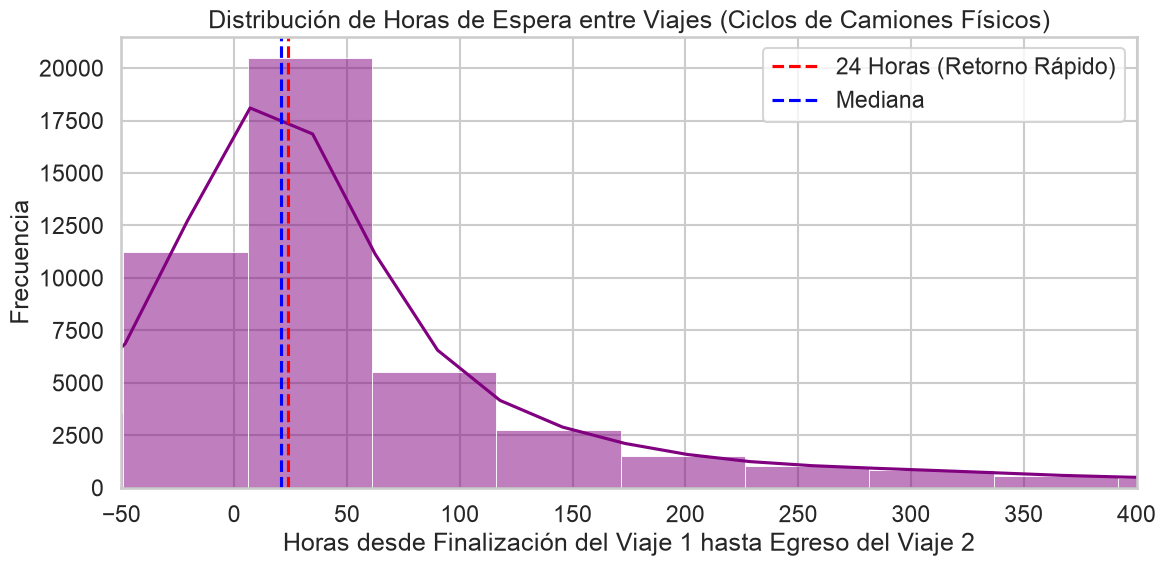

In [ ]:
# 4. Análisis de Backhaul y Ciclos
df = df.sort_values(['Placas', 'FECHA_EGRESO']).reset_index(drop=True)

df['Siguiente_Placa'] = df['Placas'].shift(-1)
df['Siguiente_Origen'] = df['PLANTA_ORIGEN'].shift(-1)
df['Siguiente_Egreso'] = df['FECHA_EGRESO'].shift(-1)
df['Siguiente_Destino'] = df['Ciudad Destino'].shift(-1)

df['Es_Misma_Placa'] = (df['Placas'] == df['Siguiente_Placa'])
df['Horas_Espera_Nuevo_Viaje'] = np.where(
    df['Es_Misma_Placa'], 
    (df['Siguiente_Egreso'] - df['FECHA_VIAJE_FINALIZADO']).dt.total_seconds() / 3600, 
    np.nan
)

viajes_secuenciales = df[df['Es_Misma_Placa']].copy()

print(f"\nTotal de conexiones entre viajes analizadas: {len(viajes_secuenciales)}")
print("Estadísticas de horas de espera entre un viaje y otro de la misma placa:")
print(viajes_secuenciales['Horas_Espera_Nuevo_Viaje'].describe())

backhauls_potenciales = viajes_secuenciales[viajes_secuenciales['Horas_Espera_Nuevo_Viaje'] <= 24]
print(f"Viajes con espera menor a 24h (Potencial Backhaul o triángulo eficiente): {len(backhauls_potenciales)}")

# Generación de la gráfica
plt.figure(figsize=(12, 6))
sns.histplot(viajes_secuenciales['Horas_Espera_Nuevo_Viaje'].dropna(), bins=100, color='purple', kde=True)
plt.xlim(-50, 400)
plt.axvline(24, color='red', linestyle='--', label='24 Horas (Retorno Rápido)')
plt.axvline(viajes_secuenciales['Horas_Espera_Nuevo_Viaje'].median(), color='blue', linestyle='--', label='Mediana')
plt.title('Distribución de Horas de Espera entre Viajes (Ciclos de Camiones Físicos)')
plt.xlabel('Horas desde Finalización del Viaje 1 hasta Egreso del Viaje 2')
plt.ylabel('Frecuencia')
plt.legend()
plt.tight_layout()
#plt.savefig('ciclos_placas.png')
#print("Gráfica ciclos_placas.png generada.")

viajes_secuenciales['Retorno_A_Base'] = viajes_secuenciales['PLANTA_ORIGEN'] == viajes_secuenciales['Siguiente_Origen']
print(f"\nCamión regresó y cargó de nuevo en la misma Planta de Origen: {viajes_secuenciales['Retorno_A_Base'].mean()*100:.1f}% de las veces")

In [20]:
# 5. Preparación de variables para el Modelo Econométrico
df = df.rename(columns={
    'Monto total': 'Costo',
    'Programado_kg': 'Peso_Programado',
    'Ciudad Destino': 'Destino'
})

df['Ruta'] = df['PLANTA_ORIGEN'] + "_" + df['Destino']

mascara_portacintas = df['FAMILIA_CAMION_DESC'].astype(str).str.contains('PORTACINTA|BIG COIL', case=False, na=False)
df['Camion'] = np.where(mascara_portacintas, 'T3_S3_Portacintas', df['Nomenclatura_Inferida'])

mapeo_camiones = {
    'T3-S2-R4 (Full)': 'Full',
    'T3-S3 (3 Ejes)': 'Tres_Ejes',
    'T3-S2 (2 Ejes)': 'Dos_Ejes',
    'Torton': 'Torton',
    'T3_S3_Portacintas': 'Portacintas'
}
df['Camion'] = df['Camion'].map(mapeo_camiones)

df_reg = df.dropna(subset=['Costo', 'Peso_Programado', 'Camion', 'Ruta']).copy()
top_rutas = df_reg['Ruta'].value_counts().head(50).index 
df_model = df_reg[df_reg['Ruta'].isin(top_rutas)].copy()

print(f"Viajes en las Top 50 Rutas: {len(df_model)}")

Viajes en las Top 50 Rutas: 31803


In [21]:
# 6. Ejecución del Modelo OLS (Unificado para evitar doble entrenamiento)
formula = "Costo ~ C(Camion, Treatment(reference='Tres_Ejes')) + Peso_Programado + C(Ruta)"
modelo = smf.ols(formula, data=df_model).fit()

resultados = pd.DataFrame({
    'Efecto_Marginal_MXN': modelo.params,
    'Lim_Inf_95': modelo.conf_int()[0],
    'Lim_Sup_95': modelo.conf_int()[1],
    'P_Value': modelo.pvalues
})

res_camiones = resultados[resultados.index.str.contains('Camion')].copy()
res_camiones.index = res_camiones.index.str.replace("C(Camion, Treatment(reference='Tres_Ejes'))[T.", "", regex=False).str.replace("]", "", regex=False)

print("\n--- IMPACTO CAUSAL DEL TIPO DE CAMIÓN SOBRE EL COSTO (Controlando por Ruta) ---")
print("Base de comparación: Tres_Ejes (El coeficiente muestra cuánto MÁS o MENOS cuesta usar este camión frente a un 3 Ejes, en la MISMA ruta)")
print(res_camiones.round(2).to_markdown())

coexistencia = df_model.groupby('Ruta')['Camion'].nunique()
print(f"\nRutas con más de 1 tipo de camión operando simultáneamente: {(coexistencia > 1).sum()} de 50")


--- IMPACTO CAUSAL DEL TIPO DE CAMIÓN SOBRE EL COSTO (Controlando por Ruta) ---
Base de comparación: Tres_Ejes (El coeficiente muestra cuánto MÁS o MENOS cuesta usar este camión frente a un 3 Ejes, en la MISMA ruta)
|             |   Efecto_Marginal_MXN |   Lim_Inf_95 |   Lim_Sup_95 |   P_Value |
|:------------|----------------------:|-------------:|-------------:|----------:|
| Dos_Ejes    |              -6059.85 |     -6195.07 |     -5924.62 |         0 |
| Full        |               5873.08 |      5636.94 |      6109.21 |         0 |
| Portacintas |               1058.43 |       944.97 |      1171.89 |         0 |

Rutas con más de 1 tipo de camión operando simultáneamente: 44 de 50


In [23]:
# 7. Análisis de Sensibilidad Causal (Falsificación) extraída del modelo ya entrenado
coef_2ejes = modelo.params["C(Camion, Treatment(reference='Tres_Ejes'))[T.Dos_Ejes]"]
se_2ejes = modelo.bse["C(Camion, Treatment(reference='Tres_Ejes'))[T.Dos_Ejes]"]

t_stat = coef_2ejes / se_2ejes
df_resid = modelo.df_resid
r2_parcial = (t_stat**2) / ((t_stat**2) + df_resid)
rv_aprox = np.sqrt(r2_parcial)

print("\n--- ANÁLISIS DE SENSIBILIDAD CAUSAL (FALSIFICACIÓN) ---")
print(f"Coeficiente original (Ahorro 2 Ejes): ${abs(coef_2ejes):.2f} MXN")
print(f"R-Cuadrado Parcial del Camión 2 Ejes: {r2_parcial*100:.4f}%")
print(f"Valor de Robustez (RV_q=1): {rv_aprox*100:.2f}%")

rmse = np.sqrt(modelo.mse_resid)
d = abs(coef_2ejes) / rmse
term = np.exp(0.91 * d)
e_value = term + np.sqrt(term * (term - 1))

print(f"\nValor-E (E-Value) de VanderWeele: {e_value:.2f}")
print(f"RMSE (Desviación Estándar de los residuales): ${rmse:.2f} MXN")

# 8. Simulación de Línea Base
df_base = df.dropna(subset=['Costo', 'Toneladas_Reales']).copy()
total_viajes = len(df_base)
costo_total_mxn = df_base['Costo'].sum()
toneladas_totales = df_base['Toneladas_Reales'].sum()

print("\n" + "="*50)
print("FASE 1: SIMULACIÓN DE LÍNEA BASE (HISTÓRICO 2026)")
print("="*50)
print(f"Total de Viajes Analizados:   {total_viajes:,.0f} fletes")
print(f"Volumen Total Transportado:   {toneladas_totales:,.2f} Toneladas")
print("-" * 50)
print(f"GASTO TOTAL LOGÍSTICO:        ${costo_total_mxn / 1e6:,.2f} Millones de MXN")
print("-" * 50)
print(f"Costo Promedio por Viaje:     ${costo_total_mxn / total_viajes:,.2f} MXN")
print(f"Costo Promedio por Tonelada:  ${costo_total_mxn / toneladas_totales:,.2f} MXN")
print("="*50)


--- ANÁLISIS DE SENSIBILIDAD CAUSAL (FALSIFICACIÓN) ---
Coeficiente original (Ahorro 2 Ejes): $6059.85 MXN
R-Cuadrado Parcial del Camión 2 Ejes: 19.5495%
Valor de Robustez (RV_q=1): 44.21%

Valor-E (E-Value) de VanderWeele: 13.89
RMSE (Desviación Estándar de los residuales): $2793.02 MXN

FASE 1: SIMULACIÓN DE LÍNEA BASE (HISTÓRICO 2026)
Total de Viajes Analizados:   55,388 fletes
Volumen Total Transportado:   1,648,920.05 Toneladas
--------------------------------------------------
GASTO TOTAL LOGÍSTICO:        $1,343.59 Millones de MXN
--------------------------------------------------
Costo Promedio por Viaje:     $24,257.79 MXN
Costo Promedio por Tonelada:  $814.83 MXN


In [6]:
df_base = df.dropna(subset=['Costo', 'Toneladas_Reales']).copy()
total_viajes = len(df_base)
costo_total_mxn = df_base['Costo'].sum()
toneladas_totales = df_base['Toneladas_Reales'].sum()

costo_promedio_viaje = costo_total_mxn / total_viajes
costo_promedio_tonelada = costo_total_mxn / toneladas_totales

# 4. Imprimir el Reporte de Línea Base
print("="*50)
print("FASE 1: SIMULACIÓN DE LÍNEA BASE (HISTÓRICO 2026)")
print("="*50)
print(f"Total de Viajes Analizados:   {total_viajes:,.0f} fletes")
print(f"Volumen Total Transportado:   {toneladas_totales:,.2f} Toneladas")
print("-" * 50)
print(f"GASTO TOTAL LOGÍSTICO:        ${costo_total_mxn / 1e6:,.2f} Millones de MXN")
print("-" * 50)
print(f"Costo Promedio por Viaje:     ${costo_promedio_viaje:,.2f} MXN")
print(f"Costo Promedio por Tonelada:  ${costo_promedio_tonelada:,.2f} MXN")
print("="*50)

FASE 1: SIMULACIÓN DE LÍNEA BASE (HISTÓRICO 2026)
Total de Viajes Analizados:   55,388 fletes
Volumen Total Transportado:   1,648,920.05 Toneladas
--------------------------------------------------
GASTO TOTAL LOGÍSTICO:        $1,343.59 Millones de MXN
--------------------------------------------------
Costo Promedio por Viaje:     $24,257.79 MXN
Costo Promedio por Tonelada:  $814.83 MXN



--- RESUMEN DE CLUSTERS DE DESTINO ---
|   Cluster |   Ciudades |   Viajes_Totales |   Costo_Promedio |   Distancia_Promedio |
|----------:|-----------:|-----------------:|-----------------:|---------------------:|
|         0 |        116 |            17579 |          36896.2 |               622.99 |
|         1 |        121 |             5984 |          14439.2 |               366.86 |
|         2 |         40 |             3520 |          48720.3 |              1811.07 |
|         3 |          7 |            24288 |          14947.1 |               617.05 |
Cluster 0 (Ejemplos): ['Acapulco', 'Acatlán', 'Acatzingo']
Cluster 1 (Ejemplos): ['Acajete', 'Acayucan', 'Acolman']
Cluster 2 (Ejemplos): ['Alamo', 'Allende', 'Atizapan']
Cluster 3 (Ejemplos): ['Altamira', 'Castaños', 'Ciudad Frontera']


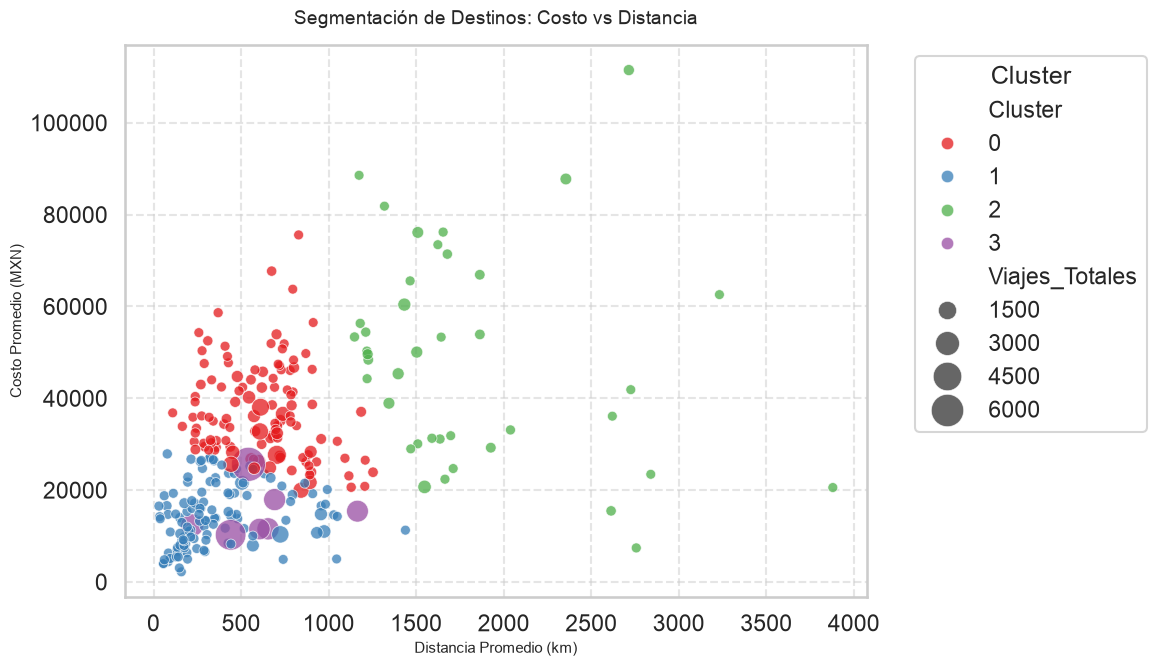

In [ ]:
# 9. Agrupación y preparación de datos por Ciudad Destino
resumen_destinos = df_base.groupby('Destino').agg(
    Viajes_Totales=('ID_VIAJE', 'count'),
    Costo_Promedio=('Costo', 'mean'),
    Distancia_Promedio=('Kilometros_Ruta', 'mean')
).reset_index()

resumen_destinos = resumen_destinos.dropna()

# 10. Escalamiento de variables y aplicación del modelo K-Means
scaler = StandardScaler()
variables_cluster = ['Viajes_Totales', 'Costo_Promedio', 'Distancia_Promedio']
datos_escalados = scaler.fit_transform(resumen_destinos[variables_cluster])

# Se configuran 4 clusters basándonos en tu output previo
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
resumen_destinos['Cluster'] = kmeans.fit_predict(datos_escalados)

# 11. Generación de tabla de resumen general
resumen_clusters = resumen_destinos.groupby('Cluster').agg(
    Ciudades=('Destino', 'count'),
    Viajes_Totales=('Viajes_Totales', 'sum'),
    Costo_Promedio=('Costo_Promedio', 'mean'),
    Distancia_Promedio=('Distancia_Promedio', 'mean')
).reset_index()

print("\n--- RESUMEN DE CLUSTERS DE DESTINO ---")
print(resumen_clusters.round(2).to_markdown(index=False))

# Muestreo de ciudades representativas por cluster
for c in range(4):
    ejemplos = resumen_destinos[resumen_destinos['Cluster'] == c]['Destino'].head(3).tolist()
    print(f"Cluster {c} (Ejemplos): {ejemplos}")
    
# 12. Visualización gráfica de los Clusters
plt.figure(figsize=(12, 7))
sns.scatterplot(
    data=resumen_destinos, 
    x='Distancia_Promedio', 
    y='Costo_Promedio', 
    hue='Cluster', 
    size='Viajes_Totales',
    sizes=(50, 600),
    palette='Set1',
    alpha=0.75
)

plt.title('Segmentación de Destinos: Costo vs Distancia', fontsize=14, pad=15)
plt.xlabel('Distancia Promedio (km)', fontsize=11)
plt.ylabel('Costo Promedio (MXN)', fontsize=11)

# Ajuste de leyenda para no obstruir los datos
plt.legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

# Guardar y mostrar el gráfico
#plt.savefig('clusters_destino.png', dpi=300)
plt.show()

In [31]:
# 13. Integración de los clusters al dataframe original para análisis predictivos posteriores
df_base = df_base.merge(resumen_destinos[['Destino', 'Cluster']], on='Destino', how='left')

In [32]:
# Recrear el Clustering para la variable predictora
df = df.dropna(subset=['Costo', 'Peso_Programado', 'Destino', 'Kilometros_Ruta', 'FECHA_EGRESO'])

destinos = df.groupby('Destino').agg({'ID_VIAJE':'count', 'Costo':'mean', 'Kilometros_Ruta':'mean'}).reset_index()
X_c = StandardScaler().fit_transform(destinos[['ID_VIAJE', 'Costo', 'Kilometros_Ruta']])
destinos['Cluster_Destino'] = KMeans(n_clusters=4, random_state=42, n_init=10).fit_predict(X_c)

# Borrar la columna vieja si ya existe para evitar el MergeError
if 'Cluster_Destino' in df.columns:
    df = df.drop(columns=['Cluster_Destino'])

df = df.merge(destinos[['Destino', 'Cluster_Destino']], on='Destino', how='left')

# Limpiar variables categóricas
mascara_portacintas = df['FAMILIA_CAMION_DESC'].astype(str).str.contains('PORTACINTA|BIG COIL', case=False, na=False)
df['Camion'] = np.where(mascara_portacintas, 'T3_S3_Portacintas', df['Nomenclatura_Inferida'])
df['Camion'] = df['Camion'].fillna('Otro')

# Partición Temporal Estricta
df['FECHA_EGRESO'] = pd.to_datetime(df['FECHA_EGRESO'])
df['Mes'] = df['FECHA_EGRESO'].dt.month
df = df.sort_values('FECHA_EGRESO')

# Verificar distribución de meses para hacer el split (Train: Ene-Ago, Val: Sep, Test: Oct-Dic)
train_mask = df['Mes'] <= 8
val_mask = df['Mes'] == 9
test_mask = df['Mes'] >= 10

if len(df[test_mask]) < 1000: # Si la data no abarca el año completo, usamos split por posición 75-10-15
    n = len(df)
    df_train = df.iloc[:int(n * 0.75)]
    df_val = df.iloc[int(n * 0.75):int(n * 0.85)]
    df_test = df.iloc[int(n * 0.85):]
else:
    df_train = df[train_mask]
    df_val = df[val_mask]
    df_test = df[test_mask]

# 5. Configurar Pipeline de Scikit-Learn
features = ['Peso_Programado', 'Kilometros_Ruta', 'Cluster_Destino', 'Camion', 'PLANTA_ORIGEN']
target = 'Costo'

X_train, y_train = df_train[features], df_train[target]
X_val, y_val = df_val[features], df_val[target]
X_test, y_test = df_test[features], df_test[target]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), ['Peso_Programado', 'Kilometros_Ruta']),
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['Camion', 'PLANTA_ORIGEN', 'Cluster_Destino'])
    ])

# Instanciar Random Forest (Controlando profundidad para evitar sobreajuste en nodos terminales)
rf = RandomForestRegressor(n_estimators=150, max_depth=15, min_samples_leaf=4, random_state=42, n_jobs=-1)
pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('model', rf)])

# 6. Entrenamiento y Predicción
pipeline.fit(X_train, y_train)
preds_val = pipeline.predict(X_val)
preds_test = pipeline.predict(X_test)

# 7. Evaluación
r2 = r2_score(y_test, preds_test)
rmse = np.sqrt(mean_squared_error(y_test, preds_test))

costo_real_test = y_test.sum()
costo_pred_test = preds_test.sum()
diferencia_pct = ((costo_pred_test - costo_real_test) / costo_real_test) * 100

print(f"Set de Entrenamiento: {len(X_train):,} viajes")
print(f"Set de Validación:    {len(X_val):,} viajes")
print(f"Set de Prueba (Test): {len(X_test):,} viajes")

print("\n--- MÉTRICAS DEL RANDOM FOREST (En Set de Prueba) ---")
print(f"R² (Varianza explicada): {r2:.4f}")
print(f"RMSE (Error promedio):   ${rmse:,.2f} MXN por viaje")

print("\n--- FASE 1: VALIDACIÓN FINANCIERA DE LA LÍNEA BASE ---")
print(f"Gasto Real en el periodo de Prueba:      ${costo_real_test/1e6:,.2f} Millones MXN")
print(f"Gasto Simulado (Suma de predicciones):   ${costo_pred_test/1e6:,.2f} Millones MXN")
print(f"Varianza del Simulador vs Realidad:      {diferencia_pct:+.2f}%")

Set de Entrenamiento: 28,291 viajes
Set de Validación:    3,772 viajes
Set de Prueba (Test): 5,659 viajes

--- MÉTRICAS DEL RANDOM FOREST (En Set de Prueba) ---
R² (Varianza explicada): 0.9427
RMSE (Error promedio):   $3,985.16 MXN por viaje

--- FASE 1: VALIDACIÓN FINANCIERA DE LA LÍNEA BASE ---
Gasto Real en el periodo de Prueba:      $127.75 Millones MXN
Gasto Simulado (Suma de predicciones):   $124.19 Millones MXN
Varianza del Simulador vs Realidad:      -2.78%


In [8]:
# Propósito: Ajuste de hiperparámetros del Random Forest con RandomizedSearchCV (20 combinaciones), evaluando
# siempre en el bloque de validación para no mezclar periodos.
# 1. Unir entrenamiento y validación: la búsqueda recibe un solo conjunto y PredefinedSplit indica qué parte valida.
X_train_val = pd.concat([X_train, X_val], axis=0)
y_train_val = pd.concat([y_train, y_val], axis=0)

# 2. Crear el PredefinedSplit (Train = -1, Val = 0) para respetar el tiempo
# Esto obliga al modelo a no mezclar el futuro con el pasado en el cross-validation
test_fold = np.concatenate([
    np.full(len(X_train), -1),  # -1 significa "usar solo para entrenar"
    np.zeros(len(X_val))        # 0 significa "usar para evaluar en la iteración"
])
ps = PredefinedSplit(test_fold)

# 3. Definir la malla de hiperparámetros (nota el prefijo 'model__' por el Pipeline)
param_dist = {
    'model__n_estimators': [100, 200, 300, 400],
    'model__max_depth': [10, 15, 20, 25, None],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [2, 4, 8],
    'model__max_features': ['sqrt', 'log2', None]
}

# 4. Configurar la Búsqueda Aleatoria (RandomizedSearchCV)
# Usaremos 20 iteraciones para no saturar tu memoria RAM
random_search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_dist,
    n_iter=20,
    scoring='neg_root_mean_squared_error',
    cv=ps,
    random_state=42,
    n_jobs=-1,
    verbose=2
)

# 5. Ejecutar el Fine-Tuning
print("Iniciando búsqueda de hiperparámetros...")
random_search.fit(X_train_val, y_train_val)

# 6. Extraer el mejor modelo y evaluar en el set de Prueba (Oct-Dic)
best_pipeline = random_search.best_estimator_
preds_test_best = best_pipeline.predict(X_test)

# Métricas finales
from sklearn.metrics import mean_squared_error, r2_score
r2_best = r2_score(y_test, preds_test_best)
rmse_best = np.sqrt(mean_squared_error(y_test, preds_test_best))

costo_real_test = y_test.sum()
costo_pred_test_best = preds_test_best.sum()
dif_pct_best = ((costo_pred_test_best - costo_real_test) / costo_real_test) * 100

print("\n=== RESULTADOS DEL FINE-TUNING ===")
print("Mejores Hiperparámetros encontrados:")
for param, value in random_search.best_params_.items():
    print(f" - {param}: {value}")

print("\n--- MÉTRICAS DEL RANDOM FOREST AFINADO (En Set de Prueba) ---")
print(f"R²: {r2_best:.4f}")
print(f"RMSE: ${rmse_best:,.2f} MXN por viaje")
print(f"Varianza Financiera Simulada vs Realidad: {dif_pct_best:+.2f}%")

Iniciando búsqueda de hiperparámetros...
Fitting 1 folds for each of 20 candidates, totalling 20 fits
[CV] END model__max_depth=20, model__max_features=sqrt, model__min_samples_leaf=4, model__min_samples_split=2, model__n_estimators=200; total time=  33.5s
[CV] END model__max_depth=10, model__max_features=None, model__min_samples_leaf=2, model__min_samples_split=5, model__n_estimators=200; total time=  42.5s
[CV] END model__max_depth=10, model__max_features=None, model__min_samples_leaf=2, model__min_samples_split=2, model__n_estimators=200; total time=  43.6s
[CV] END model__max_depth=10, model__max_features=None, model__min_samples_leaf=4, model__min_samples_split=2, model__n_estimators=300; total time=  59.3s
[CV] END model__max_depth=10, model__max_features=sqrt, model__min_samples_leaf=2, model__min_samples_split=5, model__n_estimators=300; total time=  18.6s
[CV] END model__max_depth=None, model__max_features=log2, model__min_samples_leaf=2, model__min_samples_split=2, model__n_e

In [9]:
# Propósito: Modelo de comparación (XGBoost). Mismas variables y preprocesamiento que el Random Forest, pero
# entrenado solo con el set de entrenamiento y con hiperparámetros fijos (sin ajuste).
xgb_model = xgb.XGBRegressor(
    # 400 árboles en secuencia; cada uno corrige el error de los anteriores, escalado por learning_rate.
    # subsample y colsample_bytree: fracción de viajes y de columnas que ve cada árbol.
    n_estimators=400,
    learning_rate=0.05,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

# Reutilizamos el 'preprocessor' del bloque anterior
pipeline_xgb = Pipeline(steps=[('preprocessor', preprocessor), ('model', xgb_model)])

print("Entrenando XGBoost con datos de Ene-Sep...")
pipeline_xgb.fit(X_train, y_train)

# Predicción exclusiva en el set de Prueba (Oct-Dic)
preds_test_xgb = pipeline_xgb.predict(X_test)

# Evaluación
r2_xgb = r2_score(y_test, preds_test_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test, preds_test_xgb))

costo_pred_test_xgb = preds_test_xgb.sum()
dif_pct_xgb = ((costo_pred_test_xgb - costo_real_test) / costo_real_test) * 100

print("\n--- MÉTRICAS DE XGBOOST (En Set de Prueba) ---")
print(f"R²: {r2_xgb:.4f}")
print(f"RMSE: ${rmse_xgb:,.2f} MXN por viaje")
print(f"Gasto Simulado (XGBoost): ${costo_pred_test_xgb/1e6:,.2f} Millones MXN")
print(f"Varianza Financiera Simulada vs Realidad: {dif_pct_xgb:+.2f}%")

Entrenando XGBoost con datos de Ene-Sep...

--- MÉTRICAS DE XGBOOST (En Set de Prueba) ---
R²: 0.9387
RMSE: $4,121.65 MXN por viaje
Gasto Simulado (XGBoost): $123.80 Millones MXN
Varianza Financiera Simulada vs Realidad: -3.09%


In [10]:
# 1. Clonar el set de prueba (Octubre - Diciembre) para no alterar el original
X_test_opt = X_test.copy()
X_test_opt['Camion_Historico'] = X_test_opt['Camion']

# 2. Definir límite físico legal con holgura (30.4 toneladas)
limite_2_ejes_kg = 30400

# 3. Aplicar Motor Físico de Optimización (Right-Sizing) usando los nombres correctos
# A. Bajar cargas de 3 Ejes a 2 Ejes (Ahorro)
mascara_ahorro = (X_test_opt['Camion'] == 'T3-S3 (3 Ejes)') & (X_test_opt['Peso_Programado'] <= limite_2_ejes_kg)
X_test_opt.loc[mascara_ahorro, 'Camion'] = 'T3-S2 (2 Ejes)'

# B. Subir cargas de 2 Ejes a 3 Ejes (Mitigación de Riesgo / Compliance)
mascara_riesgo = (X_test_opt['Camion'] == 'T3-S2 (2 Ejes)') & (X_test_opt['Peso_Programado'] > limite_2_ejes_kg)
X_test_opt.loc[mascara_riesgo, 'Camion'] = 'T3-S3 (3 Ejes)'

# 4. Motor Financiero: Re-cotizar el trimestre usando el Random Forest
costos_optimizados = best_pipeline.predict(X_test_opt.drop(columns=['Camion_Historico']))

# 5. Calcular Impactos
viajes_optimizados_ahorro = mascara_ahorro.sum()
viajes_mitigados_riesgo = mascara_riesgo.sum()

costo_base_simulado = preds_test_best.sum()       # Lo que predijo que costaría originalmente (Línea Base)
costo_nuevo_simulado = costos_optimizados.sum()   # Lo que cuesta con la nueva política
ahorro_neto = costo_base_simulado - costo_nuevo_simulado
porcentaje_ahorro = (ahorro_neto / costo_base_simulado) * 100

print("=== FASE 2: RESULTADOS DE LA SIMULACIÓN DE RIGHT-SIZING (Q4 2026) ===")
print(f"Viajes reasignados a 2 Ejes (Ahorro):           {viajes_optimizados_ahorro:,} viajes")
print(f"Viajes reasignados a 3 Ejes (Gestión de Riesgo):{viajes_mitigados_riesgo:,} viajes")
print("-" * 65)
print(f"Gasto Trimestral Proyectado (Línea Base):       ${costo_base_simulado/1e6:,.2f} Millones MXN")
print(f"Gasto Trimestral Optimizado (Right-Sizing):     ${costo_nuevo_simulado/1e6:,.2f} Millones MXN")
print("-" * 65)
print(f"AHORRO NETO COMPROBADO:                         ${ahorro_neto/1e6:,.2f} Millones MXN")
print(f"REDUCCIÓN DEL PRESUPUESTO LOGÍSTICO (Trimestral):{porcentaje_ahorro:.2f}%")

=== FASE 2: RESULTADOS DE LA SIMULACIÓN DE RIGHT-SIZING (Q4 2026) ===
Viajes reasignados a 2 Ejes (Ahorro):           1,420 viajes
Viajes reasignados a 3 Ejes (Gestión de Riesgo):3 viajes
-----------------------------------------------------------------
Gasto Trimestral Proyectado (Línea Base):       $124.45 Millones MXN
Gasto Trimestral Optimizado (Right-Sizing):     $123.34 Millones MXN
-----------------------------------------------------------------
AHORRO NETO COMPROBADO:                         $1.11 Millones MXN
REDUCCIÓN DEL PRESUPUESTO LOGÍSTICO (Trimestral):0.89%


Iniciando Bootstrap Predictivo con 1000 simulaciones (remuestreando 685 rutas)...


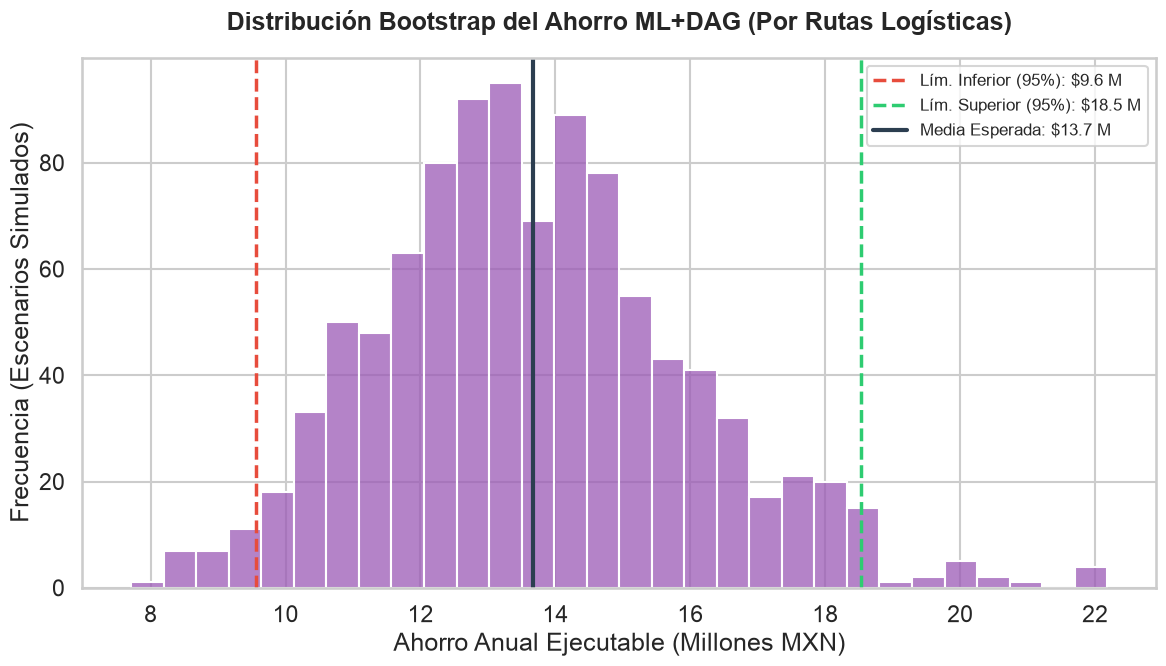

--- RESULTADOS DEL BOOTSTRAP PREDICTIVO (ML + DAG) ---
>> Intervalo de Confianza (95%): $9.56 M a $18.53 M MXN.
>> Ahorro Anual Esperado: $13.67 Millones de MXN.


In [12]:
# Preparar el dataset completo para proyectar el año
df_sim = df.copy()
df_sim['Ruta_ID'] = df_sim['PLANTA_ORIGEN'] + " - " + df_sim['Destino']
df_sim['Ahorro_Ejecutable'] = 0.0

# MOTOR FÍSICO Y CAUSAL (Reglas estrictas del DAG)
# A) Encontrar viajes ineficientes (3 Ejes que caben en 2 Ejes)
candidatos_ahorro = (df_sim['Camion'] == 'T3-S3 (3 Ejes)') & (df_sim['Peso_Programado'] <= 30400)
df_ahorro = df_sim[candidatos_ahorro].copy()
df_ahorro['Camion'] = 'T3-S2 (2 Ejes)' # Aplicar política

# Predecir costo exacto con Random Forest
costos_optimos = best_pipeline.predict(df_ahorro)
df_ahorro['Ahorro_ML'] = df_ahorro['Costo'] - costos_optimos

# Filtro financiero: Solo ejecutar si el ahorro es real (positivo)
df_ahorro['Ahorro_ML'] = df_ahorro['Ahorro_ML'].clip(lower=0)
df_sim.loc[candidatos_ahorro, 'Ahorro_Ejecutable'] = df_ahorro['Ahorro_ML']

# B) Mitigación de Riesgo (2 Ejes sobrecargados que deben subir a 3 Ejes)
candidatos_riesgo = (df_sim['Camion'] == 'T3-S2 (2 Ejes)') & (df_sim['Peso_Programado'] > 30400)
df_riesgo = df_sim[candidatos_riesgo].copy()
df_riesgo['Camion'] = 'T3-S3 (3 Ejes)' # Aplicar compliance

costos_riesgo = best_pipeline.predict(df_riesgo)
df_riesgo['Sobrecosto'] = costos_riesgo - df_riesgo['Costo']
# Restar este sobrecosto del ahorro total
df_sim.loc[candidatos_riesgo, 'Ahorro_Ejecutable'] = -df_riesgo['Sobrecosto'].clip(lower=0)

# 3. MOTOR DE BOOTSTRAP POR CONGLOMERADOS (Ruta_ID)
ahorro_por_ruta = df_sim.groupby('Ruta_ID')['Ahorro_Ejecutable'].sum()

B = 1000
ahorros_totales = []
rutas_unicas = df_sim['Ruta_ID'].unique()
n_clusters = len(rutas_unicas)

print(f"Iniciando Bootstrap Predictivo con {B} simulaciones (remuestreando {n_clusters} rutas)...")
np.random.seed(42)

for _ in range(B):
    rutas_muestra = np.random.choice(rutas_unicas, size=n_clusters, replace=True)
    rutas_counts = pd.Series(rutas_muestra).value_counts()
    suma_iteracion = sum(ahorro_por_ruta.get(ruta, 0) * conteo for ruta, conteo in rutas_counts.items())
    ahorros_totales.append(suma_iteracion)

# 4. MÉTRICAS Y VISUALIZACIÓN
ahorros_millones = np.array(ahorros_totales) / 1e6
limite_inf = np.percentile(ahorros_millones, 2.5)
limite_sup = np.percentile(ahorros_millones, 97.5)
media_boot = np.mean(ahorros_millones)

plt.figure(figsize=(12, 7))
sns.set_theme(style="whitegrid", context="talk")
sns.histplot(ahorros_millones, bins=30, color='#9b59b6', edgecolor='white')

plt.axvline(limite_inf, color='#e74c3c', linestyle='--', linewidth=2.5, label=f'Lím. Inferior (95%): ${limite_inf:.1f} M')
plt.axvline(limite_sup, color='#2ecc71', linestyle='--', linewidth=2.5, label=f'Lím. Superior (95%): ${limite_sup:.1f} M')
plt.axvline(media_boot, color='#2c3e50', linestyle='-', linewidth=3, label=f'Media Esperada: ${media_boot:.1f} M')

plt.title('Distribución Bootstrap del Ahorro ML+DAG (Por Rutas Logísticas)', fontweight='bold', pad=20, fontsize=18)
plt.xlabel('Ahorro Anual Ejecutable (Millones MXN)')
plt.ylabel('Frecuencia (Escenarios Simulados)')
plt.legend(frameon=True, fontsize=12)
plt.tight_layout()
plt.show()

print("--- RESULTADOS DEL BOOTSTRAP PREDICTIVO (ML + DAG) ---")
print(f">> Intervalo de Confianza (95%): ${limite_inf:.2f} M a ${limite_sup:.2f} M MXN.")
print(f">> Ahorro Anual Esperado: ${media_boot:.2f} Millones de MXN.")